# RAG Baseline vs. Cross-Encoder Re-Ranking on the EU AI Act

**Assignment.** Compare two Retrieval-Augmented Generation (RAG) pipelines over one complex PDF and study where a cross-encoder re-ranker changes the outcome.

**Document.** Regulation (EU) 2024/1689 (the *Artificial Intelligence Act*), official Journal version, 144 pages (`data/eu_ai_act_2024_1689.pdf`). It has recitals, 113 articles and 13 annexes, which makes it full of exceptions ("except where"), prohibitions, role-specific duties and numeric thresholds.

**Models.**
- Bi-encoder (retrieval): `sentence-transformers/all-MiniLM-L6-v2`
- Cross-encoder (re-ranking): `cross-encoder/ms-marco-MiniLM-L-6-v2`
- Generator: a local LLM served by Ollama (`qwen2.5:7b`), temperature 0, fixed seed.

**Pipelines.**

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| Stage 1 | bi-encoder + FAISS inner-product search, Top 10 | identical Top 10 |
| Stage 2 | take Top 3 by bi-encoder score | score all 10 (query, chunk) pairs with the cross-encoder, re-sort, take Top 3 |
| Stage 3 | identical prompt template, same LLM and decoding settings | identical |

**Notebook layout.** 1 config, 2 PDF cleaning, 3 chunking, 4 indexing, 5-7 pipelines and prompt, 8 query set with gold labels, 9 retrieval experiment, 10 answer generation, 11 failure deep dives, 12 latency, 13 scaling, 14 figures, 15 reproducibility check.

The markdown cells only describe *what* each step does and *why*; the interpretation of the results is written separately in the report.

### References

- Reimers, N. and Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* EMNLP-IJCNLP.
- Nogueira, R. and Cho, K. (2019). *Passage Re-ranking with BERT.* arXiv:1901.04085.
- Nguyen, T. et al. (2016). *MS MARCO: A Human Generated MAchine Reading COmprehension Dataset.* NeurIPS Workshop on Cognitive Computation.
- Wang, W. et al. (2020). *MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers.* NeurIPS.
- Karpukhin, V. et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP.
- Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS.

## 1. Configuration

All tunable settings live in one cell so that every later cell reads the same values. Paths are relative to the notebook folder. `MAX_CHUNK_TOKENS` is set below the bi-encoder limit of 256 word-pieces so that the chunk header plus body is never truncated by the encoder.

**Concept: one place for settings.** A result can only be trusted if it can be reproduced. So every setting (model names, k values, seed, paths) lives in one cell, the random seeds are fixed, and the plotting style is set once so that all figures look the same.

In [1]:
import os

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # no progress-bar widgets in the saved notebook

import sys, re, json, time, random, math, collections, warnings

from pathlib import Path

import numpy as np

import pandas as pd

import torch

# ----- paths (relative to the notebook directory) -----
DATA_DIR    = Path("data")

PDF_PATH    = DATA_DIR / "eu_ai_act_2024_1689.pdf"

RESULTS_DIR = Path("results")

FIG_DIR     = RESULTS_DIR / "figures"

for d in (RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ----- models -----
BI_ENCODER    = "sentence-transformers/all-MiniLM-L6-v2"

CROSS_ENCODER = "cross-encoder/ms-marco-MiniLM-L-6-v2"

# ----- retrieval / prompt sizes -----
TOP_K_RETRIEVE   = 10    # candidates fetched by the bi-encoder

TOP_K_CONTEXT    = 3     # chunks that are put into the LLM prompt

MAX_CHUNK_TOKENS = 230   # header + body, measured with the bi-encoder tokenizer

BI_MAX_SEQ       = 256   # all-MiniLM-L6-v2 truncates after 256 word-pieces

# ----- generator -----
LLM_BACKEND      = "ollama"        # "ollama" or "gemini"

OLLAMA_MODEL     = "qwen2.5:7b"    # fallback if unavailable: "gemma3:4b"

FORCE_REGENERATE = False           # True = ignore the answer cache

SEED   = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)





if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)

pd.set_option("display.max_colwidth", 120)

pd.set_option("display.width", 200)

pd.set_option("display.max_rows", 200)

warnings.filterwarnings("ignore", category=FutureWarning)

# ----- environment report -----
import transformers, faiss

try:
    import sentence_transformers, fitz
    st_version, fitz_version = sentence_transformers.__version__, (getattr(fitz, "__version__", None) or fitz.VersionBind)
except ImportError as e:
    raise SystemExit(f"Missing dependency: {e}. Run: pip install -r requirements.txt")

print("python               :", sys.version.split()[0])

print("torch                :", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU")

print("transformers         :", transformers.__version__)

print("sentence-transformers:", st_version)

print("faiss                :", faiss.__version__)

print("PyMuPDF              :", fitz_version)

print("pandas / numpy       :", pd.__version__, "/", np.__version__)

# ----- global plotting style (used by every figure) -----
import matplotlib as mpl

import matplotlib.pyplot as plt

import matplotlib.font_manager as fm

import seaborn as sns

C_BASE, C_RERANK, C_NEUTRAL = "#6C788C", "#1F7A74", "#B9BEC6"   # baseline / re-ranked / unchanged

C_UP, C_DOWN = "#1F7A74", "#B5483A"                             # improved / worsened

C_INK, C_MUTED, C_GRID = "#2B2F36", "#6B7280", "#E5E7EB"

UNIT_COLORS = {"recital": "#C9A66B", "article": "#4F6D8F", "annex": "#8C5E7E"}

_fonts = {f.name for f in fm.fontManager.ttflist}

FONT = next((f for f in ("Inter", "Lato", "Noto Sans", "Liberation Sans") if f in _fonts), "DejaVu Sans")

sns.set_theme(style="white", context="notebook", font=FONT, palette=[C_BASE, C_RERANK, C_NEUTRAL])

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
    "axes.labelcolor": C_INK, "axes.labelsize": 10, "axes.labelpad": 6,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlecolor": C_INK, "axes.titlepad": 26,
    "xtick.color": "#4B5563", "ytick.color": "#4B5563", "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "grid.color": C_GRID, "grid.linewidth": 0.7,
    "legend.frameon": False, "legend.fontsize": 9,
    "text.color": C_INK, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

python               : 3.13.12
torch                : 2.9.1+cu128 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU
transformers         : 5.12.1
sentence-transformers: 6.1.0
faiss                : 1.14.3
PyMuPDF              : 1.28.2
pandas / numpy       : 2.3.3 / 2.3.4


**`subtitle(ax, text, y=1.02)`**

Small grey line directly under the (left-aligned) title.

In [2]:
def subtitle(ax, text, y=1.02):
    """Small grey line directly under the (left-aligned) title."""
    ax.text(0, y, text, transform=ax.transAxes, fontsize=9, color=C_MUTED, va="bottom", ha="left")

**`save_fig(fig, name)`**

Saves a figure into `results/figures` and shows it in the notebook.

In [3]:
def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()

In [4]:
print("plot font            :", FONT)

plot font            : Inter


## 2. PDF loading and cleaning (PyMuPDF)

The Official Journal PDF contains material that would pollute retrieval if left in the text:

- running header and footer on every page (`OJ L, 12.7.2024`, `EN`, `ELI: ...`, page counter `n/144`) and a masthead on page 1;
- footnotes at the bottom of the page, printed in a **smaller font** than the body text;
- **superscripts** that plain text extraction flattens (Article 51(2) states a compute threshold of 10 to the power 25, which plain extraction turns into "1025").

Approach:
1. Read every text line with its font size, bold flag and position via `page.get_text("dict")`.
2. The body font size is not hard-coded; it is the size carrying the most characters in the document. Lines noticeably smaller than that are footnotes and are dropped (except the chapter, section and annex labels, which are also set in the smaller font and are recognised by pattern or by being bold).
3. Header/footer lines are removed by exact patterns.
4. Superscript digit spans that directly follow a digit are written as `^25`.
5. Lines that sit on the same baseline (for example a recital number and its first words, which the PDF stores separately) are merged into one row.

The output is a list of rows `(page, text, is_bold)`.

**Concept: clean text before indexing.** A retrieval system can only find what the text contains. Page headers, footers and footnotes repeat on every page and would be matched by many queries, so they are removed first. The cleaning uses font size and position, not guesses about the words.

In [5]:
import fitz  # PyMuPDF

MASTHEAD_LINES = {"Official Journal", "of the European Union", "L series", "2024/1689", "12.7.2024"}

FOOTNOTE_MARGIN = 0.5      # lines smaller than (body size - margin) are footnotes

ROW_MERGE_TOL   = 3.0      # points; lines whose vertical centres are this close share a row

# Headings printed in the smaller font (chapter / section / annex labels, the "HAVE ADOPTED" line) must survive
# the footnote filter; they are recognised by pattern or because chapter titles are bold.
SMALL_FONT_STRUCTURE = re.compile(r"^(CHAPTER [IVXLC]+|ANNEX [IVXLC]+|SECTION \d+|HAVE ADOPTED THIS REGULATION:?)$")

**`normalise_ws(s)`**

Replace exotic spaces by plain spaces and collapse runs of whitespace.

In [6]:
def normalise_ws(s):
    """Replace exotic spaces by plain spaces and collapse runs of whitespace."""
    s = s.replace(" ", " ").replace(" ", " ").replace(" ", " ").replace("​", "")
    s = re.sub(r"\s+", " ", s).strip()
    # point labels are often glued to their text in the PDF: "(a)the placing" -> "(a) the placing"
    return re.sub(r"^(\((?:[a-z]|[ivx]+|\d+)\))(?=[^\s)])", r"\1 ", s)

**`extract_line_records(page)`**

One record per text line of the page, with superscripts rendered as ^digits.

In [7]:
def extract_line_records(page):
    """One record per text line of the page, with superscripts rendered as ^digits.

    Returns dicts with: yc (vertical centre), x0, size (size carrying most characters),
    bold (majority of characters in a bold font), text.
    """
    recs = []
    for block in page.get_text("dict")["blocks"]:
        if block["type"] != 0:          # skip images
            continue
        for line in block["lines"]:
            spans = [s for s in line["spans"] if s["text"].strip()]
            if not spans:
                continue
            max_size = max(s["size"] for s in spans)
            text = ""
            size_chars, bold_chars, total = collections.Counter(), 0, 0
            for s in spans:
                t = s["text"]
                is_sup = bool(s["flags"] & 1) or (text and s["size"] < max_size - 1.5)
                if is_sup and re.fullmatch(r"\s*\d{1,3}\s*", t) and text.rstrip()[-1:].isdigit():
                    t = "^" + t.strip()            # e.g. "10" + "25" -> "10^25"
                    text = text.rstrip()
                text += t
                n = len(s["text"])
                size_chars[round(s["size"], 1)] += n
                total += n
                if (s["flags"] & 16) or "bold" in s["font"].lower():
                    bold_chars += n
            x0, y0, x1, y1 = line["bbox"]
            recs.append(dict(yc=(y0 + y1) / 2, x0=x0, size=size_chars.most_common(1)[0][0],
                             bold=bold_chars > total / 2, text=text,
                             n_chars=total, size_counter=size_chars))
    return recs

**`strip_furniture(txt)`**

Remove running header/footer fragments (ELI link, 'n/144', 'OJ L, 12.7.2024', 'EN').

In [8]:
def strip_furniture(txt):
    """Remove running header/footer fragments (ELI link, 'n/144', 'OJ L, 12.7.2024', 'EN').

    Done on fragments, not whole lines, because the PDF may place e.g. '46/144' and the ELI link
    on one text line. Returns what is left of the line (possibly an empty string).
    """
    txt = re.sub(r"ELI: http\S+", "", txt).strip()
    txt = re.sub(r"^OJ L, 12\.7\.2024", "", txt).strip()
    txt = re.sub(r"^\d+\s*/\s*144(?=\s|$)|(?<=\s)\d+\s*/\s*144$", "", txt).strip()
    return "" if txt == "EN" else txt

**`clean_line(r, pno, body_size, beside_body=False)`**

Clean one line record. Returns (text, None) to keep it or (None, reason) to drop it.

In [9]:
def clean_line(r, pno, body_size, beside_body=False):
    """Clean one line record. Returns (text, None) to keep it or (None, reason) to drop it.

    beside_body: True if a body-size line sits on the same baseline. Recital numbers '(1)', '(2)' ...
    are printed in the small footnote font, but unlike footnote markers they sit next to body text.
    """
    txt = normalise_ws(r["text"])
    if not txt:
        return None, "empty"
    is_recital_no = beside_body and re.fullmatch(r"\(\d+\)", txt)
    if (r["size"] < body_size - FOOTNOTE_MARGIN
            and not (r["bold"] or SMALL_FONT_STRUCTURE.match(txt) or is_recital_no)):
        return None, "footnote/small font"
    stripped = strip_furniture(txt)
    if not stripped:
        return None, "header/footer"
    if pno == 1 and stripped in MASTHEAD_LINES and r["yc"] < 150:
        return None, "masthead"
    return stripped, None

**`repair_flattened_superscripts(rows)`**

Safety net for the one superscript that matters (Article 51: 10^25 FLOPs).

In [10]:
def repair_flattened_superscripts(rows):
    """Safety net for the one superscript that matters (Article 51: 10^25 FLOPs).

    Normally the span-level handling above already yields '10^25'. If a PDF viewer flattened it
    anyway ('greater than 1025'), restore it. Returns (rows, number_of_repairs).
    """
    fixed, n, prev = [], 0, ""
    for page, text, bold in rows:
        new = re.sub(r"(greater than )10(25)(?=[\s.,;]|$)", r"\g<1>10^\2", text)
        if prev.endswith("greater than"):                 # the number may start the next row
            new = re.sub(r"^10(25)(?=[\s.,;]|$)", r"10^\1", new)
        n += new != text
        fixed.append((page, new, bold))
        prev = text
    return fixed, n

**`load_clean_rows(pdf_path)`**

Return (rows, info). rows = list of (page_no, text, is_bold) in reading order.

In [11]:
def load_clean_rows(pdf_path):
    """Return (rows, info). rows = list of (page_no, text, is_bold) in reading order."""
    doc = fitz.open(str(pdf_path))
    pages = [extract_line_records(p) for p in doc]

    # body font size = size with the most characters over the whole document
    size_hist = collections.Counter()
    for recs in pages:
        for r in recs:
            size_hist.update(r["size_counter"])
    body_size = size_hist.most_common(1)[0][0]

    rows, dropped = [], collections.Counter()
    for pno, recs in enumerate(pages, start=1):
        keep = []
        body_ys = [r["yc"] for r in recs if r["size"] >= body_size - FOOTNOTE_MARGIN]
        for r in recs:
            beside_body = any(abs(r["yc"] - y) <= ROW_MERGE_TOL for y in body_ys)
            txt, reason = clean_line(r, pno, body_size, beside_body)
            if reason:
                dropped[reason] += 1
                continue
            keep.append({**r, "text": txt})
        # merge lines on the same baseline into one row, ordered left to right
        keep.sort(key=lambda r: (r["yc"], r["x0"]))
        clusters = []
        for r in keep:
            if clusters and abs(r["yc"] - clusters[-1][0]["yc"]) <= ROW_MERGE_TOL:
                clusters[-1].append(r)
            else:
                clusters.append([r])
        for cl in clusters:
            cl.sort(key=lambda r: r["x0"])
            main = max(cl, key=lambda r: r["n_chars"])
            rows.append((pno, " ".join(r["text"] for r in cl), main["bold"]))
    rows, n_repairs = repair_flattened_superscripts(rows)
    info = dict(n_pages=len(doc), body_size=body_size, fallback_superscript_repairs=n_repairs,
                size_histogram=size_hist.most_common(6), dropped=dict(dropped))
    return rows, info

In [12]:
rows, pdf_info = load_clean_rows(PDF_PATH)
print("pages:", pdf_info["n_pages"], "| body font size:", pdf_info["body_size"])
print("font sizes by character count:", pdf_info["size_histogram"])
print("dropped lines:", pdf_info["dropped"])
print("rows kept:", len(rows))

# Sanity checks on the cleaning step
joined = "\n".join(t for _, t, _ in rows)
for bad in ("ELI:", "OJ L,", "/144"):
    print(f"occurrences of {bad!r:8}:", joined.count(bad))
print("'10^25' present:", "10^25" in joined)
print("\nFirst rows of page 1:")
for r in rows[:6]:
    print("  ", r)

pages: 144 | body font size: 9.6
font sizes by character count: [(9.6, 575627), (8.5, 15661), (15.9, 286), (5.5, 109), (4.9, 107), (12.7, 9)]
dropped lines: {'footnote/small font': 197, 'masthead': 5, 'header/footer': 575}
rows kept: 5814
occurrences of 'ELI:'  : 0
occurrences of 'OJ L,' : 10
occurrences of '/144'  : 0
'10^25' present: True

First rows of page 1:
   (1, 'REGULATION (EU) 2024/1689 OF THE EUROPEAN PARLIAMENT AND OF THE COUNCIL', True)
   (1, 'of 13 June 2024', True)
   (1, 'laying down harmonised rules on artificial intelligence and amending Regulations (EC) No 300/2008,', True)
   (1, '(EU) No 167/2013, (EU) No 168/2013, (EU) 2018/858, (EU) 2018/1139 and (EU) 2019/2144 and', True)
   (1, 'Directives 2014/90/EU, (EU) 2016/797 and (EU) 2020/1828 (Artificial Intelligence Act)', True)
   (1, '(Text with EEA relevance)', True)


## 3. Structure-aware chunking

Legal text has a strict hierarchy, so chunks follow it instead of a fixed window.

**Units** are recitals, articles and annexes. They are detected from the cleaned rows:
- recitals: row starting with `(n)` where `n` is the next expected recital number, between `Whereas:` and `HAVE ADOPTED THIS REGULATION:`;
- articles: a row that is exactly `Article N` (mentions inside sentences are ignored); the following bold rows are the title;
- annexes: a row that is exactly `ANNEX <roman>`;
- the current `CHAPTER` is tracked as metadata.

**Within a unit**, numbered paragraphs (`1.`, `2.`; for Article 3 the definitions `(1) ‘term’ means`) are detected using the *expected next number* so stray numbers in the text are not mistaken for paragraph starts. Consecutive paragraphs are packed greedily into one chunk while `header + body` stays within `MAX_CHUNK_TOKENS` (counted with the bi-encoder tokenizer). A paragraph that alone is too long is split at point boundaries `(a)`, `(b)` ... and finally at sentence boundaries; every later piece repeats the paragraph's lead-in sentence (cut to about 40 tokens) so it keeps its context.

**Each chunk text** is `header + "\n" + body`, with a header such as `[Article 99 – Penalties, para 5–6]`, so that the article number and title are visible to both models and to the LLM (which is asked to cite the headers).

Line-break hyphens are repaired using the document's own vocabulary: `high-` / `risk` stays `high-risk` because that compound occurs in the text, while a genuinely broken word is rejoined.

**Concept: chunking.** Retrieval works on chunks, not on whole documents. A chunk that is too long gets cut by the encoder (here at 256 word-pieces) or blurs several topics into one vector. A chunk that is too short loses its context. Cutting along the structure of the law (recitals, articles, paragraphs, annex points) keeps each chunk about one idea, and the header tells both models which article it comes from.

In [13]:
from transformers import AutoTokenizer

_tokenizer = AutoTokenizer.from_pretrained(BI_ENCODER)

**`n_tokens(text)`**

Number of word-pieces the bi-encoder sees (without the 2 special tokens).

In [14]:
def n_tokens(text):
    """Number of word-pieces the bi-encoder sees (without the 2 special tokens)."""
    return len(_tokenizer.encode(text, add_special_tokens=False))

In [15]:
RE_ARTICLE = re.compile(r"^Article (\d+)$")

RE_ANNEX   = re.compile(r"^ANNEX ([IVXLC]+)$")

RE_CHAPTER = re.compile(r"^CHAPTER ([IVXLC]+)$")

RE_SECTION = re.compile(r"^SECTION \d+$")

RE_NUM     = re.compile(r"^(\d+)\.(?:\s+(.*))?$")             # "1." or "1. text"

RE_DEF     = re.compile(r"^\((\d+)\)\s+([‘'].*)$")            # "(1) ‘AI system’ means ..." (Article 3)

RE_POINT   = re.compile(r"^\(([a-z]{1,4})\)(?:\s|$)")         # "(a) ...", "(iv) ..."

SENT_SPLIT = re.compile(r"(?<=[.;:])\s+(?=[A-Z‘(0-9])")

# ------------------------------------------------------------------ text joining
WORD_RE = re.compile(r"[a-z]+(?:-[a-z]+)*")

VOCAB = collections.Counter(w for _, t, _ in rows for w in WORD_RE.findall(t.lower()))

**`join_rows(texts)`**

Join text rows into one string; repair hyphenation at line breaks using VOCAB.

In [16]:
def join_rows(texts):
    """Join text rows into one string; repair hyphenation at line breaks using VOCAB."""
    out = ""
    for t in (x.strip() for x in texts):
        if not t:
            continue
        if not out:
            out = t
            continue
        m_left = re.search(r"([a-z]+(?:-[a-z]+)*)-$", out)
        m_right = re.match(r"[a-z]+(?:-[a-z]+)*", t)
        if m_left and m_right:
            stem = m_left.group(1)
            joined, hyph = stem + m_right.group(0), stem + "-" + m_right.group(0)
            if VOCAB[hyph] > 0 and VOCAB[joined] == 0:
                out += t                  # genuine compound such as "high-risk": keep the hyphen
            else:
                out = out[:-1] + t        # broken word: drop the hyphen
        else:
            out += " " + t
    return out

**`_title_rows(rows, j, max_rows=3)`**

Collect the bold rows that form a heading title starting at index j.

In [17]:
# ------------------------------------------------------------------ document parsing
def _title_rows(rows, j, max_rows=3):
    """Collect the bold rows that form a heading title starting at index j."""
    title, k = [], j
    while k < len(rows) and rows[k][2] and len(title) < max_rows:
        title.append(rows[k][1]); k += 1
    if not title and j < len(rows):          # fallback if bold detection fails
        title, k = [rows[j][1]], j + 1
    return join_rows(title), k

**`parse_document(rows)`**

Split the cleaned rows into units: recitals, articles, annexes (each with its rows).

In [18]:
def parse_document(rows):
    """Split the cleaned rows into units: recitals, articles, annexes (each with its rows)."""
    units, cur, chapter = [], None, None
    state, expected_recital, i, n = "front", 1, 0, len(rows)
    while i < n:
        page, text, bold = rows[i]
        if state == "front":
            if text == "Whereas:":
                state = "recitals"
            i += 1
        elif state == "recitals":
            if text.startswith("HAVE ADOPTED THIS REGULATION"):
                state, cur = "body", None
                i += 1
                continue
            m = re.match(r"^\((\d+)\)\s*(.*)$", text)
            if m and int(m.group(1)) == expected_recital:
                cur = dict(type="recital", no=expected_recital, title=None, chapter=None, rows=[])
                units.append(cur); expected_recital += 1
                if m.group(2):
                    cur["rows"].append((page, m.group(2)))
            elif cur is not None:
                cur["rows"].append((page, text))
            i += 1
        else:  # body: chapters, sections, articles, annexes
            if (m := RE_CHAPTER.match(text)):
                j, parts = i + 1, []
                while j < n and not (RE_ARTICLE.match(rows[j][1]) or RE_SECTION.match(rows[j][1])
                                     or RE_CHAPTER.match(rows[j][1])):
                    parts.append(rows[j][1]); j += 1
                chapter = f"Chapter {m.group(1)} – {join_rows(parts)}"
                cur, i = None, j
            elif RE_SECTION.match(text):                 # section label + title: metadata only
                j = i + 1
                while j < n and not (RE_ARTICLE.match(rows[j][1]) or RE_CHAPTER.match(rows[j][1])
                                     or RE_SECTION.match(rows[j][1])):
                    j += 1
                cur, i = None, j
            elif (m := RE_ARTICLE.match(text)):
                title, j = _title_rows(rows, i + 1)
                cur = dict(type="article", no=int(m.group(1)), title=title, chapter=chapter, rows=[])
                units.append(cur); i = j
            elif (m := RE_ANNEX.match(text)):
                title, j = _title_rows(rows, i + 1)
                cur = dict(type="annex", no=m.group(1), title=title, chapter="Annexes", rows=[])
                units.append(cur); i = j
            elif text.startswith("Done at Brussels"):     # signature block between Art. 113 and Annex I
                cur = None; i += 1
            else:
                if cur is not None:
                    cur["rows"].append((page, text))
                i += 1
    return units

**`split_paragraphs(unit)`**

Split a unit's rows into numbered paragraphs: list of dict(num, label, rows).

In [19]:
def split_paragraphs(unit):
    """Split a unit's rows into numbered paragraphs: list of dict(num, label, rows).

    A paragraph start must carry the *expected* next number (or 1 again in annexes, whose
    sections restart their numbering), which protects against stray numbers inside the text.
    """
    is_defs = unit["type"] == "article" and unit["no"] == 3
    pat = RE_DEF if is_defs else RE_NUM
    paras, cur, last = [], dict(num=None, label="", rows=[]), 0
    for page, text in unit["rows"]:
        m = pat.match(text) if unit["type"] != "recital" else None
        if m:
            num = int(m.group(1))
            if num == last + 1 or (unit["type"] == "annex" and num == 1):
                if cur["rows"]:
                    paras.append(cur)
                label = f"({num})" if is_defs else f"{num}."
                cur, last = dict(num=num, label=label, rows=[]), num
                if m.group(2):
                    cur["rows"].append((page, m.group(2)))
                continue
        cur["rows"].append((page, text))
    if cur["rows"]:
        paras.append(cur)
    return paras

**`truncate_tokens(text, max_tokens=40)`**

Cut text to about max_tokens word-pieces at a word boundary (adds an ellipsis).

In [20]:
# ------------------------------------------------------------------ splitting long paragraphs
def truncate_tokens(text, max_tokens=40):
    """Cut text to about max_tokens word-pieces at a word boundary (adds an ellipsis)."""
    if n_tokens(text) <= max_tokens:
        return text
    words, out = text.split(), []
    for w in words:
        if n_tokens(" ".join(out + [w])) > max_tokens:
            break
        out.append(w)
    return " ".join(out) + " …"

**`word_split(sentence, limit)`**

Last resort: split an over-long sentence at word boundaries.

In [21]:
def word_split(sentence, limit):
    """Last resort: split an over-long sentence at word boundaries."""
    parts, cur = [], []
    for w in sentence.split():
        if cur and n_tokens(" ".join(cur + [w])) > limit:
            parts.append(" ".join(cur)); cur = [w]
        else:
            cur.append(w)
    if cur:
        parts.append(" ".join(cur))
    return parts

**`hard_split(segment, limit)`**

Split one segment into parts of at most `limit` tokens: sentences first, then words.

In [22]:
def hard_split(segment, limit):
    """Split one segment into parts of at most `limit` tokens: sentences first, then words."""
    parts, cur = [], ""
    for sent in SENT_SPLIT.split(segment):
        for piece in ([sent] if n_tokens(sent) <= limit else word_split(sent, limit)):
            cand = (cur + " " + piece).strip()
            if n_tokens(cand) <= limit:
                cur = cand
            else:
                if cur:
                    parts.append(cur)
                cur = piece
    if cur:
        parts.append(cur)
    return parts

**`paragraph_pieces(texts, limit)`**

Return the paragraph (given as row texts) as pieces of at most `limit` tokens.

In [23]:
def paragraph_pieces(texts, limit):
    """Return the paragraph (given as row texts) as pieces of at most `limit` tokens.

    Short paragraphs stay whole. Long ones are cut at point boundaries "(a)", "(b)" ...;
    pieces after the first start with the (truncated) lead-in sentence of the paragraph.
    If there are no points, or the lead-in is itself huge, the text is cut at sentences.
    """
    full = join_rows(texts)
    if n_tokens(full) <= limit:
        return [full]

    lead_rows, points = [], []
    for t in texts:
        if RE_POINT.match(t):
            points.append([t])
        elif points:
            points[-1].append(t)
        else:
            lead_rows.append(t)
    lead = join_rows(lead_rows)
    if points and n_tokens(lead) <= limit // 2:
        segments = [join_rows(p) for p in points]
        prefix = truncate_tokens(lead, 40)
    else:
        lead, prefix = "", ""
        segments = SENT_SPLIT.split(full)

    pieces, cur, added = [], lead, False
    for seg in segments:
        cand = (cur + " " + seg).strip()
        if n_tokens(cand) <= limit:
            cur, added = cand, True
            continue
        if added:                                   # close the current piece, start a new one
            pieces.append(cur)
            cur, added = prefix, False
            cand = (cur + " " + seg).strip()
            if n_tokens(cand) <= limit:
                cur, added = cand, True
                continue
        base = cur                                  # segment alone is too long: cut it further
        room = limit - n_tokens(base) - 1
        for part in hard_split(seg, room):
            pieces.append((base + " " + part).strip())
        cur, added = prefix, False
    if added:
        pieces.append(cur)
    return pieces

**`make_header(unit, ps=None, pe=None, part=None, nparts=None)`**

Header line such as [Article 99 – Penalties, para 5–6] or [Recital 44].

In [24]:
# ------------------------------------------------------------------ headers and chunk assembly
def make_header(unit, ps=None, pe=None, part=None, nparts=None):
    """Header line such as [Article 99 – Penalties, para 5–6] or [Recital 44]."""
    if unit["type"] == "recital":
        s, label = f"Recital {unit['no']}", None
    elif unit["type"] == "article":
        s = f"Article {unit['no']}" + (f" – {unit['title']}" if unit["title"] else "")
        label = "definition" if unit["no"] == 3 else "para"
    else:
        s = f"Annex {unit['no']}" + (f" – {unit['title']}" if unit["title"] else "")
        label = "point"
    if ps is not None and label:
        s += f", {label} {ps}" if ps == pe else f", {label} {ps}–{pe}"
    if part and nparts and nparts > 1:
        s += f", part {part}/{nparts}"
    return f"[{s}]"

**`render_chunk(unit, items)`**

Chunk text for a list of paragraph items (header + newline + body).

In [25]:
def render_chunk(unit, items):
    """Chunk text for a list of paragraph items (header + newline + body)."""
    nums = [it["num"] for it in items if it["num"] is not None]
    ps, pe = (nums[0], nums[-1]) if nums else (None, None)
    first = items[0]
    header = make_header(unit, ps, pe, first["part"], first["nparts"])
    body = "\n".join((it["label"] + " " + it["text"]).strip() for it in items)
    return header + "\n" + body, ps, pe

**`chunk_unit(unit)`**

Turn one unit into chunk dicts (without chunk_id).

In [26]:
def chunk_unit(unit):
    """Turn one unit into chunk dicts (without chunk_id)."""
    # worst-case header (long para range and part counter) + room for the paragraph label
    worst = make_header(unit, 99, 99, 10, 10)
    limit = MAX_CHUNK_TOKENS - n_tokens(worst) - 6

    items = []
    for para in split_paragraphs(unit):
        texts = [t for _, t in para["rows"]]
        page = para["rows"][0][0]
        pieces = paragraph_pieces(texts, limit)
        for k, piece in enumerate(pieces, start=1):
            items.append(dict(num=para["num"], label=para["label"] if k == 1 else "",
                              text=piece, page=page, part=k, nparts=len(pieces)))

    groups, cur = [], []
    for it in items:
        if it["nparts"] > 1:                      # pieces of a split paragraph stand alone
            if cur:
                groups.append(cur); cur = []
            groups.append([it])
            continue
        trial = cur + [it]
        if cur and n_tokens(render_chunk(unit, trial)[0]) > MAX_CHUNK_TOKENS:
            groups.append(cur); cur = [it]
        else:
            cur = trial
    if cur:
        groups.append(cur)

    out = []
    for g in groups:
        text, ps, pe = render_chunk(unit, g)
        out.append(dict(unit_type=unit["type"], unit_no=unit["no"], title=unit["title"],
                        chapter=unit["chapter"], para_start=ps, para_end=pe,
                        page_start=g[0]["page"], n_tokens=n_tokens(text), text=text))
    return out

**`build_chunks(rows)`**

Full chunking pass over the document; returns the list of chunk dicts with chunk_id.

In [27]:
def build_chunks(rows):
    """Full chunking pass over the document; returns the list of chunk dicts with chunk_id."""
    chunks = []
    for unit in parse_document(rows):
        for c in chunk_unit(unit):
            c["chunk_id"] = len(chunks)
            chunks.append(c)
    return chunks

In [28]:
CHUNKS = build_chunks(rows)
chunk_df = pd.DataFrame(CHUNKS)[["chunk_id", "unit_type", "unit_no", "title", "chapter",
                                 "para_start", "para_end", "page_start", "n_tokens", "text"]]

# Hard requirement: header + body must fit the bi-encoder (2 special tokens are added by the model)
assert all(c["n_tokens"] + 2 <= BI_MAX_SEQ for c in CHUNKS), "a chunk exceeds the bi-encoder limit"

units_found = chunk_df.groupby("unit_type")["unit_no"].nunique()
print("units found       :", units_found.to_dict(), "(expected recital 180, article 113, annex 13)")
print("chunks per type   :", chunk_df["unit_type"].value_counts().to_dict(), "| total:", len(CHUNKS))
display(chunk_df["n_tokens"].describe().to_frame().T.round(1))

# Persist the chunks next to the source PDF
with open(DATA_DIR / "chunks.jsonl", "w", encoding="utf-8") as f:
    for c in CHUNKS:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (560 > 512). Running this sequence through the model will result in indexing errors


units found       : {'annex': 13, 'article': 113, 'recital': 180} (expected recital 180, article 113, annex 13)
chunks per type   : {'article': 387, 'recital': 289, 'annex': 71} | total: 747


,count,mean,std,min,25%,50%,75%,max
n_tokens,747.0,158.2,52.4,22.0,122.0,171.0,202.0,230.0


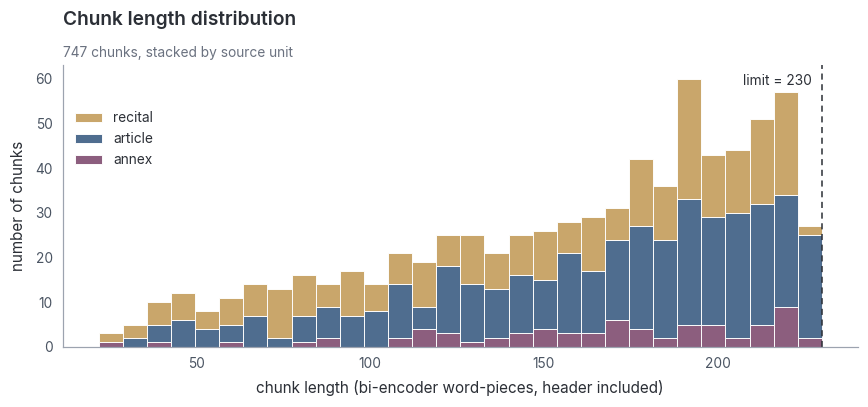

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = ["recital", "article", "annex"]
sns.histplot(data=chunk_df, x="n_tokens", hue="unit_type", hue_order=order, multiple="stack", bins=30,
             palette=UNIT_COLORS, edgecolor="white", linewidth=0.6, alpha=1, ax=ax)
ax.axvline(MAX_CHUNK_TOKENS, color=C_INK, linestyle=(0, (4, 3)), lw=1)
ax.text(MAX_CHUNK_TOKENS - 3, ax.get_ylim()[1] * 0.97, f"limit = {MAX_CHUNK_TOKENS}", ha="right", va="top",
        fontsize=9, color=C_INK)
ax.set_xlabel("chunk length (bi-encoder word-pieces, header included)")
ax.set_ylabel("number of chunks")
ax.set_title("Chunk length distribution")
subtitle(ax, f"{len(chunk_df)} chunks, stacked by source unit")
sns.move_legend(ax, "upper left", title=None, bbox_to_anchor=(0.0, 0.88))
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "chunk_token_hist.png", dpi=200, bbox_inches="tight")
plt.show()

**`find_chunks(unit_type, unit_no, para=None)`**

Chunks of a unit; if `para` is given, only those whose paragraph range contains it.

In [30]:
def find_chunks(unit_type, unit_no, para=None):
    """Chunks of a unit; if `para` is given, only those whose paragraph range contains it."""
    out = [c for c in CHUNKS if c["unit_type"] == unit_type and c["unit_no"] == unit_no]
    if para is not None:
        out = [c for c in out if c["para_start"] is not None and c["para_start"] <= para <= c["para_end"]]
    return out

**`show_chunk(c, max_chars=1500)`**

Prints one chunk with its page number and token count, to check the chunking by eye.

In [31]:
def show_chunk(c, max_chars=1500):
    print(f"--- chunk {c['chunk_id']} | page {c['page_start']} | {c['n_tokens']} tokens ---")
    print(c["text"][:max_chars], "\n")

In [32]:
show_chunk(find_chunks("article", 5)[0])          # first chunk of Article 5

for c in find_chunks("article", 99, 6):           # penalty paragraph with the "whichever is lower" rule
    show_chunk(c)

show_chunk(find_chunks("recital", 44)[0])         # an example recital

--- chunk 316 | page 51 | 146 tokens ---
[Article 5 – Prohibited AI practices, para 1, part 1/6]
1. The following AI practices shall be prohibited: (a) the placing on the market, the putting into service or the use of an AI system that deploys subliminal techniques beyond a person’s consciousness or purposefully manipulative or deceptive techniques, with the objective, or the effect of materially distorting the behaviour of a person or a group of persons by appreciably impairing their ability to make an informed decision, thereby causing them to take a decision that they would not have otherwise taken in a manner that causes or is reasonably likely to cause that person, another person or group of persons significant harm; 

--- chunk 636 | page 116 | 123 tokens ---
[Article 99 – Penalties, para 5–6]
5. The supply of incorrect, incomplete or misleading information to notified bodies or national competent authorities in reply to a request shall be subject to administrative fines of up to

## 4. Bi-encoder indexing

Every chunk text is embedded once with the bi-encoder (Reimers and Gurevych, 2019). Embeddings are L2-normalised, so the inner product equals cosine similarity. They are stored in an exact FAISS `IndexFlatIP` (brute-force inner product, no approximation), which keeps the experiment free of approximate-search noise. This work happens once, offline, and is not part of query latency.

**Concept: dense indexing.** A bi-encoder turns every chunk into a vector once. With unit-length vectors, cosine similarity is the same as the inner product, so an exact inner-product index gives exact cosine search. An exact index is used so that speed and accuracy comparisons are not mixed up with approximation errors.

In [33]:
from sentence_transformers import SentenceTransformer, CrossEncoder

import faiss

bi_encoder = SentenceTransformer(BI_ENCODER, device=DEVICE)

bi_encoder.max_seq_length = BI_MAX_SEQ

**`sync()`**

Wait for queued GPU work so that perf_counter timings are honest.

In [34]:
def sync():
    """Wait for queued GPU work so that perf_counter timings are honest."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

In [35]:
chunk_texts = [c["text"] for c in CHUNKS]

sync(); t0 = time.perf_counter()



doc_emb = bi_encoder.encode(chunk_texts, batch_size=64, normalize_embeddings=True,
                            convert_to_numpy=True, show_progress_bar=False).astype("float32")

index = faiss.IndexFlatIP(doc_emb.shape[1])

index.add(doc_emb)

sync(); INDEXING_SECONDS = time.perf_counter() - t0



print(f"embedded {index.ntotal} chunks, dim {doc_emb.shape[1]}, in {INDEXING_SECONDS:.1f} s")

print("norm check (should be 1.0):", float(np.linalg.norm(doc_emb[0])))

embedded 747 chunks, dim 384, in 1.4 s
norm check (should be 1.0): 1.0


## 5. Pipeline 1: dense retrieval

`retrieve` embeds the query, searches the FAISS index and returns the Top 10 candidates with their bi-encoder score and 1-based rank. This Top 10 is the common starting point of both pipelines.

## 6. Pipeline 2: cross-encoder re-ranking

`rerank` feeds each of the 10 (query, chunk) pairs *jointly* through the cross-encoder (Nogueira and Cho, 2019; MS MARCO, Nguyen et al., 2016; MiniLM, Wang et al., 2020), producing one relevance logit per pair, and re-sorts the same 10 chunks by that score. Nothing outside the Top 10 can enter, which an assertion verifies. Raw logits (no sigmoid) are used; the order is identical either way.

`baseline_pipeline` and `rerank_pipeline` return the Top 3 chunks that go into the prompt, the full Top 10 table and a timing dictionary (`embed_ms`, `search_ms`, `rerank_ms`, `llm_ms`; the LLM time is filled in when an answer is generated).

**Concept: retrieve, then re-rank.** The bi-encoder is fast because chunk vectors are computed ahead of time, but the question and the chunk never interact. The cross-encoder reads the question and the chunk together, which is more accurate but needs one model pass per pair. So the cheap model first picks 10 candidates, and the expensive model only orders those 10.

In [36]:
cross_encoder = CrossEncoder(CROSS_ENCODER, device=DEVICE, max_length=512)

**`embed_query(query)`**

Bi-encoder embedding of one query, shape (1, dim), L2-normalised.

In [37]:
def embed_query(query):
    """Bi-encoder embedding of one query, shape (1, dim), L2-normalised."""
    return bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True,
                             show_progress_bar=False).astype("float32")

**`retrieve(query, k=TOP_K_RETRIEVE, timings=None)`**

Pipeline 1 retrieval: Top-k chunks by cosine similarity.

In [38]:
def retrieve(query, k=TOP_K_RETRIEVE, timings=None):
    """Pipeline 1 retrieval: Top-k chunks by cosine similarity.

    Returns a list of dicts {chunk_id, bi_score, bi_rank} ordered by rank (rank starts at 1).
    If `timings` (a dict) is given, embed_ms and search_ms are stored in it.
    """
    sync(); t0 = time.perf_counter()
    q = embed_query(query)
    sync(); t1 = time.perf_counter()
    scores, ids = index.search(q, k)
    t2 = time.perf_counter()
    if timings is not None:
        timings["embed_ms"] = (t1 - t0) * 1000
        timings["search_ms"] = (t2 - t1) * 1000
    return [dict(chunk_id=int(i), bi_score=float(s), bi_rank=r)
            for r, (i, s) in enumerate(zip(ids[0], scores[0]), start=1)]

**`ce_scores(model, pairs, batch_size=64)`**

Raw cross-encoder logits for a list of (query, text) pairs.

In [39]:
def ce_scores(model, pairs, batch_size=64):
    """Raw cross-encoder logits for a list of (query, text) pairs."""
    try:
        out = model.predict(pairs, batch_size=batch_size, show_progress_bar=False,
                            activation_fn=torch.nn.Identity())
    except TypeError:                      # older sentence-transformers without activation_fn
        out = model.predict(pairs, batch_size=batch_size, show_progress_bar=False)
    return np.asarray(out, dtype="float32")

**`rerank(query, candidates, model=None, timings=None)`**

Pipeline 2 re-ranking: score the candidates with the cross-encoder and re-sort.

In [40]:
def rerank(query, candidates, model=None, timings=None):
    """Pipeline 2 re-ranking: score the candidates with the cross-encoder and re-sort.

    Adds ce_score and ce_rank (1-based) to copies of the candidate dicts and returns them
    sorted by ce_score descending. If `timings` is given, rerank_ms is stored in it.
    """
    model = model or cross_encoder
    sync(); t0 = time.perf_counter()
    pairs = [(query, CHUNKS[c["chunk_id"]]["text"]) for c in candidates]
    scores = ce_scores(model, pairs)
    ranked = sorted(({**c, "ce_score": float(s)} for c, s in zip(candidates, scores)),
                    key=lambda c: -c["ce_score"])
    for r, c in enumerate(ranked, start=1):
        c["ce_rank"] = r
    sync()
    if timings is not None:
        timings["rerank_ms"] = (time.perf_counter() - t0) * 1000
    assert {c["chunk_id"] for c in ranked} == {c["chunk_id"] for c in candidates}, \
        "re-ranking must only reorder the Top-10 candidates"
    return ranked

**`baseline_pipeline(query)`**

Pipeline 1: bi-encoder Top 10 -> Top 3 straight into the prompt.

In [41]:
def baseline_pipeline(query):
    """Pipeline 1: bi-encoder Top 10 -> Top 3 straight into the prompt."""
    timings = {}
    cands = retrieve(query, timings=timings)
    return dict(pipeline="baseline", query=query, top10=cands,
                context_ids=[c["chunk_id"] for c in cands[:TOP_K_CONTEXT]],
                timings={**timings, "rerank_ms": 0.0, "llm_ms": None})

**`rerank_pipeline(query)`**

Pipeline 2: same Top 10 -> cross-encoder re-sort -> Top 3 into the prompt.

In [42]:
def rerank_pipeline(query):
    """Pipeline 2: same Top 10 -> cross-encoder re-sort -> Top 3 into the prompt."""
    timings = {}
    cands = retrieve(query, timings=timings)
    ranked = rerank(query, cands, timings=timings)
    return dict(pipeline="rerank", query=query, top10=ranked,
                context_ids=[c["chunk_id"] for c in ranked[:TOP_K_CONTEXT]],
                timings={**timings, "llm_ms": None})

In [43]:
PIPELINES = {"baseline": baseline_pipeline, "rerank": rerank_pipeline}

## 7. Shared prompt and LLM call

Both pipelines use the *same* `build_prompt` function and the same generation settings (temperature 0, fixed seed), so that any difference between Answer 1 and Answer 2 can only come from which three chunks were supplied and in what order. The system message restricts the model to the supplied excerpts, asks for a short answer in full sentences that keeps any condition, exception or amount, asks it to cite the bracketed headers, and defines an exact abstention sentence. (A first version that only said "cite the headers" made the model reply with nothing but a header in about one answer in eight, for every pipeline, so the wording was changed for all pipelines at once.)

Answers are cached in `results/answers.json`, keyed by pipeline and query; a cached entry is reused only if the same context chunks, model and system prompt were used. Set `FORCE_REGENERATE = True` to ignore the cache.

**Concept: grounded generation.** The LLM only sees the three chunks it is given, and it is told to answer from them alone. If the right clause is missing from those chunks, the answer will be wrong or empty. That is why the difference between Answer 1 and Answer 2 shows the effect of retrieval and nothing else: the prompt and the decoding settings are identical.

In [44]:
SYSTEM_PROMPT = (
    "You answer questions about the EU Artificial Intelligence Act (Regulation (EU) 2024/1689) using ONLY the context "
    "excerpts given by the user. Do not use outside knowledge.\n"
    "Answer in 1 to 4 complete sentences: first the direct answer to the question, then any condition, exception, "
    "deadline or amount from the excerpts that changes it. "
    "Cite the excerpts you used by their header in square brackets at the end of the sentence they support.\n"
    "If the excerpts do not contain the answer, reply exactly: The provided context does not specify this."
)

ABSTAIN_TEXT = "The provided context does not specify this."

**`build_prompt(query, chunk_ids)`**

Chat messages for the LLM; identical structure for both pipelines.

In [45]:
def build_prompt(query, chunk_ids):
    """Chat messages for the LLM; identical structure for both pipelines.

    chunk_ids are given in rank order and become "Context 1", "Context 2", ...
    """
    blocks = [f"Context {i}:\n{CHUNKS[cid]['text']}" for i, cid in enumerate(chunk_ids, start=1)]
    user = "\n\n".join(blocks) + f"\n\nQuestion: {query}"
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user}]

**`generate(messages)`**

Call the configured LLM. Returns (answer_text, wall_time_ms).

In [46]:
def generate(messages):
    """Call the configured LLM. Returns (answer_text, wall_time_ms)."""
    if LLM_BACKEND == "ollama":
        import ollama
        t0 = time.perf_counter()
        resp = ollama.chat(model=OLLAMA_MODEL, messages=messages,
                           options={"temperature": 0, "seed": SEED, "num_ctx": 4096})
        ms = (time.perf_counter() - t0) * 1000
        return resp["message"]["content"].strip(), ms
    if LLM_BACKEND == "gemini":                       # optional stub, needs GEMINI_API_KEY
        from google import genai
        client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
        t0 = time.perf_counter()
        resp = client.models.generate_content(
            model="gemini-2.0-flash",
            contents=messages[1]["content"],
            config={"system_instruction": messages[0]["content"], "temperature": 0, "seed": SEED})
        return resp.text.strip(), (time.perf_counter() - t0) * 1000
    raise ValueError(f"unknown LLM_BACKEND {LLM_BACKEND!r}")

In [47]:
# ----- answer cache -----
ANSWER_CACHE_PATH = RESULTS_DIR / "answers.json"

ANSWER_CACHE = json.loads(ANSWER_CACHE_PATH.read_text(encoding="utf-8")) if ANSWER_CACHE_PATH.exists() else {}

LLM_MODEL_NAME = OLLAMA_MODEL if LLM_BACKEND == "ollama" else LLM_BACKEND

**`answer_query(pipeline, query, force=False, save=True)`**

Run one pipeline end to end for `query`; the LLM answer is cached.

In [48]:
def answer_query(pipeline, query, force=False, save=True):
    """Run one pipeline end to end for `query`; the LLM answer is cached.

    Returns the pipeline result dict plus 'answer' and timings['llm_ms'].
    """
    res = PIPELINES[pipeline](query)
    key = f"{pipeline}||{query}"
    cached = ANSWER_CACHE.get(key)
    if (cached and not force and not FORCE_REGENERATE
            and cached["context_ids"] == res["context_ids"] and cached["model"] == LLM_MODEL_NAME
            and cached.get("system_prompt") == SYSTEM_PROMPT):
        res["answer"], res["timings"]["llm_ms"] = cached["answer"], cached["llm_ms"]
        res["from_cache"] = True
        return res
    text, ms = generate(build_prompt(query, res["context_ids"]))
    res["answer"], res["timings"]["llm_ms"], res["from_cache"] = text, ms, False
    if save:
        ANSWER_CACHE[key] = dict(answer=text, llm_ms=ms, context_ids=res["context_ids"],
                                 model=LLM_MODEL_NAME, system_prompt=SYSTEM_PROMPT)
        ANSWER_CACHE_PATH.write_text(json.dumps(ANSWER_CACHE, ensure_ascii=False, indent=1), encoding="utf-8")
    return res

In [49]:
# Show the exact prompt for one example query (identical template for both pipelines)
_demo = "Can an AI system be used to predict whether a person will commit a crime?"
_msgs = build_prompt(_demo, baseline_pipeline(_demo)["context_ids"])
print(_msgs[0]["content"], "\n")
print(_msgs[1]["content"][:1800], "...")

You answer questions about the EU Artificial Intelligence Act (Regulation (EU) 2024/1689) using ONLY the context excerpts given by the user. Do not use outside knowledge.
Answer in 1 to 4 complete sentences: first the direct answer to the question, then any condition, exception, deadline or amount from the excerpts that changes it. Cite the excerpts you used by their header in square brackets at the end of the sentence they support.
If the excerpts do not contain the answer, reply exactly: The provided context does not specify this. 

Context 1:
[Article 5 – Prohibited AI practices, para 1, part 3/6]
The following AI practices shall be prohibited: (i) detrimental or unfavourable treatment of certain natural persons or groups of persons in social contexts that are unrelated to the contexts in which the data was originally generated or collected; (ii) detrimental or unfavourable treatment of certain natural persons or groups of persons that is unjustified or disproportionate to their soc

## 8. Query set and gold labels

The 49 queries are written like questions a real user would ask. Q01–Q24 were written first; Q25–Q49 were added afterwards as further natural questions for the same categories, and **all** of them are kept and reported, whatever the outcome. They are grouped by the document-specific difficulty they test: negation and prohibitions, exceptions and corner cases, role limits (provider / deployer / importer / distributor), keyword traps (a number or date that matches many passages), scope questions, and plain control questions.

Each query carries
- `gold`: requirements `(unit_type, unit_no, paragraph, anchor phrase)` that pin the binding clause containing the answer, e.g. `("article", 5, 1, "untargeted scraping")` = the chunk of Article 5(1) that contains point (e). An anchor is needed because long paragraphs are split into several chunks. Queries that need two clauses (e.g. Q11: the general fine *and* the SME cap) have two requirements;
- `key_facts`: short strings that a correct answer should contain (case-insensitive substring check, used later as a rough automatic signal; the final judgement is manual).

A query counts as a **hit@3** if any gold chunk is among the three chunks sent to the LLM, and as **all@3** if every requirement is covered by the top 3; the **gold rank** is the best (lowest) rank among its gold chunks. The helper below prints the gold chunks so the labels can be verified by eye.

**Concept: evaluation design.** Each question is tied to the exact clause that answers it, and the questions are grouped by the kind of difficulty they test (negation, exception, role limit, keyword trap, scope, control). The first 24 questions are used to choose settings and the last 25 are only used to report, so the final numbers are not tuned on the same questions.

**`Q(id, category, query, gold, key_facts, note='')`**

Builds one question record: its id, type, the question text, the gold clause(s) that answer it, and the key facts a correct answer should contain.

In [50]:
def Q(id, category, query, gold, key_facts, note=""):
    return dict(id=id, category=category, query=query, gold=gold, key_facts=key_facts, note=note)

In [51]:
# Gold requirement = (unit_type, unit_no, paragraph or None, anchor phrase or None).
# A chunk satisfies it if it belongs to that unit/paragraph AND contains the anchor phrase.
# The anchor pins the exact clause: Article 5(1) alone is split into six chunks, and only one
# of them contains e.g. point (e) on "untargeted scraping".
# Gold always points to the binding text (articles / annexes), never to recitals.
QUERIES = [
    # ---- first batch (written before looking at any retrieval result) ----
    Q("Q01", "negation", "Is it allowed to use AI to detect the emotions of employees at their workplace?",
      [("article", 5, 1, "infer emotions")], ["medical", "safety"]),
    Q("Q02", "negation/keyword-trap", "Is it legal to build a face recognition database by scraping photos from the internet?",
      [("article", 5, 1, "untargeted scraping")], ["untargeted scraping"]),
    Q("Q03", "negation", "Can an AI system be used to predict whether a person will commit a crime?",
      [("article", 5, 1, "committing a criminal offence")], ["profiling", "personality"]),
    Q("Q04", "exception", "When are police allowed to use real-time remote biometric identification in public spaces?",
      [("article", 5, 1, "targeted search for specific victims")], ["victims", "terrorist", "imminent"]),
    Q("Q05", "exception", "Can real-time biometric identification be used before a judge or authority has approved it?",
      [("article", 5, 3, "situation of urgency")], ["urgency", "24 hours"]),
    Q("Q06", "exception", "Is every AI system listed in Annex III automatically considered high-risk?",
      [("article", 6, 3, None)], ["profiling", "significant risk"]),
    Q("Q07", "exception", "Do providers of open-source general-purpose AI models have to prepare technical documentation?",
      [("article", 53, 2, "free and open-source licence")], ["free and open-source", "systemic risk"]),
    Q("Q08", "exception", "Do deepfakes have to be labelled even when they are part of a satirical or artistic work?",
      [("article", 50, 4, "deep fake")], ["artistic", "satirical"]),
    Q("Q09", "scope-negation", "Does the AI Act apply to AI systems used only for military purposes?",
      [("article", 2, 3, None)], ["military", "defence", "national security"]),
    Q("Q10", "scope", "Does a person using an AI system for a personal hobby have obligations under the AI Act?",
      [("article", 2, 10, "purely personal non-professional")], ["purely personal non-professional"]),
    Q("Q11", "corner-case", "What is the maximum fine for a start-up that puts a prohibited AI system on the market?",
      [("article", 99, 3, None), ("article", 99, 6, None)], ["35 000 000", "7 %", "lower"],
      note="needs BOTH the general fine (para 3) and the SME/start-up cap (para 6)"),
    Q("Q12", "penalty", "What is the fine for giving misleading information to the authorities?",
      [("article", 99, 5, None)], ["7 500 000", "1 %"]),
    Q("Q13", "penalty/role", "What fines can be imposed on providers of general-purpose AI models?",
      [("article", 101, 1, None)], ["15 000 000", "3 %"]),
    Q("Q14", "role-limit", "What are the obligations of a deployer, as opposed to a provider, of a high-risk AI system?",
      [("article", 26, None, None)], ["instructions for use", "human oversight"]),
    Q("Q15", "role-limit", "When is a distributor or deployer treated as the provider of a high-risk AI system?",
      [("article", 25, 1, None)], ["name or trademark", "substantial modification"]),
    Q("Q16", "role-limit", "What must an importer check before placing a high-risk AI system on the market?",
      [("article", 23, 1, None)], ["conformity assessment", "authorised representative"]),
    Q("Q17", "role-limit", "Which deployers must carry out a fundamental rights impact assessment?",
      [("article", 27, 1, "bodies governed by public law")], ["public law", "public services"]),
    Q("Q18", "keyword-trap", "How much training compute makes a general-purpose AI model count as having systemic risk?",
      [("article", 51, 2, None)], ["10^25", "floating point"]),
    Q("Q19", "keyword-trap", "From what date do the bans on unacceptable AI practices start to apply?",
      [("article", 113, None, None)], ["2 February 2025"]),
    Q("Q20", "synonym", "Do people have to be told that they are chatting with a bot?",
      [("article", 50, 1, None)], ["interacting", "obvious"]),
    Q("Q21", "exception", "Is an AI system used for credit scoring considered high-risk?",
      [("annex", "III", 5, "creditworthiness")], ["creditworthiness", "financial fraud"]),
    Q("Q22", "control", "Does a person affected by a decision made with a high-risk AI system have a right to an explanation?",
      [("article", 86, 1, None)], ["explanation"]),
    Q("Q23", "control", "For how long must providers keep the technical documentation of a high-risk AI system?",
      [("article", 18, 1, None)], ["10 years"]),
    Q("Q24", "control", "What is the definition of an AI system?",
      [("article", 3, 1, "machine-based")], ["machine-based", "autonomy"]),
    # ---- second batch: more natural questions per category (all kept, whatever the outcome) ----
    Q("Q25", "corner-case", "Are SMEs and start-ups given lower fines under the AI Act?",
      [("article", 99, 6, None)], ["lower"]),
    Q("Q26", "negation", "Is it prohibited to use AI that exploits the vulnerabilities of children or elderly people?",
      [("article", 5, 1, "due to their age, disability")], ["age", "disability"]),
    Q("Q27", "negation", "Can a company use biometric data to sort people by their race or sexual orientation?",
      [("article", 5, 1, "sexual orientation")], ["prohibited", "law enforcement"]),
    Q("Q28", "negation", "Is social scoring of citizens banned?",
      [("article", 5, 1, "social behaviour or known")], ["detrimental or unfavourable treatment"]),
    Q("Q29", "exception", "How quickly must a provider report a serious incident that caused a person's death?",
      [("article", 73, 4, "death of a person")], ["10 days"]),
    Q("Q30", "control", "What is the deadline for reporting a serious incident?",
      [("article", 73, 2, "not later than 15 days")], ["15 days"]),
    Q("Q31", "role-limit", "Does an employer have to inform workers before using a high-risk AI system in the workplace?",
      [("article", 26, 7, None)], ["workers", "representatives"]),
    Q("Q32", "exception", "Can a high-risk AI system be used without completing the conformity assessment?",
      [("article", 46, 1, "exceptional reasons of public security")], ["public security"]),
    Q("Q33", "exception", "Do AI-generated news articles need to be disclosed if a human editor reviewed them?",
      [("article", 50, 4, "editorial control")], ["editorial"]),
    Q("Q34", "role-limit", "Must people be informed when an emotion recognition system is used on them?",
      [("article", 50, 3, None)], ["inform"]),
    Q("Q35", "control", "Is an AI tool that screens job applications and filters CVs high-risk?",
      [("annex", "III", 4, "filter job applications")], ["recruitment"]),
    Q("Q36", "scope", "Does the AI Act apply to AI being developed and tested before it is released?",
      [("article", 2, 8, "research, testing or development activity")], ["research", "testing"]),
    Q("Q37", "corner-case", "What happens to high-risk AI systems already on the market before the rules apply?",
      [("article", 111, 2, None)], ["significant changes"]),
    Q("Q38", "exception", "Does the deepfake disclosure obligation apply when the content is used by law enforcement to investigate crimes?",
      [("article", 50, 4, "authorised by law to detect")], ["authorised by law"]),
    Q("Q39", "exception", "Are there exceptions to the ban on emotion recognition at work?",
      [("article", 5, 1, "medical or safety reasons")], ["medical", "safety"]),
    Q("Q40", "exception", "Can a provider avoid the high-risk obligations by documenting that its Annex III system is not risky?",
      [("article", 6, 3, None), ("article", 6, 4, None)], ["document"]),
    Q("Q41", "penalty/role", "What fine does a deployer face for not complying with its obligations?",
      [("article", 99, 4, "obligations of deployers")], ["15 000 000", "3 %"]),
    Q("Q42", "control", "Is AI used to assess students' exams or admission considered high-risk?",
      [("annex", "III", 3, None)], ["admission", "learning outcomes"]),
    Q("Q43", "control", "Can AI be used to decide on asylum applications?",
      [("annex", "III", 7, None)], ["asylum"]),
    Q("Q44", "role-limit", "Which uses of AI by law enforcement for lie detection are high-risk?",
      [("annex", "III", 6, "polygraphs")], ["polygraphs"]),
    Q("Q45", "exception", "Is facial recognition allowed for unlocking a phone or verifying identity?",
      [("annex", "III", 1, "sole purpose of which is to confirm")], ["verification"]),
    Q("Q46", "exception", "Can police use biometric identification to find a missing child?",
      [("article", 5, 1, "targeted search for specific victims")], ["missing persons"]),
    Q("Q47", "exception", "Are AI systems used for detecting financial fraud classified as high-risk?",
      [("annex", "III", 5, "detecting financial fraud")], ["financial fraud"]),
    Q("Q48", "control", "How long do providers have to keep logs automatically generated by a high-risk AI system?",
      [("article", 19, 1, "at least six months")], ["six months"]),
    Q("Q49", "keyword-trap", "When will most of the AI Act's rules start to apply?",
      [("article", 113, None, None)], ["2 August 2026"]),
]

QBY = {q["id"]: q for q in QUERIES}

**`requirement_chunk_ids(req)`**

Ids of the chunks that satisfy one gold requirement (unit, paragraph, anchor phrase).

In [52]:
def requirement_chunk_ids(req):
    """Ids of the chunks that satisfy one gold requirement (unit, paragraph, anchor phrase)."""
    utype, no, para, anchor = req
    return {c["chunk_id"] for c in find_chunks(utype, no, para)
            if anchor is None or anchor in c["text"]}

**`gold_requirements(q)`**

One set of chunk ids per gold requirement of the query.

In [53]:
def gold_requirements(q):
    """One set of chunk ids per gold requirement of the query."""
    return [requirement_chunk_ids(r) for r in q["gold"]]

**`gold_chunk_ids(q)`**

Ids of all chunks matching any gold requirement of the query.

In [54]:
def gold_chunk_ids(q):
    """Ids of all chunks matching any gold requirement of the query."""
    return sorted(set().union(*gold_requirements(q)))

**`show_gold(q, max_chunks=2, max_chars=500)`**

Print the gold chunks of a query for manual verification.

In [55]:
def show_gold(q, max_chunks=2, max_chars=500):
    """Print the gold chunks of a query for manual verification."""
    ids = gold_chunk_ids(q)
    print(f"{q['id']} [{q['category']}] {q['query']}")
    print(f"   gold requirements: {q['gold']} -> {len(ids)} chunk(s): {ids}")
    for cid in ids[:max_chunks]:
        print("   >", CHUNKS[cid]["text"][:max_chars].replace("\n", " | "))
    print()

In [56]:
# Every gold requirement must resolve to at least one chunk
unresolved = [(q["id"], r) for q in QUERIES for r in q["gold"] if not requirement_chunk_ids(r)]
print("unresolved gold requirements:", unresolved if unresolved else "none")
assert not unresolved, "fix the gold requirements above"

for q in QUERIES:
    show_gold(q)

unresolved gold requirements: none
Q01 [negation] Is it allowed to use AI to detect the emotions of employees at their workplace?
   gold requirements: [('article', 5, 1, 'infer emotions')] -> 1 chunk(s): [319]
   > [Article 5 – Prohibited AI practices, para 1, part 4/6] | The following AI practices shall be prohibited: (e) the placing on the market, the putting into service for this specific purpose, or the use of AI systems that create or expand facial recognition databases through the untargeted scraping of facial images from the internet or CCTV footage; (f) the placing on the market, the putting into service for this specific purpose, or the use of AI systems to infer emotions of a natural person in the 

Q02 [negation/keyword-trap] Is it legal to build a face recognition database by scraping photos from the internet?
   gold requirements: [('article', 5, 1, 'untargeted scraping')] -> 1 chunk(s): [319]
   > [Article 5 – Prohibited AI practices, para 1, part 4/6] | The following AI

## 9. Retrieval experiment (no LLM yet)

For every query, the bi-encoder Top 10 is computed once and then re-ranked. Per query and pipeline the table records the gold rank, hit@3, all@3 (every gold requirement covered by the top 3), MRR@10 (reciprocal rank of the best gold chunk, 0 if absent) and recall@10 (share of gold chunks inside the Top 10). `rank_shift = baseline rank - re-ranked rank`, so a positive value means the gold chunk moved up.

A query is flagged as a **showcase** case when the gold chunk was buried at baseline rank 4-10 and re-ranking moved it into the Top 3. The long-format table of all 10 candidates per query is saved to `results/retrieval_runs.csv`.

**Concept: retrieval metrics.** hit@3 asks whether any right clause is among the three chunks the LLM sees. all@3 asks whether every needed clause is. MRR@10 gives 1 divided by the rank of the best right clause, so a higher rank counts for more. Recall tells how often the right clause was among the candidates at all, because re-ranking can only reorder what the first stage found.

**`best_rank(ranked_ids, gold_ids)`**

Best (lowest) 1-based rank of any gold chunk in a ranked id list; None if absent.

In [57]:
def best_rank(ranked_ids, gold_ids):
    """Best (lowest) 1-based rank of any gold chunk in a ranked id list; None if absent."""
    hits = [i for i, cid in enumerate(ranked_ids, start=1) if cid in gold_ids]
    return min(hits) if hits else None

In [58]:
RETR = {}      # qid -> {"baseline": top10 by bi-encoder, "reranked": same chunks re-sorted by cross-encoder}

for q in QUERIES:
    cands = retrieve(q["query"])
    RETR[q["id"]] = dict(baseline=cands, reranked=rerank(q["query"], cands))

records = []

for q in QUERIES:
    gold = set(gold_chunk_ids(q))
    base_ids = [c["chunk_id"] for c in RETR[q["id"]]["baseline"]]
    rr_ids = [c["chunk_id"] for c in RETR[q["id"]]["reranked"]]
    rb, rr = best_rank(base_ids, gold), best_rank(rr_ids, gold)
    reqs = gold_requirements(q)
    records.append(dict(
        id=q["id"], category=q["category"], n_gold_chunks=len(gold),
        gold_rank_baseline=rb, gold_rank_reranked=rr,
        hit3_baseline=int(rb is not None and rb <= 3), hit3_reranked=int(rr is not None and rr <= 3),
        # all@3: every gold requirement (e.g. general fine AND SME cap) is covered by the top 3
        all3_baseline=int(all(r & set(base_ids[:3]) for r in reqs)),
        all3_reranked=int(all(r & set(rr_ids[:3]) for r in reqs)),
        mrr10_baseline=1 / rb if rb else 0.0, mrr10_reranked=1 / rr if rr else 0.0,
        recall10=len(gold & set(base_ids)) / len(gold),
        rank_shift=(rb - rr) if (rb and rr) else None,
        showcase=bool(rb and rr and 4 <= rb <= 10 and 1 <= rr <= 3),
    ))

runs = pd.DataFrame(records)

for col in ("gold_rank_baseline", "gold_rank_reranked", "rank_shift"):
    runs[col] = runs[col].astype("Int64")      # integer with <NA> = "not in top 10"

display(runs.drop(columns=["category"]).set_index("id"))

,n_gold_chunks,gold_rank_baseline,gold_rank_reranked,hit3_baseline,hit3_reranked,all3_baseline,all3_reranked,mrr10_baseline,mrr10_reranked,recall10,rank_shift,showcase
id,,,,,,,,,,,,
Q01,1,3,3,1,1,1,1,0.333333,0.333333,1.000000,0,False
Q02,1,4,2,0,1,0,1,0.250000,0.500000,1.000000,2,True
Q03,1,1,2,1,1,1,1,1.000000,0.500000,1.000000,-1,False
Q04,1,<NA>,<NA>,0,0,0,0,0.000000,0.000000,0.000000,<NA>,False
Q05,1,4,4,0,0,0,0,0.250000,0.250000,1.000000,0,False
Q06,2,<NA>,<NA>,0,0,0,0,0.000000,0.000000,0.000000,<NA>,False
Q07,1,5,5,0,0,0,0,0.200000,0.200000,1.000000,0,False
Q08,1,3,2,1,1,1,1,0.333333,0.500000,1.000000,1,False
Q09,1,3,3,1,1,1,1,0.333333,0.333333,1.000000,0,False


In [59]:
metric_cols = ["hit3_baseline", "hit3_reranked", "all3_baseline", "all3_reranked",
               "mrr10_baseline", "mrr10_reranked", "recall10"]
by_cat = runs.groupby("category")[metric_cols].mean()
by_cat.insert(0, "n_queries", runs.groupby("category").size())
overall = runs[metric_cols].mean().to_frame("OVERALL").T
overall.insert(0, "n_queries", len(runs))
display(pd.concat([by_cat, overall]).round(3))

# Long-format table: all 10 candidates of every query with both rankings
long_rows = []
for q in QUERIES:
    gold = set(gold_chunk_ids(q))
    ce = {c["chunk_id"]: c for c in RETR[q["id"]]["reranked"]}
    for c in RETR[q["id"]]["baseline"]:
        cid = c["chunk_id"]
        long_rows.append(dict(query_id=q["id"], chunk_id=cid, header=CHUNKS[cid]["text"].split("\n")[0],
                              bi_score=round(c["bi_score"], 4), bi_rank=c["bi_rank"],
                              ce_score=round(ce[cid]["ce_score"], 4), ce_rank=ce[cid]["ce_rank"],
                              is_gold=cid in gold))
retrieval_runs = pd.DataFrame(long_rows)
retrieval_runs.to_csv(RESULTS_DIR / "retrieval_runs.csv", index=False)

rank_shifts = runs[["id", "category", "gold_rank_baseline", "gold_rank_reranked", "rank_shift", "showcase"]].copy()
rank_shifts.to_csv(RESULTS_DIR / "rank_shifts.csv", index=False)
print("saved:", RESULTS_DIR / "retrieval_runs.csv", "and", RESULTS_DIR / "rank_shifts.csv")

,n_queries,hit3_baseline,hit3_reranked,all3_baseline,all3_reranked,mrr10_baseline,mrr10_reranked,recall10
control,8,0.875,0.875,0.875,0.875,0.708,0.604,0.875
corner-case,3,1.000,1.000,0.667,0.667,0.778,1.000,0.833
exception,15,0.400,0.400,0.400,0.400,0.301,0.321,0.633
keyword-trap,3,0.333,0.333,0.333,0.333,0.333,0.333,0.333
negation,5,0.600,0.800,0.600,0.800,0.373,0.367,0.800
negation/keyword-trap,1,0.000,1.000,0.000,1.000,0.250,0.500,1.000
penalty,1,1.000,1.000,1.000,1.000,1.000,1.000,1.000
penalty/role,2,1.000,1.000,1.000,1.000,1.000,1.000,1.000
role-limit,7,0.857,0.857,0.857,0.857,0.464,0.726,0.905
scope,2,0.000,0.000,0.000,0.000,0.000,0.000,0.000


saved: results/retrieval_runs.csv and results/rank_shifts.csv


**`with_query_text(df)`**

Adds the question text next to each question id so a results table can be read without looking up the ids.

In [60]:
def with_query_text(df):
    return df.assign(query=df["id"].map(lambda i: QBY[i]["query"])).set_index("id")

In [61]:
cols = ["category", "gold_rank_baseline", "gold_rank_reranked", "rank_shift", "query"]

helped = runs[runs["rank_shift"].fillna(0) > 0].sort_values("rank_shift", ascending=False)

hurt   = runs[runs["rank_shift"].fillna(0) < 0].sort_values("rank_shift")

showcase_ids = runs.loc[runs["showcase"], "id"].tolist()

print(f"Gold rank improved by re-ranking ({len(helped)} queries):")

display(with_query_text(helped)[cols])

print(f"Gold rank got worse after re-ranking ({len(hurt)} queries):")

display(with_query_text(hurt)[cols])

print("Showcase queries (gold at baseline rank 4-10, re-ranked into Top 3):", showcase_ids)

Gold rank improved by re-ranking (15 queries):


,category,gold_rank_baseline,gold_rank_reranked,rank_shift,query
id,,,,,
Q16,role-limit,4,1,3,What must an importer check before placing a high-risk AI system on the market?
Q47,exception,5,2,3,Are AI systems used for detecting financial fraud classified as high-risk?
Q27,negation,5,2,3,Can a company use biometric data to sort people by their race or sexual orientation?
Q25,corner-case,3,1,2,Are SMEs and start-ups given lower fines under the AI Act?
Q34,role-limit,3,1,2,Must people be informed when an emotion recognition system is used on them?
Q24,control,3,1,2,What is the definition of an AI system?
Q02,negation/keyword-trap,4,2,2,Is it legal to build a face recognition database by scraping photos from the internet?
Q21,exception,3,2,1,Is an AI system used for credit scoring considered high-risk?
Q14,role-limit,2,1,1,"What are the obligations of a deployer, as opposed to a provider, of a high-risk AI system?"


Gold rank got worse after re-ranking (8 queries):


,category,gold_rank_baseline,gold_rank_reranked,rank_shift,query
id,,,,,
Q46,exception,2,9,-7,Can police use biometric identification to find a missing child?
Q20,synonym,1,5,-4,Do people have to be told that they are chatting with a bot?
Q43,control,1,3,-2,Can AI be used to decide on asylum applications?
Q44,role-limit,2,4,-2,Which uses of AI by law enforcement for lie detection are high-risk?
Q33,exception,1,2,-1,Do AI-generated news articles need to be disclosed if a human editor reviewed them?
Q22,control,1,2,-1,Does a person affected by a decision made with a high-risk AI system have a right to an explanation?
Q03,negation,1,2,-1,Can an AI system be used to predict whether a person will commit a crime?
Q42,control,1,2,-1,Is AI used to assess students' exams or admission considered high-risk?


Showcase queries (gold at baseline rank 4-10, re-ranked into Top 3): ['Q02', 'Q16', 'Q27', 'Q47']


## 10. Answer generation

Both pipelines answer all queries with the same prompt template and LLM settings. The table keeps Answer 1 (baseline) and Answer 2 (re-ranking) next to each other.

- **Key-fact coverage** = share of the query's `key_facts` that occur in the answer. Matching is case-insensitive after normalising spaces, non-breaking spaces, `7 %` vs `7%`, digit grouping (`35 000 000` vs `35,000,000`) and superscript digits. This is only a rough automatic signal.
- **Abstained** = the answer contains "does not specify".
- `manual_label_A1` / `manual_label_A2` are left empty for the manual correctness judgement.

**Concept: judging answers.** Each question lists a few key facts that a correct answer should contain. The share found in an answer is a rough, automatic score. It cannot judge wording, so the answers still need to be read by hand.

In [62]:
SUPERSCRIPT_MAP = str.maketrans("⁰¹²³⁴⁵⁶⁷⁸⁹", "0123456789")

**`norm_text(s)`**

Normalise text for the key-fact check (case, spaces, %, digit groups, superscripts).

In [63]:
def norm_text(s):
    """Normalise text for the key-fact check (case, spaces, %, digit groups, superscripts)."""
    s = re.sub(r"[⁰¹²³⁴⁵⁶⁷⁸⁹]+", lambda m: "^" + m.group(0).translate(SUPERSCRIPT_MAP), s)
    s = s.replace(" ", " ").replace(" ", " ").replace(" ", " ").lower()
    s = re.sub(r"\^\{(\d+)\}", r"^\1", s)                 # 10^{25} -> 10^25
    s = re.sub(r"\s+", " ", s)
    s = re.sub(r"\s+%", "%", s)                           # "7 %" -> "7%"
    s = re.sub(r"(?<=\d)[ ,.](?=\d{3}(?!\d))", "", s)     # "35 000 000" / "35,000,000" -> "35000000"
    return s.strip()

**`key_fact_coverage(answer, key_facts)`**

Fraction of key facts found in the answer, plus the list of missing ones.

In [64]:
def key_fact_coverage(answer, key_facts):
    """Fraction of key facts found in the answer, plus the list of missing ones."""
    a = norm_text(answer)
    missing = [k for k in key_facts if norm_text(k) not in a]
    return 1 - len(missing) / len(key_facts), missing

In [65]:
ANSWERS = {}     # (pipeline, qid) -> result dict incl. 'answer'

for q in QUERIES:
    for p in ("baseline", "rerank"):
        ANSWERS[(p, q["id"])] = answer_query(p, q["query"])

print("answers generated or loaded:", len(ANSWERS),
      "| from cache:", sum(r["from_cache"] for r in ANSWERS.values()))

answers generated or loaded: 98 | from cache: 98


In [66]:
ans_rows = []
for q in QUERIES:
    a1, a2 = ANSWERS[("baseline", q["id"])], ANSWERS[("rerank", q["id"])]
    c1, miss1 = key_fact_coverage(a1["answer"], q["key_facts"])
    c2, miss2 = key_fact_coverage(a2["answer"], q["key_facts"])
    ans_rows.append(dict(
        id=q["id"], category=q["category"], query=q["query"],
        context_baseline=[CHUNKS[c]["text"].split("\n")[0] for c in a1["context_ids"]],
        context_rerank=[CHUNKS[c]["text"].split("\n")[0] for c in a2["context_ids"]],
        answer_1=a1["answer"], answer_2=a2["answer"],
        coverage_1=round(c1, 2), coverage_2=round(c2, 2),
        missing_1=miss1, missing_2=miss2,
        abstained_1="does not specify" in a1["answer"].lower(),
        abstained_2="does not specify" in a2["answer"].lower(),
        same_context=a1["context_ids"] == a2["context_ids"],
        manual_label_A1="", manual_label_A2=""))
answers_df = pd.DataFrame(ans_rows)
answers_df.to_csv(RESULTS_DIR / "answers.csv", index=False)
display(answers_df[["id", "category", "coverage_1", "coverage_2", "abstained_1", "abstained_2",
                    "same_context", "manual_label_A1", "manual_label_A2"]].set_index("id"))
print("mean key-fact coverage  baseline:", round(answers_df["coverage_1"].mean(), 3),
      "| re-ranking:", round(answers_df["coverage_2"].mean(), 3))

,category,coverage_1,coverage_2,abstained_1,abstained_2,same_context,manual_label_A1,manual_label_A2
id,,,,,,,,
Q01,negation,1.0,1.00,False,False,False,,
Q02,negation/keyword-trap,0.0,0.00,False,False,False,,
Q03,negation,1.0,1.00,False,False,False,,
Q04,exception,0.0,0.00,False,False,False,,
Q05,exception,0.0,0.00,False,False,False,,
Q06,exception,0.0,0.00,False,False,False,,
Q07,exception,0.0,0.00,False,False,False,,
Q08,exception,1.0,1.00,False,False,False,,
Q09,scope-negation,1.0,1.00,False,False,True,,


mean key-fact coverage  baseline: 0.673 | re-ranking: 0.769


## 11. Failure deep dives

`deep_dive(qid)` shows everything needed for one query: the side-by-side Top 10 (bi-encoder rank and score, cross-encoder rank and score, gold flag), the movement of the gold chunk(s), the three headers that were sent to the LLM in each pipeline, and both answers with their key-fact coverage. It is called for all showcase queries and for the queries where re-ranking made the gold rank worse; any other query can be inspected by calling it manually.

**Concept: look at single cases.** Averages hide how a method fails. The deep dives show, for one question, the whole top 10 under both orderings, where the right clause moved, and what the LLM wrote with each context.

In [67]:
from IPython.display import display, Markdown

**`deep_dive(qid, show_answers=True)`**

Full side-by-side report for one query.

In [68]:
def deep_dive(qid, show_answers=True):
    """Full side-by-side report for one query."""
    q = QBY[qid]
    gold = set(gold_chunk_ids(q))
    bi = {c["chunk_id"]: c for c in RETR[qid]["baseline"]}
    ce = {c["chunk_id"]: c for c in RETR[qid]["reranked"]}
    header = lambda cid: CHUNKS[cid]["text"].split("\n")[0]

    print("=" * 110)
    print(f"{qid} [{q['category']}]  {q['query']}")
    print(f"gold predicates: {q['gold']}")
    tbl = pd.DataFrame([dict(chunk_id=cid, header=header(cid)[:70], bi_rank=bi[cid]["bi_rank"],
                             bi_score=round(bi[cid]["bi_score"], 3), ce_rank=ce[cid]["ce_rank"],
                             ce_score=round(ce[cid]["ce_score"], 2), gold="GOLD" if cid in gold else "")
                        for cid in bi]).sort_values("bi_rank")
    display(tbl.set_index("bi_rank"))

    for cid in sorted(gold & set(bi), key=lambda c: bi[c]["bi_rank"]):
        print(f"Gold chunk {cid} {header(cid)}: rank #{bi[cid]['bi_rank']} -> #{ce[cid]['ce_rank']}")
    if not gold & set(bi):
        print("No gold chunk in the bi-encoder Top 10.")

    if show_answers:
        for label, pipe, name in (("Answer 1", "baseline", "baseline"), ("Answer 2", "rerank", "re-ranking")):
            r = ANSWERS[(pipe, qid)]
            cov, missing = key_fact_coverage(r["answer"], q["key_facts"])
            print(f"\nTop-3 sent to LLM ({name}):")
            for cid in r["context_ids"]:
                print("   ", cid, header(cid))
            print(f"{label} ({name}) | key-fact coverage {cov:.2f}, missing: {missing}")
            print("   ", r["answer"].replace("\n", "\n    "))
    print()

In [69]:
for qid in showcase_ids:
    deep_dive(qid)

Q02 [negation/keyword-trap]  Is it legal to build a face recognition database by scraping photos from the internet?
gold predicates: [('article', 5, 1, 'untargeted scraping')]


,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,74,[Recital 43],0.694,1,6.50,
2,53,[Recital 30],0.520,3,-8.36,
3,320,"[Article 5 – Prohibited AI practices, para 1, part 5/6]",0.507,7,-10.68,
4,319,"[Article 5 – Prohibited AI practices, para 1, part 4/6]",0.486,2,3.06,GOLD
5,67,"[Recital 38, part 2/2]",0.466,4,-9.06,
6,61,"[Recital 34, part 2/2]",0.462,5,-9.66,
7,322,"[Article 5 – Prohibited AI practices, para 2, part 1/3]",0.455,8,-10.87,
8,330,"[Article 5 – Prohibited AI practices, para 6–8]",0.446,9,-10.87,
9,323,"[Article 5 – Prohibited AI practices, para 2, part 2/3]",0.444,10,-11.06,


Gold chunk 319 [Article 5 – Prohibited AI practices, para 1, part 4/6]: rank #4 -> #2

Top-3 sent to LLM (baseline):
    74 [Recital 43]
    53 [Recital 30]
    320 [Article 5 – Prohibited AI practices, para 1, part 5/6]
Answer 1 (baseline) | key-fact coverage 0.00, missing: ['untargeted scraping']
    It is not legal to build a face recognition database by scraping photos from the internet. This practice should be prohibited because it adds to the feeling of mass surveillance and can lead to gross violations of fundamental rights, including the right to privacy. [Recital 43]

Top-3 sent to LLM (re-ranking):
    74 [Recital 43]
    319 [Article 5 – Prohibited AI practices, para 1, part 4/6]
    53 [Recital 30]
Answer 2 (re-ranking) | key-fact coverage 0.00, missing: ['untargeted scraping']
    It is not legal to build a face recognition database by scraping photos from the internet without targeting specific individuals. This practice is explicitly prohibited as it adds to feelings of 

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,390,"[Article 23 – Obligations of importers, para 2–4]",0.746,2,6.84,
2,121,[Recital 66],0.705,10,1.31,
3,391,"[Article 23 – Obligations of importers, para 5–7]",0.701,4,6.23,
4,389,"[Article 23 – Obligations of importers, para 1]",0.679,1,8.17,GOLD
5,396,"[Article 25 – Responsibilities along the AI value chain, para 1, part",0.675,8,3.55,
6,395,"[Article 25 – Responsibilities along the AI value chain, para 1, part",0.654,7,4.57,
7,149,"[Recital 84, part 1/2]",0.654,5,4.88,
8,392,"[Article 24 – Obligations of distributors, para 1–2]",0.641,3,6.83,
9,251,"[Recital 155, part 1/2]",0.634,9,2.68,


Gold chunk 389 [Article 23 – Obligations of importers, para 1]: rank #4 -> #1

Top-3 sent to LLM (baseline):
    390 [Article 23 – Obligations of importers, para 2–4]
    121 [Recital 66]
    391 [Article 23 – Obligations of importers, para 5–7]
Answer 1 (baseline) | key-fact coverage 0.00, missing: ['conformity assessment', 'authorised representative']
    An importer must ensure that a high-risk AI system is not in conformity with the Regulation or is falsified before placing it on the market. If there are concerns, the system should be brought into conformity first [Context 1, Article 23, para 2].

Top-3 sent to LLM (re-ranking):
    389 [Article 23 – Obligations of importers, para 1]
    390 [Article 23 – Obligations of importers, para 2–4]
    392 [Article 24 – Obligations of distributors, para 1–2]
Answer 2 (re-ranking) | key-fact coverage 1.00, missing: []
    Before placing a high-risk AI system on the market, importers must ensure that the system is in conformity with this Reg

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,53,[Recital 30],0.625,1,5.19,
2,23,"[Recital 16, part 1/2]",0.521,3,1.08,
3,93,"[Recital 54, part 1/2]",0.511,4,-0.52,
4,21,[Recital 14],0.505,5,-1.85,
5,320,"[Article 5 – Prohibited AI practices, para 1, part 5/6]",0.480,2,2.78,GOLD
6,22,[Recital 15],0.471,7,-4.07,
7,55,[Recital 32],0.464,6,-2.97,
8,61,"[Recital 34, part 2/2]",0.462,10,-6.19,
9,63,"[Recital 35, part 2/2]",0.459,9,-5.49,


Gold chunk 320 [Article 5 – Prohibited AI practices, para 1, part 5/6]: rank #5 -> #2

Top-3 sent to LLM (baseline):
    53 [Recital 30]
    23 [Recital 16, part 1/2]
    93 [Recital 54, part 1/2]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    No, using biometric data to deduce or infer an individual's political opinions, trade union membership, religious or philosophical beliefs, race, sex life, or sexual orientation should be prohibited. However, sorting individuals according to less sensitive characteristics like hair colour or eye colour for law enforcement purposes is allowed. [Recital 30]

Top-3 sent to LLM (re-ranking):
    53 [Recital 30]
    320 [Article 5 – Prohibited AI practices, para 1, part 5/6]
    23 [Recital 16, part 1/2]
Answer 2 (re-ranking) | key-fact coverage 1.00, missing: []
    No, according to [Article 5 – Prohibited AI practices, para 1, part 5/6], using biometric categorisation systems that categorise individuals based on their biometric data t

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,105,"[Recital 59, part 2/4]",0.640,5,5.20,
2,102,"[Recital 58, part 2/3]",0.635,1,8.42,
3,334,"[Article 6 – Classification rules for high-risk AI systems, para 4–5]",0.623,6,4.87,
4,112,"[Recital 61, part 2/2]",0.603,7,4.84,
5,692,"[Annex III – High-risk AI systems referred to in Article 6(2), point 5",0.591,2,7.03,GOLD
6,73,"[Recital 42, part 2/2]",0.590,3,5.44,
7,525,[Article 60 – Testing of high-risk AI systems in real world conditions,0.560,10,3.01,
8,87,[Recital 52],0.551,4,5.42,
9,129,[Recital 71],0.549,9,3.19,


Gold chunk 692 [Annex III – High-risk AI systems referred to in Article 6(2), point 5]: rank #5 -> #2

Top-3 sent to LLM (baseline):
    105 [Recital 59, part 2/4]
    102 [Recital 58, part 2/3]
    334 [Article 6 – Classification rules for high-risk AI systems, para 4–5]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    AI systems used for detecting financial fraud are not considered high-risk under this Regulation, as they are specifically excluded from the high-risk classification in the context provided. [Context 2]

Top-3 sent to LLM (re-ranking):
    102 [Recital 58, part 2/3]
    692 [Annex III – High-risk AI systems referred to in Article 6(2), point 5]
    73 [Recital 42, part 2/2]
Answer 2 (re-ranking) | key-fact coverage 1.00, missing: []
    AI systems used for detecting financial fraud should not be considered high-risk under this Regulation. [Context 1]



In [70]:
# Cases where re-ranking made the gold rank worse
for qid in hurt["id"]:
    deep_dive(qid)
if hurt.empty:
    print("no query with a worse gold rank after re-ranking")

Q46 [exception]  Can police use biometric identification to find a missing child?
gold predicates: [('article', 5, 1, 'targeted search for specific victims')]


,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,408,"[Article 26 – Obligations of deployers of high-risk AI systems, para 1",0.571,1,1.14,
2,320,"[Article 5 – Prohibited AI practices, para 1, part 5/6]",0.531,9,-2.54,GOLD
3,322,"[Article 5 – Prohibited AI practices, para 2, part 1/3]",0.528,3,-1.30,
4,55,[Recital 32],0.522,6,-2.04,
5,56,"[Recital 33, part 1/4]",0.518,2,-1.02,
6,134,"[Recital 73, part 2/2]",0.512,10,-2.57,
7,60,"[Recital 34, part 1/2]",0.509,4,-1.71,
8,62,"[Recital 35, part 1/2]",0.502,5,-1.94,
9,323,"[Article 5 – Prohibited AI practices, para 2, part 2/3]",0.494,8,-2.46,


Gold chunk 320 [Article 5 – Prohibited AI practices, para 1, part 5/6]: rank #2 -> #9

Top-3 sent to LLM (baseline):
    408 [Article 26 – Obligations of deployers of high-risk AI systems, para 10, part 2/3]
    320 [Article 5 – Prohibited AI practices, para 1, part 5/6]
    322 [Article 5 – Prohibited AI practices, para 2, part 1/3]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    Yes, according to Context 2, para (h), the use of 'real-time' remote biometric identification systems in publicly accessible spaces for law enforcement purposes can be allowed for the targeted search for specific victims of abduction or missing persons. This exception applies specifically to finding a missing child. [Article 5 – Prohibited AI practices]

Top-3 sent to LLM (re-ranking):
    408 [Article 26 – Obligations of deployers of high-risk AI systems, para 10, part 2/3]
    56 [Recital 33, part 1/4]
    322 [Article 5 – Prohibited AI practices, para 2, part 1/3]
Answer 2 (re-ranking) | key-

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,474,[Article 50 – Transparency obligations for providers and deployers of,0.362,5,-10.99,GOLD
2,215,"[Recital 132, part 1/2]",0.354,1,-10.71,
3,198,[Recital 119],0.350,6,-11.01,
4,100,"[Recital 57, part 2/2]",0.324,9,-11.24,
5,25,"[Recital 17, part 1/3]",0.321,2,-10.87,
6,327,"[Article 5 – Prohibited AI practices, para 4]",0.319,10,-11.25,
7,322,"[Article 5 – Prohibited AI practices, para 2, part 1/3]",0.317,8,-11.23,
8,216,"[Recital 132, part 2/2]",0.317,4,-10.92,
9,294,"[Article 2 – Scope, para 7–10]",0.308,7,-11.18,


Gold chunk 474 [Article 50 – Transparency obligations for providers and deployers of certain AI systems, para 1]: rank #1 -> #5

Top-3 sent to LLM (baseline):
    474 [Article 50 – Transparency obligations for providers and deployers of certain AI systems, para 1]
    215 [Recital 132, part 1/2]
    198 [Recital 119]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    Yes, people generally need to be informed that they are interacting with an AI system when using chatbots or similar systems. However, this requirement does not apply if it is obvious from the interaction itself, considering the context and circumstances. [Article 50 – Transparency obligations for providers and deployers of certain AI systems, para 1]

Top-3 sent to LLM (re-ranking):
    215 [Recital 132, part 1/2]
    25 [Recital 17, part 1/3]
    22 [Recital 15]
Answer 2 (re-ranking) | key-fact coverage 1.00, missing: []
    Yes, people should be notified that they are interacting with an AI system unless it i

...

Gold chunk 610 [Article 86 – Right to explanation of individual decision-making, para 1–3]: rank #1 -> #2

Top-3 sent to LLM (baseline):
    610 [Article 86 – Right to explanation of individual decision-making, para 1–3]
    276 [Recital 171]
    334 [Article 6 – Classification rules for high-risk AI systems, para 4–5]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    Yes, a person affected by a decision made with a high-risk AI system has the right to an explanation. However, this right does not apply if Union or national law provides exceptions or restrictions, and it only applies where the decision produces legal effects or similarly significantly affects the person in a way that they consider to have an adverse impact on their health, safety, or fundamental rights. [Article 86 - Right to explanation of individual decision-making]

Top-3 sent to LLM (re-ranking):
    276 [Recital 171]
    610 [Article 86 – Right to explanation of individual decision-making, para 1–3]
   

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,318,"[Article 5 – Prohibited AI practices, para 1, part 3/6]",0.613,2,4.03,GOLD
2,106,"[Recital 59, part 3/4]",0.597,1,4.21,
3,107,"[Recital 59, part 4/4]",0.560,3,2.56,
4,72,"[Recital 42, part 1/2]",0.530,5,1.53,
5,112,"[Recital 61, part 2/2]",0.525,10,-1.25,
6,102,"[Recital 58, part 2/3]",0.516,4,1.83,
7,104,"[Recital 59, part 1/4]",0.510,6,0.85,
8,17,"[Recital 12, part 1/3]",0.510,9,-1.18,
9,88,"[Recital 53, part 1/5]",0.502,7,0.11,


Gold chunk 318 [Article 5 – Prohibited AI practices, para 1, part 3/6]: rank #1 -> #2

Top-3 sent to LLM (baseline):
    318 [Article 5 – Prohibited AI practices, para 1, part 3/6]
    106 [Recital 59, part 3/4]
    107 [Recital 59, part 4/4]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    An AI system cannot be used to make risk assessments of natural persons based solely on profiling or assessing personality traits and characteristics for the purpose of predicting criminal activity. However, such systems can support human assessment if it is already based on objective and verifiable facts directly linked to a criminal activity. [Article 5 – Prohibited AI practices, para 1, part 3/6]

Top-3 sent to LLM (re-ranking):
    106 [Recital 59, part 3/4]
    318 [Article 5 – Prohibited AI practices, para 1, part 3/6]
    107 [Recital 59, part 4/4]
Answer 2 (re-ranking) | key-fact coverage 1.00, missing: []
    An AI system cannot be used to make risk assessments of natural perso

,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,690,"[Annex III – High-risk AI systems referred to in Article 6(2), point 3",0.637,2,6.52,GOLD
2,97,"[Recital 56, part 1/2]",0.612,1,6.83,
3,105,"[Recital 59, part 2/4]",0.583,5,4.30,
4,90,"[Recital 53, part 3/5]",0.580,6,2.23,
5,346,"[Article 9 – Risk management system, para 6–9]",0.570,7,1.77,
6,334,"[Article 6 – Classification rules for high-risk AI systems, para 4–5]",0.547,3,4.71,
7,524,[Article 60 – Testing of high-risk AI systems in real world conditions,0.538,9,1.25,
8,332,"[Article 6 – Classification rules for high-risk AI systems, para 3, pa",0.522,4,4.64,
9,525,[Article 60 – Testing of high-risk AI systems in real world conditions,0.520,8,1.61,


Gold chunk 690 [Annex III – High-risk AI systems referred to in Article 6(2), point 3]: rank #1 -> #2

Top-3 sent to LLM (baseline):
    690 [Annex III – High-risk AI systems referred to in Article 6(2), point 3]
    97 [Recital 56, part 1/2]
    105 [Recital 59, part 2/4]
Answer 1 (baseline) | key-fact coverage 1.00, missing: []
    Yes, according to Context 1, AI systems intended to be used for evaluating learning outcomes, including when those outcomes are used to steer the learning process of natural persons in educational and vocational training institutions at all levels, as well as those intended to determine access or admission to such institutions, are classified as high-risk AI systems. This classification is supported by Context 2, which emphasizes that these systems may significantly impact a person's educational and professional future. [Context 1], [Context 2]

Top-3 sent to LLM (re-ranking):
    97 [Recital 56, part 1/2]
    690 [Annex III – High-risk AI systems referred

In [71]:
# Manual inspection of any other query: change the id and run
deep_dive("Q11")

Q11 [corner-case]  What is the maximum fine for a start-up that puts a prohibited AI system on the market?
gold predicates: [('article', 99, 3, None), ('article', 99, 6, None)]


,chunk_id,header,bi_score,ce_rank,ce_score,gold
bi_rank,,,,,,
1,634,"[Article 99 – Penalties, para 3]",0.667,1,4.19,GOLD
2,667,[Article 111 – AI systems already placed on the market or put into ser,0.638,5,-2.08,
3,289,"[Article 1 – Subject matter`, para 1–2]",0.614,6,-2.55,
4,395,"[Article 25 – Responsibilities along the AI value chain, para 1, part",0.610,7,-2.66,
5,666,[Article 111 – AI systems already placed on the market or put into ser,0.601,9,-3.22,
6,645,"[Article 101 – Fines for providers of general-purpose AI models, para",0.593,3,-0.74,
7,121,[Recital 66],0.585,10,-4.85,
8,644,"[Article 101 – Fines for providers of general-purpose AI models, para",0.585,2,0.22,
9,295,"[Article 2 – Scope, para 11–12]",0.583,8,-2.73,


Gold chunk 634 [Article 99 – Penalties, para 3]: rank #1 -> #1

Top-3 sent to LLM (baseline):
    634 [Article 99 – Penalties, para 3]
    667 [Article 111 – AI systems already placed on the market or put into service and general-purpose AI models already placed on the marked, para 2–3]
    289 [Article 1 – Subject matter`, para 1–2]
Answer 1 (baseline) | key-fact coverage 0.00, missing: ['35 000 000', '7 %', 'lower']
    The provided context does not specify this.

Top-3 sent to LLM (re-ranking):
    634 [Article 99 – Penalties, para 3]
    644 [Article 101 – Fines for providers of general-purpose AI models, para 1, part 1/2]
    645 [Article 101 – Fines for providers of general-purpose AI models, para 1, part 2/2]
Answer 2 (re-ranking) | key-fact coverage 0.67, missing: ['lower']
    The maximum fine for a start-up that puts a prohibited AI system on the market is up to EUR 35,000,000 or 7% of its total worldwide annual turnover for the preceding financial year, whichever is higher. 

## 12. Latency profiling

Each stage is timed with `time.perf_counter()`; `torch.cuda.synchronize()` is called before the clock starts and before it stops so that asynchronous GPU work is counted. After a warm-up of 5 queries, all queries are timed 3 times (3 x number of queries runs per stage).

- Pipeline 1 retrieval latency = query embedding + FAISS search.
- Pipeline 2 retrieval latency = query embedding + FAISS search + cross-encoder scoring of 10 pairs and sorting.
- The cross-encoder stage is also timed on CPU with a second model copy.
- LLM generation time comes from the timings recorded during answer generation (Section 10). Both pipelines send three chunks, so prompt sizes are similar. End-to-end time = retrieval latency + LLM time of the same query and pipeline.

**Concept: timing a GPU pipeline fairly.** GPU work runs in the background, so the clock must be read only after the GPU has finished (`torch.cuda.synchronize`). A few warm-up runs remove one-time start-up costs. Medians and the 95th percentile are reported because single runs are noisy.

In [72]:
N_WARMUP, N_REPEATS = 5, 3

cross_encoder_cpu = CrossEncoder(CROSS_ENCODER, device="cpu", max_length=512)

**`time_stages(query)`**

Timings (ms) of embed, search, rerank on GPU and rerank on CPU for one query.

In [73]:
def time_stages(query):
    """Timings (ms) of embed, search, rerank on GPU and rerank on CPU for one query."""
    t = {}
    cands = retrieve(query, timings=t)
    rerank(query, cands, timings=t)
    tc = {}
    rerank(query, cands, model=cross_encoder_cpu, timings=tc)
    t["rerank_cpu_ms"] = tc["rerank_ms"]
    return t

In [74]:
for q in QUERIES[:N_WARMUP]:                 # warm-up: CUDA kernels, caches, thread pools
    time_stages(q["query"])

lat_rows = []

for rep in range(N_REPEATS):
    for q in QUERIES:
        lat_rows.append(dict(id=q["id"], rep=rep, **time_stages(q["query"])))

lat = pd.DataFrame(lat_rows)

print("timed runs:", len(lat))

timed runs: 147


**`summarise(series_dict)`**

median / p95 / mean (ms) for each named series.

In [75]:
def summarise(series_dict):
    """median / p95 / mean (ms) for each named series."""
    out = []
    for name, s in series_dict.items():
        s = np.asarray(s, dtype=float)
        out.append(dict(stage=name, median_ms=np.median(s), p95_ms=np.percentile(s, 95), mean_ms=s.mean()))
    return pd.DataFrame(out).set_index("stage").round(2)

In [76]:
llm_base = lat["id"].map(lambda i: ANSWERS[("baseline", i)]["timings"]["llm_ms"])

llm_rr   = lat["id"].map(lambda i: ANSWERS[("rerank", i)]["timings"]["llm_ms"])

retr1 = lat["embed_ms"] + lat["search_ms"]

retr2 = retr1 + lat["rerank_ms"]

retr2_cpu = retr1 + lat["rerank_cpu_ms"]

latency_table = summarise({
    "query embedding (bi-encoder)":            lat["embed_ms"],
    "FAISS search (flat IP, Top 10)":          lat["search_ms"],
    "cross-encoder, 10 pairs (GPU)":           lat["rerank_ms"],
    "cross-encoder, 10 pairs (CPU)":           lat["rerank_cpu_ms"],
    "Pipeline 1 retrieval (embed+search)":     retr1,
    "Pipeline 2 retrieval (+rerank, GPU)":     retr2,
    "Pipeline 2 retrieval (+rerank, CPU)":     retr2_cpu,
    "LLM generation, Pipeline 1":              llm_base,
    "LLM generation, Pipeline 2":              llm_rr,
    "End-to-end, Pipeline 1":                  retr1 + llm_base,
    "End-to-end, Pipeline 2 (GPU rerank)":     retr2 + llm_rr,
})

display(latency_table)

latency_table.to_csv(RESULTS_DIR / "latency.csv")

,median_ms,p95_ms,mean_ms
stage,,,
query embedding (bi-encoder),4.35,4.65,4.39
"FAISS search (flat IP, Top 10)",0.11,0.14,0.12
"cross-encoder, 10 pairs (GPU)",17.01,17.73,16.93
"cross-encoder, 10 pairs (CPU)",120.91,140.18,122.03
Pipeline 1 retrieval (embed+search),4.47,4.75,4.51
"Pipeline 2 retrieval (+rerank, GPU)",21.48,22.32,21.44
"Pipeline 2 retrieval (+rerank, CPU)",125.38,144.77,126.54
"LLM generation, Pipeline 1",5416.29,9460.26,5546.89
"LLM generation, Pipeline 2",5197.95,9531.60,5639.54


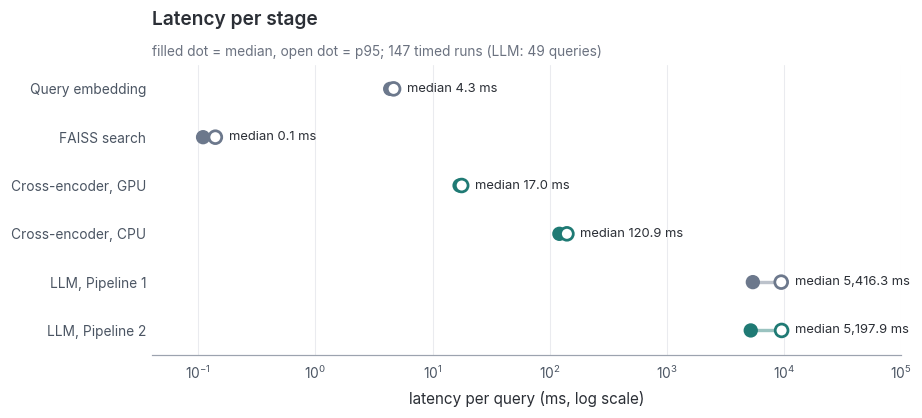

In [77]:
bars = ["query embedding (bi-encoder)", "FAISS search (flat IP, Top 10)", "cross-encoder, 10 pairs (GPU)",
        "cross-encoder, 10 pairs (CPU)", "LLM generation, Pipeline 1", "LLM generation, Pipeline 2"]
labels = ["Query embedding", "FAISS search", "Cross-encoder, GPU", "Cross-encoder, CPU",
          "LLM, Pipeline 1", "LLM, Pipeline 2"]
cols = [C_BASE, C_BASE, C_RERANK, C_RERANK, C_BASE, C_RERANK]
med = latency_table.loc[bars, "median_ms"].values
p95 = latency_table.loc[bars, "p95_ms"].values

fig, ax = plt.subplots(figsize=(8.5, 3.9))
y = np.arange(len(bars))
ax.hlines(y, med, p95, color=cols, lw=2.2, alpha=0.45, zorder=2)
ax.scatter(med, y, s=70, color=cols, zorder=3)
ax.scatter(p95, y, s=70, facecolor="white", edgecolor=cols, linewidth=1.8, zorder=3)
for yi, m, q in zip(y, med, p95):
    ax.text(q * 1.3, yi, f"median {m:,.1f} ms", ha="left", va="center", fontsize=8.5, color=C_INK)
ax.set_xscale("log")
ax.set_xlim(0.04, 1e5)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set_ylim(len(bars) - 0.5, -0.5)
ax.grid(axis="x", alpha=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("latency per query (ms, log scale)")
ax.set_title("Latency per stage")
subtitle(ax, f"filled dot = median, open dot = p95; {len(lat)} timed runs (LLM: {len(QUERIES)} queries)")
sns.despine(ax=ax, left=True)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "latency.png", dpi=200, bbox_inches="tight")
plt.show()

## 13. Scaling experiment: why not cross-encode the whole corpus?

A bi-encoder embeds documents *offline*; at query time it needs one query embedding plus a nearest-neighbour search. A cross-encoder needs the query and the document in the same forward pass, so scoring a corpus of N chunks costs N forward passes *per query*.

Measured here for three queries:
1. time to score **all** N chunks with the cross-encoder (batch size 64, GPU), giving a per-pair cost;
2. time of query embedding + full FAISS search over all N chunks.

These are extrapolated linearly to larger corpora (the flat-index search is linear in N; the cross-encoder cost is N pairs). The two-stage column is the pipeline of this assignment: bi-encoder search over N, then 10 cross-encoder pairs.

As an additional data point, the gold rank under a **full-corpus** cross-encoder ranking is computed for every query (no Top-10 restriction).

**Concept: why the second stage is only a few candidates.** The cross-encoder cost grows linearly with the number of chunks and starts again for every new question. The bi-encoder pays the heavy cost once, when the chunks are embedded. The measurement here is on 747 chunks, and larger sizes are extrapolated from it.

In [78]:
SCALING_QIDS = ["Q04", "Q11", "Q18"]

N_CHUNKS = len(CHUNKS)

all_chunk_texts = [c["text"] for c in CHUNKS]

**`full_ce_scores(query)`**

Cross-encoder scores for the query against every chunk (timed, ms).

In [79]:
def full_ce_scores(query):
    """Cross-encoder scores for the query against every chunk (timed, ms)."""
    pairs = [(query, t) for t in all_chunk_texts]
    sync(); t0 = time.perf_counter()
    s = ce_scores(cross_encoder, pairs, batch_size=64)
    sync()
    return s, (time.perf_counter() - t0) * 1000

**`bi_full_search(query)`**

Query embedding + search over all chunks (timed, ms) -> ranked chunk ids.

In [80]:
def bi_full_search(query):
    """Query embedding + search over all chunks (timed, ms) -> ranked chunk ids."""
    sync(); t0 = time.perf_counter()
    q = embed_query(query)
    sync(); t1 = time.perf_counter()
    _, ids = index.search(q, N_CHUNKS)
    t2 = time.perf_counter()
    return ids[0], (t1 - t0) * 1000, (t2 - t1) * 1000

In [81]:
full_ce_scores(QBY["Q01"]["query"])        # warm-up

scal_rows, rank_rows = [], []

for q in QUERIES:
    gold = set(gold_chunk_ids(q))
    s, ce_ms = full_ce_scores(q["query"])
    ids_bi, emb_ms, search_ms = bi_full_search(q["query"])
    ce_order = np.argsort(-s)
    rank_rows.append(dict(id=q["id"],
                          gold_rank_full_bi=best_rank(ids_bi.tolist(), gold),
                          gold_rank_full_ce=best_rank(ce_order.tolist(), gold)))
    if q["id"] in SCALING_QIDS:
        scal_rows.append(dict(id=q["id"], n_chunks=N_CHUNKS, ce_all_ms=ce_ms, ce_ms_per_pair=ce_ms / N_CHUNKS,
                              bi_embed_ms=emb_ms, bi_search_ms=search_ms))

measured = pd.DataFrame(scal_rows).set_index("id")

display(measured.round(3))

,n_chunks,ce_all_ms,ce_ms_per_pair,bi_embed_ms,bi_search_ms
id,,,,,
Q04,747,848.408,1.136,4.376,0.151
Q11,747,875.178,1.172,4.441,0.137
Q18,747,870.092,1.165,4.956,0.137


In [82]:
per_pair_ms = measured["ce_ms_per_pair"].median()

embed_ms    = measured["bi_embed_ms"].median()

search_ms_n = measured["bi_search_ms"].median()          # search over N_CHUNKS chunks

search_ms_per_chunk = search_ms_n / N_CHUNKS

**`human(ms)`**

Turns a time in milliseconds into a readable text such as `4.6 ms`, `19.7 min` or `3.3 h`, used for the labels on the scaling figure.

In [83]:
def human(ms):
    s = ms / 1000
    if s < 1:      return f"{ms:.1f} ms"
    if s < 120:    return f"{s:.1f} s"
    if s < 7200:   return f"{s / 60:.1f} min"
    if s < 172800: return f"{s / 3600:.1f} h"
    return f"{s / 86400:.1f} days"

In [84]:
scal = []

for n in [N_CHUNKS, 10_000, 100_000, 1_000_000, 10_000_000]:
    bi_ms = embed_ms + search_ms_per_chunk * n                  # embedding + linear flat search
    ce_ms = per_pair_ms * n                                     # N forward passes per query
    two_ms = bi_ms + per_pair_ms * TOP_K_RETRIEVE               # bi-encoder over N + 10 CE pairs
    scal.append(dict(n_chunks=n, bi_encoder_ms=bi_ms, cross_encoder_all_ms=ce_ms, two_stage_ms=two_ms,
                     ce_all_over_bi=ce_ms / bi_ms,
                     bi_encoder=human(bi_ms), cross_encoder_all=human(ce_ms), two_stage=human(two_ms)))

scaling = pd.DataFrame(scal)

scaling.to_csv(RESULTS_DIR / "scaling.csv", index=False)

print(f"per-pair cross-encoder cost: {per_pair_ms:.3f} ms | query embedding: {embed_ms:.2f} ms | "
      f"flat search: {search_ms_per_chunk * 1000:.3f} us per chunk")

display(scaling[["n_chunks", "bi_encoder", "cross_encoder_all", "two_stage", "ce_all_over_bi"]]
        .assign(ce_all_over_bi=scaling["ce_all_over_bi"].round(0)).set_index("n_chunks"))

# Gold rank when the cross-encoder ranks the whole corpus (no Top-10 restriction)
full_rank = pd.DataFrame(rank_rows).merge(runs[["id", "gold_rank_baseline", "gold_rank_reranked"]], on="id")

full_rank = full_rank.rename(columns={"gold_rank_baseline": "gold_rank_top10_bi",
                                      "gold_rank_reranked": "gold_rank_top10_rerank"})

display(full_rank.set_index("id"))

per-pair cross-encoder cost: 1.165 ms | query embedding: 4.44 ms | flat search: 0.184 us per chunk


,bi_encoder,cross_encoder_all,two_stage,ce_all_over_bi
n_chunks,,,,
747,4.6 ms,870.1 ms,16.2 ms,190.0
10000,6.3 ms,11.6 s,17.9 ms,1855.0
100000,22.8 ms,116.5 s,34.5 ms,5105.0
1000000,188.2 ms,19.4 min,199.8 ms,6189.0
10000000,1.8 s,3.2 h,1.9 s,6323.0


,gold_rank_full_bi,gold_rank_full_ce,gold_rank_top10_bi,gold_rank_top10_rerank
id,,,,
Q01,3,3,3,3
Q02,4,2,4,2
Q03,1,2,1,2
Q04,13,15,<NA>,<NA>
Q05,4,5,4,4
Q06,16,1,<NA>,<NA>
Q07,5,8,5,5
Q08,3,2,3,2
Q09,3,3,3,3


## 14. Rank-shift figure

One row per query: the arrow goes from the best gold rank under the baseline (bi-encoder order) to the best gold rank after re-ranking. Rank 1 is on the left; the column "not in top 10" holds queries whose gold chunk the bi-encoder never retrieved, so re-ranking could not reach it. The shaded band is the Top 3, i.e. the chunks that are sent to the LLM. Teal = gold moved up, red = moved down, grey = unchanged; ★ marks the showcase cases (baseline rank 4–10 moved into the Top 3).

**Concept: rank shift.** For every question the figure compares where the best right clause sat before and after re-ranking, and whether it crossed the line into the top 3 that reaches the prompt.

In [85]:
NOT_IN_TOP10 = 11.5                            # x-position used for "not in top 10"

**`rank_or_out(v)`**

Puts a missing rank (right clause not in the top 10) at the extra position on the right of the rank-shift figure.

In [86]:
def rank_or_out(v):
    return NOT_IN_TOP10 if pd.isna(v) else int(v)

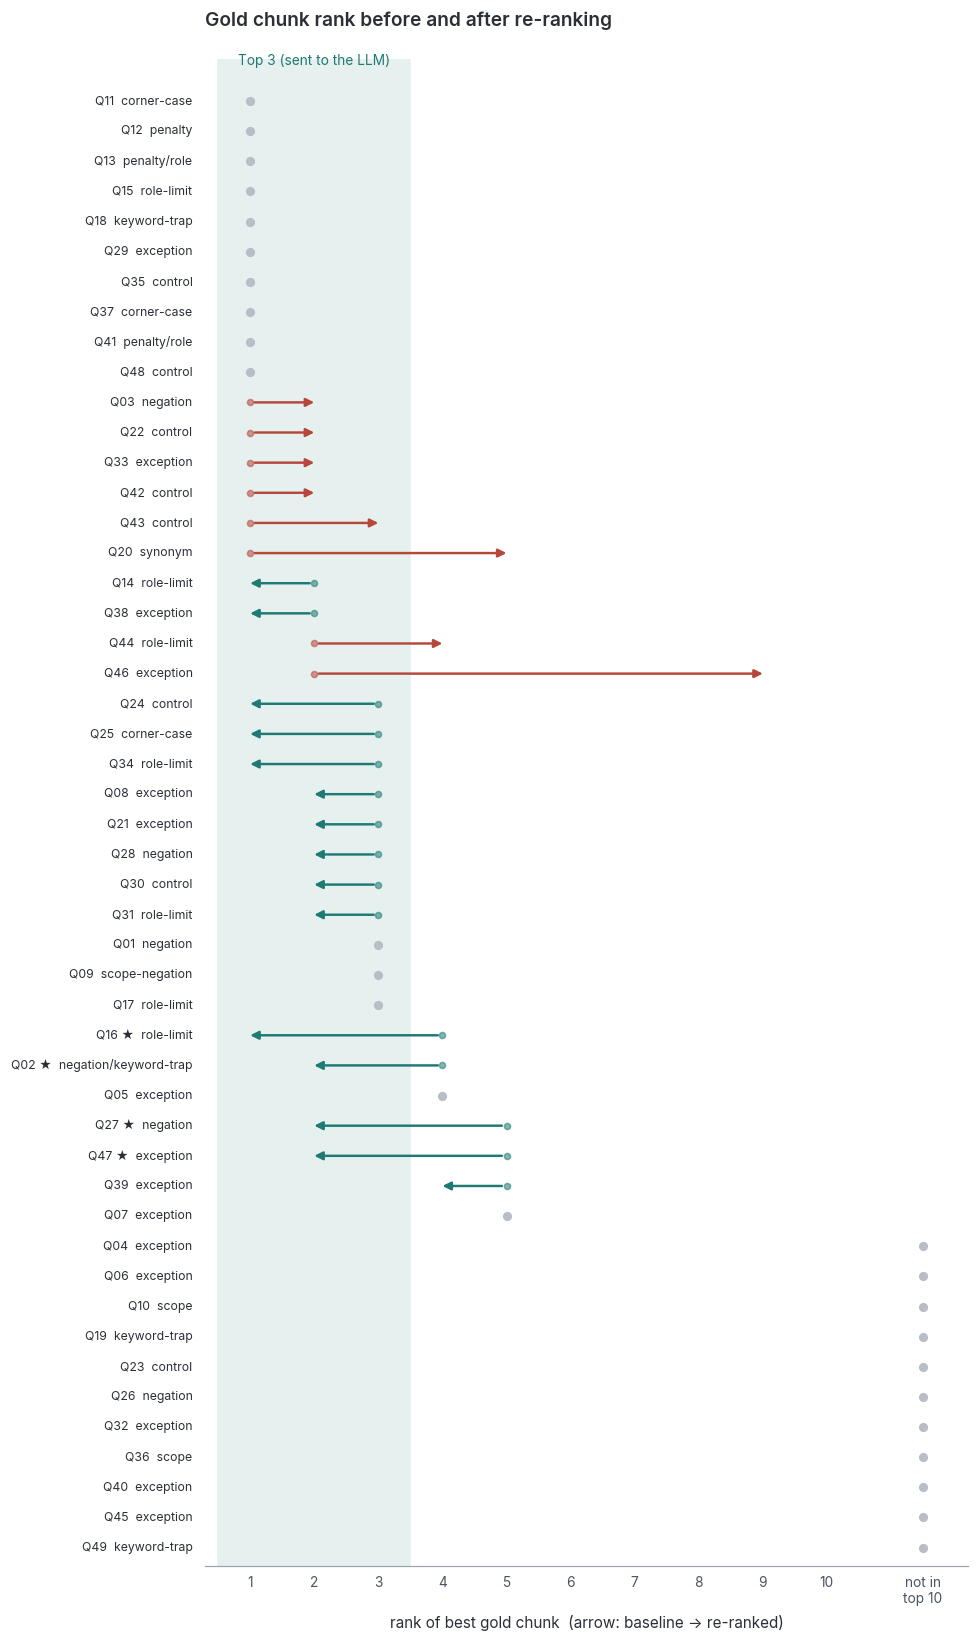

In [87]:
plot_df = runs.assign(x0=runs["gold_rank_baseline"].map(rank_or_out),
                      x1=runs["gold_rank_reranked"].map(rank_or_out))

plot_df = plot_df.sort_values(["x0", "x1", "id"], ascending=[True, True, True]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 0.27 * len(plot_df) + 1.8))

ax.axvspan(0.5, 3.5, color="#E6F0EF", zorder=0)

ax.text(2.0, -1.1, "Top 3 (sent to the LLM)", ha="center", va="bottom", fontsize=9, color=C_RERANK)

for y, r in plot_df.iterrows():
    x0, x1 = r["x0"], r["x1"]
    color = C_UP if x1 < x0 else (C_DOWN if x1 > x0 else C_NEUTRAL)
    if x0 == x1:
        ax.plot(x0, y, "o", color=color, markersize=5, zorder=3)
    else:
        ax.annotate("", xy=(x1, y), xytext=(x0, y),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6, shrinkA=3, shrinkB=0,
                                    mutation_scale=11), zorder=3)
        ax.plot(x0, y, "o", color=color, markersize=4, zorder=3, alpha=0.55)
    star = " \u2605" if r["showcase"] else ""
    ax.text(0.1, y, f"{r['id']}{star}  {r['category']}", ha="right", va="center", fontsize=8, color=C_INK)

ax.set_yticks([])

ax.set_ylim(len(plot_df) - 0.4, -1.4)          # first query at the top

ax.set_xlim(0.3, 12.2)

ax.set_xticks(list(range(1, 11)) + [NOT_IN_TOP10])

ax.set_xticklabels([str(i) for i in range(1, 11)] + ["not in\ntop 10"])

ax.set_xlabel("rank of best gold chunk  (arrow: baseline \u2192 re-ranked)")

ax.set_title("Gold chunk rank before and after re-ranking", pad=22)

sns.despine(ax=ax, left=True)

fig.tight_layout()

fig.savefig(FIG_DIR / "rank_shift.png", dpi=200, bbox_inches="tight")

plt.show()

## 15. Reproducibility check

Two queries are regenerated for both pipelines with the cache bypassed (`force=True`, nothing written back) and compared with the cached answers. Decoding uses temperature 0 and a fixed seed, so the texts are expected to match; a mismatch is reported, not treated as an error.

**Concept: reproducibility.** With temperature 0 and a fixed seed the LLM should repeat itself. This check regenerates a few answers and compares them with the saved ones.

In [88]:
check_ids = ["Q01", "Q11"]
for qid in check_ids:
    for p in ("baseline", "rerank"):
        fresh = answer_query(p, QBY[qid]["query"], force=True, save=False)
        same = fresh["answer"] == ANSWERS[(p, qid)]["answer"]
        print(f"{qid} {p:9s} identical to cached answer: {same}")
        if not same:
            print("   cached:", ANSWERS[(p, qid)]["answer"][:200].replace("\n", " "))
            print("   fresh :", fresh["answer"][:200].replace("\n", " "))

Q01 baseline  identical to cached answer: False
   cached: No, it is not allowed to use AI to infer emotions of natural persons in the areas of workplace and education institutions, except where the use of the AI system is intended to be put in place or into 
   fresh : No, it is not allowed to use AI to infer emotions of natural persons in the areas of workplace and education institutions, except where the use of the AI system is intended to be put in place or into 


Q01 rerank    identical to cached answer: False
   cached: The placing on the market, the putting into service, or the use of AI systems intended to be used to detect the emotional state of individuals in situations related to the workplace and education shou
   fresh : The placing on the market, the putting into service, or the use of AI systems intended to be used to detect the emotional state of individuals in situations related to the workplace and education shou


Q11 baseline  identical to cached answer: True


Q11 rerank    identical to cached answer: True


## 16. More figures

Additional views of the data that is already in memory (`retrieval_runs`, `runs`, `answers_df`, `lat`, `scaling`, `full_rank`). They all use the global style and the colour convention from the configuration cell: slate = baseline (Pipeline 1), teal = re-ranked (Pipeline 2), grey = unchanged or other. No new retrieval or LLM calls are made. Every figure is saved to `results/figures/`.

**Concept: figures.** These figures look at the same results from other sides: how the two models' scores relate, how ranks move, how each question type behaves, what kind of chunk reaches the LLM, and how time grows with collection size.

### 16.1 Bi-encoder score vs cross-encoder score

Each point is one (query, candidate) pair from the Top 10 lists, 10 per query. x is the bi-encoder cosine similarity, y the raw cross-encoder logit. Pairs whose chunk is a gold chunk are drawn in teal; the Spearman rank correlation over all pairs is printed in the corner. The two scores live on different scales, so only their ordering is comparable.

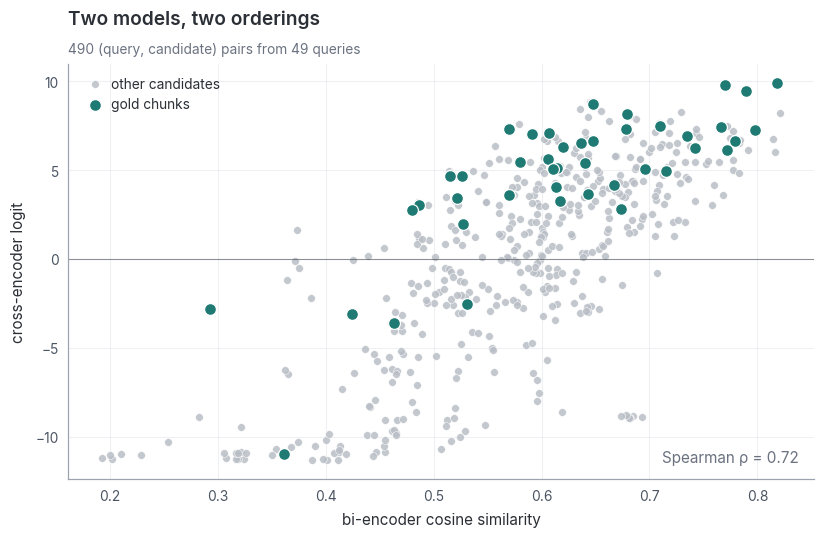

In [89]:
rr = retrieval_runs.copy()
rho = rr["bi_score"].corr(rr["ce_score"], method="spearman")

fig, ax = plt.subplots(figsize=(7.6, 5))
sns.scatterplot(data=rr[~rr["is_gold"]], x="bi_score", y="ce_score", s=26, color=C_NEUTRAL,
                edgecolor="white", linewidth=0.4, alpha=0.85, ax=ax, label="other candidates")
sns.scatterplot(data=rr[rr["is_gold"]], x="bi_score", y="ce_score", s=60, color=C_RERANK,
                edgecolor="white", linewidth=0.8, ax=ax, label="gold chunks", zorder=3)
ax.axhline(0, color=C_INK, lw=0.7, alpha=0.5)
ax.set_xlabel("bi-encoder cosine similarity")
ax.set_ylabel("cross-encoder logit")
ax.set_title("Two models, two orderings")
subtitle(ax, f"{len(rr)} (query, candidate) pairs from {rr['query_id'].nunique()} queries")
ax.text(0.98, 0.04, f"Spearman ρ = {rho:.2f}", transform=ax.transAxes, ha="right", fontsize=10, color=C_MUTED)
ax.legend(loc="upper left", handletextpad=0.2)
ax.grid(alpha=0.6)
ax.set_axisbelow(True)
sns.despine(ax=ax)
fig.tight_layout()
save_fig(fig, "score_scatter.png")

### 16.2 Where do candidates move?

Counts of candidates over all queries, by bi-encoder rank (rows) and cross-encoder rank (columns); both are positions within the same Top 10 list. The outlined block is the Top 3 on both sides, i.e. candidates that were in the context before and after re-ranking.

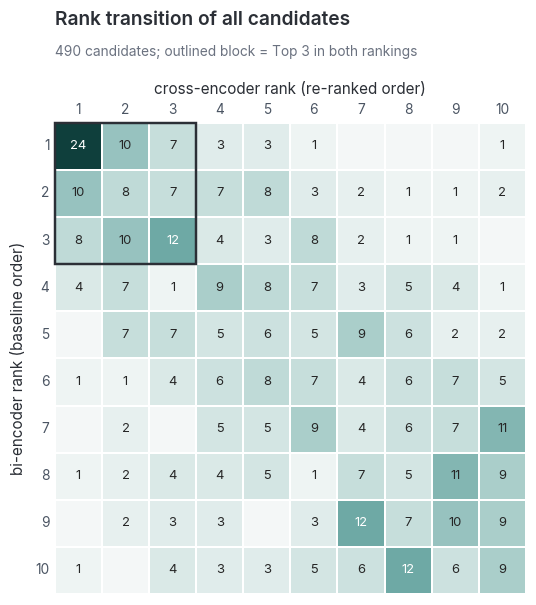

In [90]:
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

tr = pd.crosstab(retrieval_runs["bi_rank"], retrieval_runs["ce_rank"]).reindex(
    index=range(1, 11), columns=range(1, 11), fill_value=0)
cmap = LinearSegmentedColormap.from_list("teal_seq", ["#F4F7F7", "#BFDAD7", C_RERANK, "#0F3F3C"])

fig, ax = plt.subplots(figsize=(6.6, 5.6))
sns.heatmap(tr, cmap=cmap, annot=tr.where(tr > 0, ""), fmt="", annot_kws=dict(fontsize=8.5),
            linewidths=1.2, linecolor="white", cbar=False, square=True, ax=ax)
for t in ax.texts:                                   # white text on dark cells
    try:
        if int(t.get_text()) > 0.55 * tr.values.max():
            t.set_color("white")
    except ValueError:
        pass
ax.add_patch(Rectangle((0, 0), 3, 3, fill=False, edgecolor=C_INK, lw=1.6, clip_on=False))
ax.set_xlabel("cross-encoder rank (re-ranked order)")
ax.set_ylabel("bi-encoder rank (baseline order)")
ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
ax.tick_params(length=0, labelrotation=0)
ax.set_title("Rank transition of all candidates", pad=64)
subtitle(ax, f"{len(retrieval_runs)} candidates; outlined block = Top 3 in both rankings", y=1.135)
fig.tight_layout()
save_fig(fig, "rank_transition.png")

### 16.3 Retrieval metrics by query category

Per-category hit@3 and MRR@10 for the baseline and the re-ranked pipeline (one row per category, a line connects the two values). Categories with fewer than 3 queries are pooled into "other"; the number of queries is shown in each label.

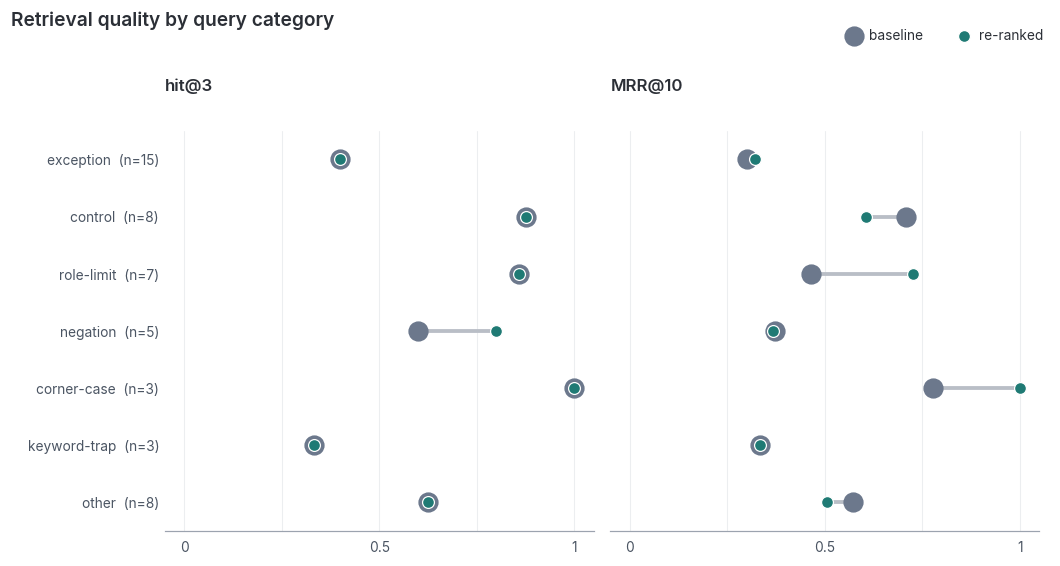

In [91]:
cat_counts = runs["category"].value_counts()
runs_c = runs.assign(cat=runs["category"].where(runs["category"].map(cat_counts) >= 3, "other"))
agg = runs_c.groupby("cat").agg(n=("id", "size"), hit_b=("hit3_baseline", "mean"), hit_r=("hit3_reranked", "mean"),
                                mrr_b=("mrr10_baseline", "mean"), mrr_r=("mrr10_reranked", "mean"))
agg = agg.sort_values(["n"], ascending=False)
agg = pd.concat([agg.drop(index="other", errors="ignore"), agg.loc[agg.index == "other"]])   # "other" last
ylab = [f"{c}  (n={int(n)})" for c, n in zip(agg.index, agg["n"])]

fig, axes = plt.subplots(1, 2, figsize=(9.5, 0.45 * len(agg) + 1.8), sharey=True)
for ax, (b, r, title) in zip(axes, [("hit_b", "hit_r", "hit@3"), ("mrr_b", "mrr_r", "MRR@10")]):
    y = np.arange(len(agg))
    ax.hlines(y, agg[b], agg[r], color=C_NEUTRAL, lw=2.5, zorder=1)
    ax.scatter(agg[b], y, s=150, color=C_BASE, zorder=2, label="baseline")
    ax.scatter(agg[r], y, s=60, color=C_RERANK, edgecolor="white", linewidth=0.8, zorder=3, label="re-ranked")
    ax.set_xlim(-0.05, 1.05)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_xticklabels(["0", "", "0.5", "", "1"])
    ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="y", length=0)
    sns.despine(ax=ax, left=True)
axes[0].set_yticks(np.arange(len(agg))); axes[0].set_yticklabels(ylab)
axes[0].set_ylim(len(agg) - 0.5, -0.5)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.02), handletextpad=0.1)
fig.suptitle("Retrieval quality by query category", x=0.0, ha="left", fontsize=12.5, fontweight="semibold", y=1.03)
fig.tight_layout()
save_fig(fig, "category_metrics.png")

### 16.4 What kind of chunk reaches the LLM?

Share of recitals, articles and annexes among the Top-3 chunks that are placed in the prompt, summed over all queries, for the baseline order (bi-encoder) and the re-ranked order (cross-encoder). The unit type is read from the chunk header.

**`unit_of(h)`**

Reads a chunk header and tells whether the chunk is a recital, an article or an annex.

In [92]:
def unit_of(h):
    h = h.lower()
    return "recital" if h.startswith("[recital") else ("annex" if h.startswith("[annex") else "article")

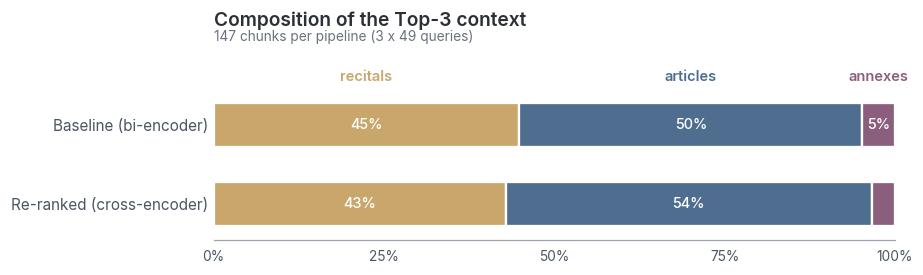

In [93]:
rt = retrieval_runs.assign(unit=retrieval_runs["header"].map(unit_of))

comp = pd.DataFrame({
    "Baseline (bi-encoder)":    rt[rt["bi_rank"] <= TOP_K_CONTEXT]["unit"].value_counts(),
    "Re-ranked (cross-encoder)": rt[rt["ce_rank"] <= TOP_K_CONTEXT]["unit"].value_counts(),
}).T.reindex(columns=["recital", "article", "annex"]).fillna(0)

share = comp.div(comp.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8.5, 2.6))

left = np.zeros(len(share))

for u in share.columns:
    ax.barh(share.index, share[u], left=left, color=UNIT_COLORS[u], height=0.55, edgecolor="white", linewidth=1.5)
    for yi, (l0, v, n) in enumerate(zip(left, share[u], comp[u])):
        if v >= 4:
            ax.text(l0 + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9.5, color="white", fontweight="medium")
    left += share[u].values

for u, x in zip(share.columns, np.cumsum(share.iloc[0].values) - share.iloc[0].values / 2):
    ax.text(x, -0.52, {"recital": "recitals", "article": "articles", "annex": "annexes"}[u], ha="center", va="bottom", fontsize=9.5, color=UNIT_COLORS[u], fontweight="semibold")

ax.set_ylim(1.45, -0.75)

ax.set_xlim(0, 100)

ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])



ax.tick_params(axis="y", length=0, labelsize=10)

ax.set_title("Composition of the Top-3 context", pad=26)

subtitle(ax, f"{int(comp.iloc[0].sum())} chunks per pipeline (3 x {len(runs)} queries)", y=1.12)

sns.despine(ax=ax, left=True)

fig.tight_layout()

save_fig(fig, "context_composition.png")

### 16.5 Key-fact coverage per query

Each bar is one query: coverage of Answer 2 (re-ranking) minus coverage of Answer 1 (baseline), sorted from largest gain to largest loss. Coverage is the share of the expected key facts found in the answer (0 to 1). Queries with identical coverage have no bar.

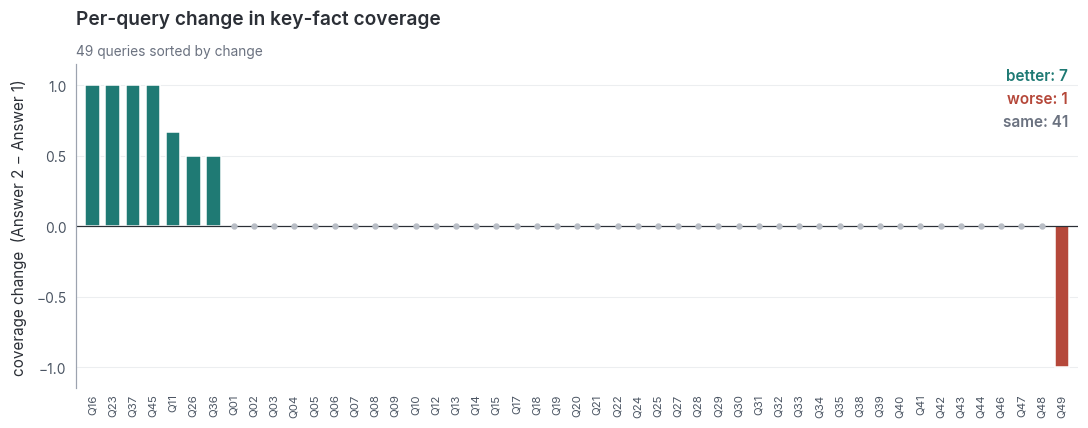

In [94]:
cv = answers_df[["id", "coverage_1", "coverage_2"]].copy()
cv["diff"] = cv["coverage_2"] - cv["coverage_1"]
cv = cv.sort_values(["diff", "id"], ascending=[False, True]).reset_index(drop=True)
n_up, n_down, n_same = (cv["diff"] > 1e-9).sum(), (cv["diff"] < -1e-9).sum(), (cv["diff"].abs() <= 1e-9).sum()
colors = np.where(cv["diff"] > 1e-9, C_UP, np.where(cv["diff"] < -1e-9, C_DOWN, C_NEUTRAL))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cv))
ax.bar(x, cv["diff"], color=colors, width=0.72)
ax.scatter(x[cv["diff"].abs() <= 1e-9], np.zeros(n_same), s=10, color=C_NEUTRAL, zorder=3)
ax.axhline(0, color=C_INK, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(cv["id"], rotation=90, fontsize=7.5)
ax.set_xlim(-0.8, len(cv) - 0.2)
lim = max(0.25, cv["diff"].abs().max() * 1.15)
ax.set_ylim(-lim, lim)
ax.set_ylabel("coverage change  (Answer 2 − Answer 1)")
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True)
ax.set_title("Per-query change in key-fact coverage")
subtitle(ax, f"{len(cv)} queries sorted by change")
ax.text(0.99, 0.95, f"better: {n_up}", transform=ax.transAxes, ha="right", color=C_UP, fontweight="semibold")
ax.text(0.99, 0.88, f"worse: {n_down}", transform=ax.transAxes, ha="right", color=C_DOWN, fontweight="semibold")
ax.text(0.99, 0.81, f"same: {n_same}", transform=ax.transAxes, ha="right", color=C_MUTED, fontweight="semibold")
sns.despine(ax=ax, bottom=True)
ax.tick_params(axis="x", length=0)
fig.tight_layout()
save_fig(fig, "coverage_paired.png")

### 16.6 Latency distribution per stage

Every individual timed run (points) with a box showing the quartiles, on a log axis. Retrieval stages come from the `lat` table (3 repeats x all queries); LLM times are taken per run from the answer-generation timings of the same query.

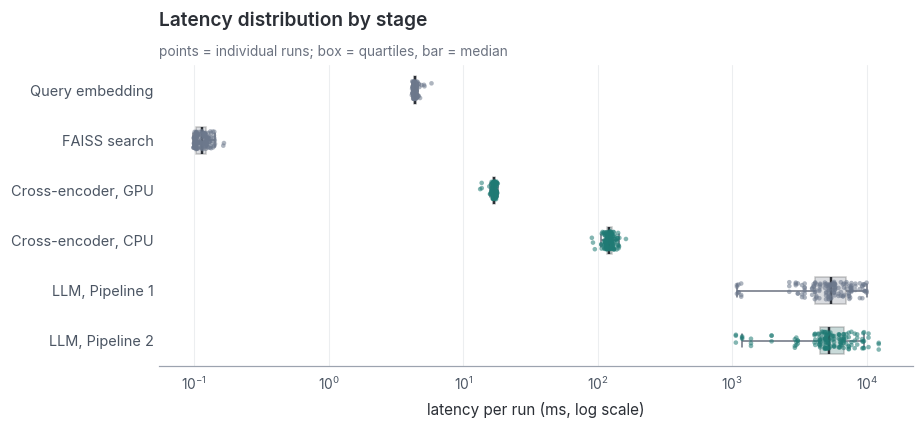

In [95]:
dist = pd.concat([
    pd.DataFrame({"stage": "Query embedding",     "ms": lat["embed_ms"]}),
    pd.DataFrame({"stage": "FAISS search",        "ms": lat["search_ms"]}),
    pd.DataFrame({"stage": "Cross-encoder, GPU",  "ms": lat["rerank_ms"]}),
    pd.DataFrame({"stage": "Cross-encoder, CPU",  "ms": lat["rerank_cpu_ms"]}),
    pd.DataFrame({"stage": "LLM, Pipeline 1",     "ms": llm_base}),
    pd.DataFrame({"stage": "LLM, Pipeline 2",     "ms": llm_rr}),
], ignore_index=True)
order = dist["stage"].unique().tolist()
pal = dict(zip(order, [C_BASE, C_BASE, C_RERANK, C_RERANK, C_BASE, C_RERANK]))

fig, ax = plt.subplots(figsize=(8.5, 4))
sns.boxplot(data=dist, x="ms", y="stage", order=order, hue="stage", palette=pal, legend=False, width=0.55,
            fliersize=0, linewidth=1, boxprops=dict(alpha=0.25), whiskerprops=dict(color="#6B7280"),
            capprops=dict(color="#6B7280"), medianprops=dict(color=C_INK, lw=1.6), ax=ax)
sns.stripplot(data=dist, x="ms", y="stage", order=order, hue="stage", palette=pal, legend=False, size=3,
              alpha=0.55, jitter=0.18, linewidth=0, ax=ax)
ax.set_xscale("log")
ax.set_xlabel("latency per run (ms, log scale)"); ax.set_ylabel("")
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelsize=9.5)
ax.set_title("Latency distribution by stage")
subtitle(ax, "points = individual runs; box = quartiles, bar = median")
sns.despine(ax=ax, left=True)
fig.tight_layout()
save_fig(fig, "latency_dist.png")

### 16.7 Query-time cost vs corpus size

Cost per query (bi-encoder: embedding + flat search; full cross-encoder: one forward pass per chunk; two-stage: bi-encoder plus 10 cross-encoder pairs) as a function of the number of chunks, on log-log axes. The filled marker is the measured corpus size; the remaining points are linear extrapolations of the measured per-pair and per-chunk costs (dashed).

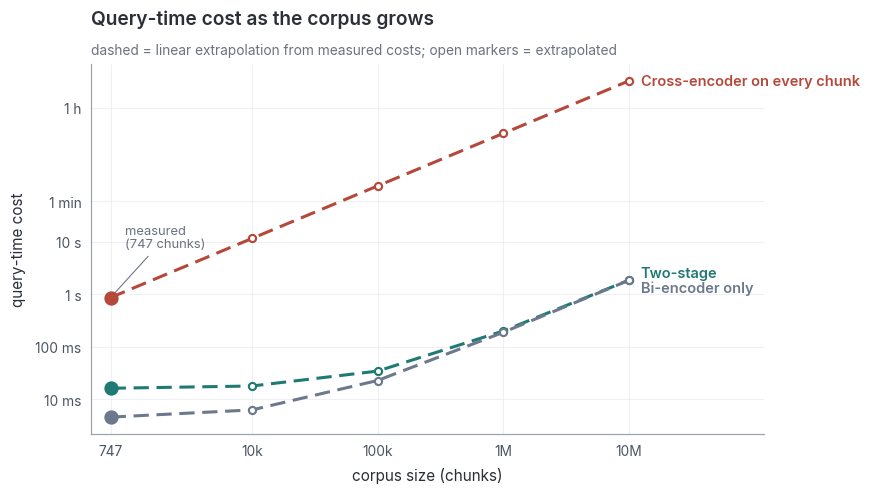

In [96]:
from matplotlib.ticker import FuncFormatter, FixedLocator

series = [("cross_encoder_all_ms", "Cross-encoder on every chunk", C_DOWN),
          ("two_stage_ms", "Two-stage", C_RERANK),
          ("bi_encoder_ms", "Bi-encoder only", C_BASE)]
fig, ax = plt.subplots(figsize=(8, 4.6))
for col, name, c in series:
    ax.plot(scaling["n_chunks"], scaling[col], color=c, lw=2, ls=(0, (5, 2.5)), zorder=2)
    ax.scatter(scaling["n_chunks"][1:], scaling[col][1:], s=22, facecolor="white", edgecolor=c, linewidth=1.4, zorder=3)
    ax.scatter(scaling["n_chunks"][:1], scaling[col][:1], s=70, color=c, zorder=4)
    dy = {"two_stage_ms": 1.35, "bi_encoder_ms": 1 / 1.35}.get(col, 1)
    ax.text(scaling["n_chunks"].iloc[-1] * 1.25, scaling[col].iloc[-1] * dy, name, color=c, va="center",
            fontsize=9.5, fontweight="semibold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(scaling["n_chunks"].min() * 0.7, scaling["n_chunks"].max() * 12)
ax.set_xlabel("corpus size (chunks)")
ax.set_ylabel("query-time cost")
yt = [1, 10, 100, 1e3, 1e4, 6e4, 3.6e6, 8.64e7]
ax.yaxis.set_major_locator(FixedLocator(yt))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: {1: "1 ms", 10: "10 ms", 100: "100 ms", 1e3: "1 s", 1e4: "10 s",
                                                          6e4: "1 min", 3.6e6: "1 h", 8.64e7: "1 day"}.get(v, "")))
ax.yaxis.set_minor_locator(FixedLocator([]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}" if v < 1e4 else (f"{v/1e3:.0f}k" if v < 1e6 else f"{v/1e6:.0f}M")))
ax.set_xticks([N_CHUNKS, 10_000, 100_000, 1_000_000, 10_000_000])
ax.annotate(f"measured\n({N_CHUNKS} chunks)", xy=(N_CHUNKS, scaling["cross_encoder_all_ms"].iloc[0]),
            xytext=(N_CHUNKS * 1.3, scaling["cross_encoder_all_ms"].iloc[0] * 9), fontsize=8.5, color=C_MUTED,
            arrowprops=dict(arrowstyle="-", color=C_MUTED, lw=0.7))
ax.grid(alpha=0.6); ax.set_axisbelow(True)
ax.set_title("Query-time cost as the corpus grows")
subtitle(ax, "dashed = linear extrapolation from measured costs; open markers = extrapolated")
sns.despine(ax=ax)
fig.tight_layout()
save_fig(fig, "scaling.png")

### 16.8 Gold rank: full-corpus cross-encoder vs Top-10 re-ranking

For every query, x is the best gold rank after re-ranking only the bi-encoder Top 10 and y is the best gold rank when the cross-encoder scores the whole corpus (log scale). Queries whose gold chunk is outside the Top 10 are placed in the "not in top 10" column. Points are jittered slightly to separate overlaps; the shaded band is rank 1-3.

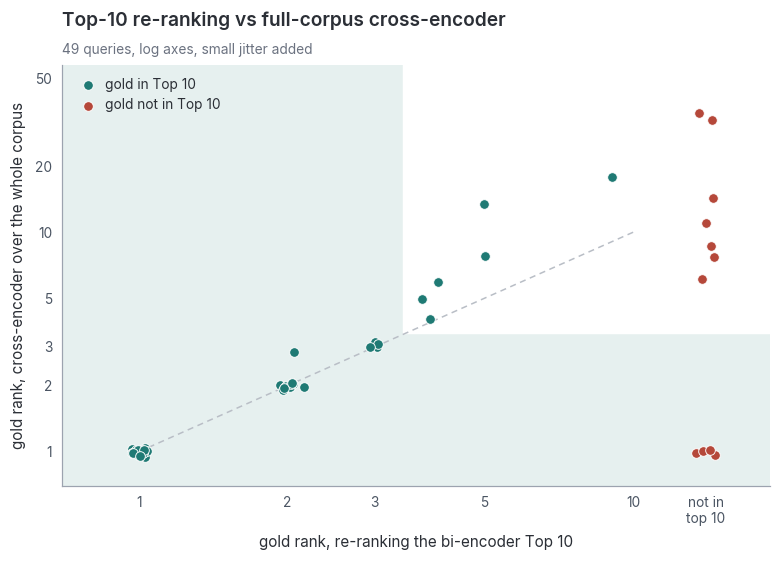

In [97]:
fr = full_rank.copy()
NOT10 = 14
fr["x"] = fr["gold_rank_top10_rerank"].astype(float).fillna(NOT10)
fr["y"] = fr["gold_rank_full_ce"].astype(float)
rng = np.random.default_rng(SEED)
fr["xj"] = fr["x"] * np.exp(rng.normal(0, 0.035, len(fr)))
fr["yj"] = fr["y"] * np.exp(rng.normal(0, 0.035, len(fr)))
miss = fr["x"] == NOT10

fig, ax = plt.subplots(figsize=(7.2, 5.2))
ax.axhspan(0.7, 3.4, color="#E6F0EF", zorder=0)
ax.axvspan(0.7, 3.4, color="#E6F0EF", zorder=0)
lim = [0.7, max(NOT10, fr["y"].max()) * 1.6]
ax.plot([1, 10], [1, 10], color=C_NEUTRAL, lw=1, ls=(0, (4, 3)), zorder=1)
ax.scatter(fr["xj"][~miss], fr["yj"][~miss], s=40, color=C_RERANK, edgecolor="white", linewidth=0.6, zorder=3,
           label="gold in Top 10")
ax.scatter(fr["xj"][miss], fr["yj"][miss], s=40, color=C_DOWN, edgecolor="white", linewidth=0.6, zorder=3,
           label="gold not in Top 10")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim[0], NOT10 * 1.35); ax.set_ylim(lim)
ticks = [1, 2, 3, 5, 10, NOT10]
ax.xaxis.set_major_locator(FixedLocator(ticks)); ax.xaxis.set_minor_locator(FixedLocator([]))
ax.set_xticklabels(["1", "2", "3", "5", "10", "not in\ntop 10"])
yt = [t for t in [1, 2, 3, 5, 10, 20, 50, 100, 200, 500] if t <= lim[1]]
ax.yaxis.set_major_locator(FixedLocator(yt)); ax.yaxis.set_minor_locator(FixedLocator([]))
ax.set_yticklabels([str(t) for t in yt])
ax.set_xlabel("gold rank, re-ranking the bi-encoder Top 10")
ax.set_ylabel("gold rank, cross-encoder over the whole corpus")
ax.set_title("Top-10 re-ranking vs full-corpus cross-encoder")
subtitle(ax, f"{len(fr)} queries, log axes, small jitter added")
ax.legend(loc="upper left", handletextpad=0.2)
sns.despine(ax=ax)
fig.tight_layout()
save_fig(fig, "full_corpus_rank.png")

## 17. Extra experiments: can retrieval be improved?

Everything above follows the assignment exactly (bi-encoder Top 10 → Top 3, or the same Top 10 → cross-encoder → Top 3). This section is **additional**. It changes one design choice at a time and measures the effect on retrieval, without the LLM:

| group | what is changed |
|---|---|
| chunking | chunk size limit 120 / 230 (default) / 400 word-pieces; chunk header on or off |
| corpus | all text vs. binding text only (articles + annexes, recitals removed) |
| candidate pool | the cross-encoder re-ranks the Top 10 (default), 20, 30 or 50 |
| first stage | bi-encoder model (MiniLM-L6, bge-small, e5-base, bge-base); hybrid = dense + BM25 merged with reciprocal rank fusion |
| re-ranker | cross-encoder MiniLM-L6 (default) vs MiniLM-L12 |
| combinations | the most useful changes together |

**Avoiding tuning on the test questions.** Q01–Q24 (written first) are used as the *dev* split to pick a configuration; Q25–Q49 are the *test* split and are only used to report. The metrics are the same as in §9; "baseline" = first-stage order, "re-ranked" = cross-encoder order of the candidate pool, and `recall_pool` = share of queries whose gold clause is inside the pool the cross-encoder sees.

Note on the corpus experiment: the gold labels point to binding text by design, so removing recitals cannot remove a gold chunk. Whether this also gives better *answers* is checked separately with the LLM below.

**Concept: what limits retrieval.** The experiments change one design choice at a time (chunk size, headers, recitals, candidate pool, first-stage model, BM25, re-ranker). Hybrid retrieval merges the dense ranking with a keyword ranking (BM25) using reciprocal rank fusion, which gives more weight to chunks that rank well in both lists. Choices are made on the dev questions and checked on the test questions.

In [98]:
import contextlib, io, math

**`header(cid)`**

Bracketed header (first line) of a chunk.

In [99]:
def header(cid):
    """Bracketed header (first line) of a chunk."""
    return CHUNKS[cid]["text"].split("\n")[0]

**`tokenize_words(s)`**

Splits a text into lowercase words and numbers, the tokens that BM25 counts.

In [100]:
def tokenize_words(s):
    return re.findall(r"[a-z0-9]+", s.lower())

**`class BM25`**

Plain Okapi BM25 over a list of texts (k1=1.5, b=0.75).

In [101]:
class BM25:
    """Plain Okapi BM25 over a list of texts (k1=1.5, b=0.75)."""
    def __init__(self, docs, k1=1.5, b=0.75):
        self.tf = [collections.Counter(tokenize_words(d)) for d in docs]
        self.len = np.array([sum(t.values()) for t in self.tf], dtype=float)
        self.avg = self.len.mean()
        df = collections.Counter(w for t in self.tf for w in t)
        n = len(docs)
        self.idf = {w: math.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}
        self.k1, self.b = k1, b

    def scores(self, query):
        s = np.zeros(len(self.tf))
        norm = self.k1 * (1 - self.b + self.b * self.len / self.avg)
        for w in set(tokenize_words(query)):
            if w in self.idf:
                f = np.array([t.get(w, 0) for t in self.tf], dtype=float)
                s += self.idf[w] * f * (self.k1 + 1) / (f + norm)
        return s

**`rrf(rankings, k=60)`**

Reciprocal rank fusion of several ranked lists of positions.

In [102]:
def rrf(rankings, k=60):
    """Reciprocal rank fusion of several ranked lists of positions."""
    score = collections.defaultdict(float)
    for ranking in rankings:
        for r, i in enumerate(ranking):
            score[i] += 1 / (k + r + 1)
    return [i for i, _ in sorted(score.items(), key=lambda x: -x[1])]

**`strip_header(text)`**

Removes the bracketed header line from a chunk, used to test what happens without headers.

In [103]:
def strip_header(text):
    return text.split("\n", 1)[1] if text.startswith("[") and "\n" in text else text

**`using_chunks(chunks)`**

Temporarily point the global CHUNKS (used by find_chunks / gold labels) at another chunking.

In [104]:
@contextlib.contextmanager
def using_chunks(chunks):
    """Temporarily point the global CHUNKS (used by find_chunks / gold labels) at another chunking."""
    global CHUNKS
    saved = CHUNKS
    CHUNKS = chunks
    try:
        yield
    finally:
        CHUNKS = saved

In [105]:
_variant_chunks = {}

**`chunks_with_limit(max_tokens)`**

Re-run the §3 chunker with a different size limit (cached).

In [106]:
def chunks_with_limit(max_tokens):
    """Re-run the §3 chunker with a different size limit (cached)."""
    global MAX_CHUNK_TOKENS
    if max_tokens not in _variant_chunks:
        saved, MAX_CHUNK_TOKENS = MAX_CHUNK_TOKENS, max_tokens
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                _variant_chunks[max_tokens] = build_chunks(rows)
        finally:
            MAX_CHUNK_TOKENS = saved
    return _variant_chunks[max_tokens]

In [107]:
# Models: re-use the two already loaded, load others on demand.
QUERY_PREFIX = {"BAAI/bge-small-en-v1.5": "Represent this sentence for searching relevant passages: ",
                "BAAI/bge-base-en-v1.5": "Represent this sentence for searching relevant passages: ",
                "intfloat/e5-base-v2": "query: "}

DOC_PREFIX = {"intfloat/e5-base-v2": "passage: "}

_bi_models = {BI_ENCODER: bi_encoder}

_ce_models = {CROSS_ENCODER: cross_encoder}

**`get_bi(name)`**

Returns a bi-encoder by name and loads it the first time it is asked for, so each model is loaded only once.

In [108]:
def get_bi(name):
    if name not in _bi_models:
        _bi_models[name] = SentenceTransformer(name, device=DEVICE)
    return _bi_models[name]

In [109]:
LARGE_RERANKERS = {"BAAI/bge-reranker-base", "BAAI/bge-reranker-v2-m3"}

**`get_ce(name)`**

Returns a cross-encoder by name and loads it the first time. The two large re-rankers are loaded in half precision so they fit in the 8 GB GPU.

In [110]:
def get_ce(name):
    if name not in _ce_models:
        kw = dict(model_kwargs={"torch_dtype": torch.float16}) if name in LARGE_RERANKERS and DEVICE == "cuda" else {}
        _ce_models[name] = CrossEncoder(name, device=DEVICE, max_length=512, **kw)
    return _ce_models[name]

**`free_large_rerankers()`**

Drop the big re-rankers from GPU memory once the ablations are done.

In [111]:
def free_large_rerankers():
    """Drop the big re-rankers from GPU memory once the ablations are done."""
    for name in LARGE_RERANKERS & set(_ce_models):
        del _ce_models[name]
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

**`run_config(name, max_tokens=MAX_CHUNK_TOKENS, bi=BI_ENCODER, ce=CROSS_ENCODER, pool=10, header=True, recitals=True, hybrid=False)`**

Retrieval-only evaluation of one configuration on all queries. Returns one row per query.

In [112]:
def run_config(name, max_tokens=MAX_CHUNK_TOKENS, bi=BI_ENCODER, ce=CROSS_ENCODER, pool=10,
               header=True, recitals=True, hybrid=False):
    """Retrieval-only evaluation of one configuration on all queries. Returns one row per query."""
    chunks = CHUNKS if max_tokens == MAX_CHUNK_TOKENS else chunks_with_limit(max_tokens)
    keep = [c for c in chunks if recitals or c["unit_type"] != "recital"]
    ids = np.array([c["chunk_id"] for c in keep])
    texts = [c["text"] if header else strip_header(c["text"]) for c in keep]
    bi_m, ce_m = get_bi(bi), get_ce(ce)
    emb = bi_m.encode([DOC_PREFIX.get(bi, "") + t for t in texts], normalize_embeddings=True,
                      batch_size=64, show_progress_bar=False)
    bm25 = BM25(texts) if hybrid else None
    out = []
    with using_chunks(chunks):
        for q in QUERIES:
            reqs = gold_requirements(q)
            gold = set().union(*reqs)
            qv = bi_m.encode([QUERY_PREFIX.get(bi, "") + q["query"]], normalize_embeddings=True,
                             show_progress_bar=False)[0]
            order = list(np.argsort(-(emb @ qv)))
            if hybrid:
                order = rrf([order[:100], list(np.argsort(-bm25.scores(q["query"])))[:100]])
            cand = order[:pool]
            first = [ids[i] for i in order[:10]]
            scores = ce_scores(ce_m, [(q["query"], texts[i]) for i in cand])
            reranked = [ids[cand[j]] for j in np.argsort(-scores)]
            rb, rr = best_rank(first, gold), best_rank(reranked[:10], gold)
            out.append(dict(config=name, id=q["id"], split="dev" if int(q["id"][1:]) <= 24 else "test",
                            hit3_base=int(bool(rb and rb <= 3)), hit3_rr=int(bool(rr and rr <= 3)),
                            all3_base=int(all(r & set(first[:3]) for r in reqs)),
                            all3_rr=int(all(r & set(reranked[:3]) for r in reqs)),
                            mrr_base=1 / rb if rb else 0.0, mrr_rr=1 / rr if rr else 0.0,
                            recall_pool=int(bool(gold & {ids[i] for i in cand})), n_chunks=len(keep)))
    return out

In [113]:
L12 = "cross-encoder/ms-marco-MiniLM-L12-v2"

ABLATIONS = [
    ("chunking",  "reference (as in §5–6)",           {}),
    ("chunking",  "chunks ≤120 tokens",                dict(max_tokens=120)),
    ("chunking",  "chunks ≤400 tokens (truncated)",    dict(max_tokens=400)),
    ("chunking",  "no chunk header",                   dict(header=False)),
    ("corpus",    "binding text only",                 dict(recitals=False)),
    ("pool",      "re-rank Top 20",                    dict(pool=20)),
    ("pool",      "re-rank Top 30",                    dict(pool=30)),
    ("pool",      "re-rank Top 50",                    dict(pool=50)),
    ("first stage", "bi-encoder bge-small",            dict(bi="BAAI/bge-small-en-v1.5")),
    ("first stage", "bi-encoder e5-base",              dict(bi="intfloat/e5-base-v2")),
    ("first stage", "bi-encoder bge-base",             dict(bi="BAAI/bge-base-en-v1.5")),
    ("first stage", "hybrid dense + BM25",             dict(hybrid=True)),
    ("re-ranker", "cross-encoder MiniLM-L12",          dict(ce=L12)),
    ("re-ranker", "cross-encoder bge-reranker-base",   dict(ce="BAAI/bge-reranker-base")),
    ("re-ranker", "cross-encoder bge-reranker-v2-m3",  dict(ce="BAAI/bge-reranker-v2-m3")),
    ("combined",  "binding + hybrid + Top 30",         dict(recitals=False, hybrid=True, pool=30)),
    ("combined",  "binding + hybrid + Top 30 + L12",   dict(recitals=False, hybrid=True, pool=30, ce=L12)),
    ("combined",  "binding + hybrid + Top 30 + bge-v2-m3", dict(recitals=False, hybrid=True, pool=30, ce="BAAI/bge-reranker-v2-m3")),
    ("combined",  "binding + ≤120 tok + hybrid + Top 30 + L12", dict(recitals=False, max_tokens=120, hybrid=True, pool=30, ce=L12)),
    ("combined",  "all text + ≤120 tok + hybrid + Top 30 + L12", dict(max_tokens=120, hybrid=True, pool=30, ce=L12)),
]

# The LLM is not needed here; unload it from GPU memory so the larger re-rankers fit on an 8 GB card.
if LLM_BACKEND == "ollama":
    import ollama
    ollama.generate(model=OLLAMA_MODEL, prompt="", keep_alive=0)

abl_rows, abl_groups = [], {}

for group, name, kw in ABLATIONS:
    abl_rows += run_config(name, **kw)
    abl_groups[name] = group

free_large_rerankers()

ablation = pd.DataFrame(abl_rows)

ablation.to_csv(RESULTS_DIR / "ablations.csv", index=False)

**`summarise_ablation(df)`**

Averages the metrics of every configuration into one table, including the separate dev and test scores.

In [114]:
def summarise_ablation(df):
    g = df.groupby("config", sort=False)
    s = pd.DataFrame({
        "group": [abl_groups[c] for c in g.groups],
        "n_chunks": g["n_chunks"].first(),
        "hit3_first": g["hit3_base"].mean(), "hit3_rerank": g["hit3_rr"].mean(),
        "all3_rerank": g["all3_rr"].mean(),
        "mrr_first": g["mrr_base"].mean(), "mrr_rerank": g["mrr_rr"].mean(),
        "recall_pool": g["recall_pool"].mean(),
        "dev_mrr_rerank": df[df.split == "dev"].groupby("config", sort=False)["mrr_rr"].mean(),
        "test_mrr_rerank": df[df.split == "test"].groupby("config", sort=False)["mrr_rr"].mean(),
    })
    return s.round(3)

In [115]:
ablation_summary = summarise_ablation(ablation)

ablation_summary.to_csv(RESULTS_DIR / "ablation_summary.csv")

display(ablation_summary)

,group,n_chunks,hit3_first,hit3_rerank,all3_rerank,mrr_first,mrr_rerank,recall_pool,dev_mrr_rerank,test_mrr_rerank
config,,,,,,,,,,
reference (as in §5–6),chunking,747,0.633,0.653,0.633,0.474,0.502,0.776,0.506,0.498
chunks ≤120 tokens,chunking,1610,0.592,0.694,0.673,0.483,0.558,0.796,0.577,0.539
chunks ≤400 tokens (truncated),chunking,467,0.449,0.551,0.551,0.340,0.444,0.653,0.503,0.387
no chunk header,chunking,747,0.469,0.592,0.551,0.378,0.496,0.735,0.505,0.487
binding text only,corpus,458,0.776,0.796,0.776,0.651,0.736,0.837,0.748,0.725
re-rank Top 20,pool,747,0.633,0.694,0.673,0.474,0.534,0.837,0.542,0.527
re-rank Top 30,pool,747,0.633,0.694,0.673,0.474,0.534,0.837,0.541,0.527
re-rank Top 50,pool,747,0.633,0.714,0.694,0.474,0.552,0.898,0.581,0.525
bi-encoder bge-small,first stage,747,0.551,0.612,0.571,0.403,0.500,0.673,0.508,0.491


### 17.1 Ablation figure

Mean reciprocal rank of the gold clause after re-ranking, per configuration, on the dev split (used for choosing) and the test split (held out). The vertical line is the reference pipeline from §6.

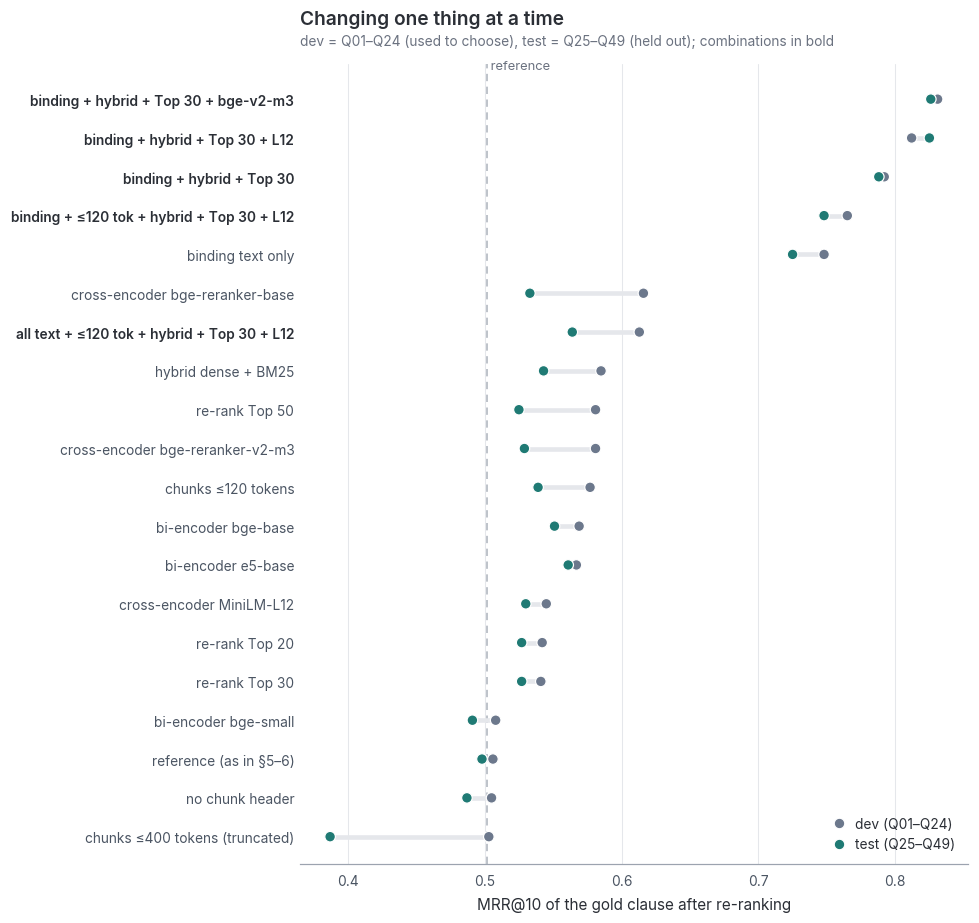

In [116]:
plot_abl = (ablation_summary.reset_index()
            .melt(id_vars=["config", "group"], value_vars=["dev_mrr_rerank", "test_mrr_rerank"],
                  var_name="split", value_name="MRR@10")
            .replace({"split": {"dev_mrr_rerank": "dev (Q01–Q24)", "test_mrr_rerank": "test (Q25–Q49)"}}))
order = ablation_summary.sort_values("dev_mrr_rerank").index.tolist()

ypos = {c: i for i, c in enumerate(order)}
fig, ax = plt.subplots(figsize=(9, 0.36 * len(order) + 1.3))
ref_mrr = ablation_summary.loc["reference (as in §5–6)", "mrr_rerank"]
ax.axvline(ref_mrr, color=C_NEUTRAL, lw=1.2, ls=(0, (4, 3)), zorder=0)
ax.text(ref_mrr, len(order) - 0.3, " reference", color=C_MUTED, fontsize=8.5, va="bottom")
for cfg in order:
    v = plot_abl.loc[plot_abl.config == cfg, "MRR@10"]
    ax.plot([v.min(), v.max()], [ypos[cfg]] * 2, color=C_GRID, lw=3, zorder=1, solid_capstyle="round")
sns.scatterplot(data=plot_abl, x="MRR@10", y=plot_abl["config"].map(ypos), hue="split",
                palette=[C_BASE, C_RERANK], s=48, zorder=2, ax=ax, edgecolor="white", linewidth=0.8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=9)
for lab, cfg in zip(ax.get_yticklabels(), order):
    lab.set_color(C_INK if abl_groups[cfg] == "combined" else "#4B5563")
    lab.set_fontweight("semibold" if abl_groups[cfg] == "combined" else "normal")
ax.set_ylabel("")
ax.set_xlabel("MRR@10 of the gold clause after re-ranking")
ax.set_ylim(-0.7, len(order) - 0.1)
ax.legend(title=None, loc="lower right", handletextpad=0.2)
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
sns.despine(left=True)
ax.set_title("Changing one thing at a time")
subtitle(ax, "dev = Q01–Q24 (used to choose), test = Q25–Q49 (held out); combinations in bold")
fig.tight_layout()
save_fig(fig, "ablations.png")

### 17.2 Pipeline 3: the configuration picked on the dev split

The configuration with the best dev MRR is used as an extra **Pipeline 3**:

1. index only the binding text (articles and annexes) with the same chunks as above;
2. first stage = bi-encoder (MiniLM-L6) and BM25, merged with reciprocal rank fusion, Top 30;
3. re-rank those 30 with `cross-encoder/ms-marco-MiniLM-L12-v2`;
4. the Top 3 go into the **same prompt** with the same LLM settings.

It answers all queries, so its answers can be compared with Answer 1 and Answer 2 using the same key-fact check.

In [117]:
P3_POOL, P3_CE = 30, get_ce(L12)

P3_IDS = np.array([c["chunk_id"] for c in CHUNKS if c["unit_type"] != "recital"])

P3_EMB = doc_emb[P3_IDS]                       # same bi-encoder vectors as §4, recitals left out

P3_BM25 = BM25([CHUNKS[i]["text"] for i in P3_IDS])

**`improved_pipeline(query)`**

Pipeline 3: binding text only, hybrid dense+BM25 Top 30, MiniLM-L12 re-ranking, Top 3.

In [118]:
def improved_pipeline(query):
    """Pipeline 3: binding text only, hybrid dense+BM25 Top 30, MiniLM-L12 re-ranking, Top 3."""
    timings = {}
    sync(); t0 = time.perf_counter()
    qv = embed_query(query)[0]
    sync(); t1 = time.perf_counter()
    dense = list(np.argsort(-(P3_EMB @ qv)))[:100]
    sparse = list(np.argsort(-P3_BM25.scores(query)))[:100]
    cand = rrf([dense, sparse])[:P3_POOL]
    t2 = time.perf_counter()
    scores = ce_scores(P3_CE, [(query, CHUNKS[P3_IDS[i]]["text"]) for i in cand])
    order = [int(P3_IDS[cand[j]]) for j in np.argsort(-scores)]
    sync(); t3 = time.perf_counter()
    timings.update(embed_ms=(t1 - t0) * 1000, search_ms=(t2 - t1) * 1000, rerank_ms=(t3 - t2) * 1000, llm_ms=None)
    top = [dict(chunk_id=cid, ce_rank=r) for r, cid in enumerate(order, start=1)]
    return dict(pipeline="improved", query=query, top10=top[:10],
                context_ids=order[:TOP_K_CONTEXT], timings=timings)

In [119]:
PIPELINES["improved"] = improved_pipeline

p3_rows = []

for q in QUERIES:
    res = answer_query("improved", q["query"])
    ANSWERS[("improved", q["id"])] = res
    reqs = gold_requirements(q)
    gold = set().union(*reqs)
    ids10 = [c["chunk_id"] for c in res["top10"]]
    r3 = best_rank(ids10, gold)
    cov, missing = key_fact_coverage(res["answer"], q["key_facts"])
    p3_rows.append(dict(id=q["id"], gold_rank_p3=r3, hit3_p3=int(bool(r3 and r3 <= 3)),
                        all3_p3=int(all(r & set(res["context_ids"]) for r in reqs)),
                        mrr_p3=1 / r3 if r3 else 0.0, coverage_3=cov, missing_3=missing,
                        abstained_3=ABSTAIN_TEXT.lower()[:30] in res["answer"].lower(),
                        context_improved=[header(c) for c in res["context_ids"]], answer_3=res["answer"],
                        retrieval_ms=res["timings"]["embed_ms"] + res["timings"]["search_ms"] + res["timings"]["rerank_ms"],
                        llm_ms_3=res["timings"]["llm_ms"]))

p3 = pd.DataFrame(p3_rows)

print("Pipeline 3 answers generated / loaded for", len(p3), "queries")

Pipeline 3 answers generated / loaded for 49 queries


### 17.3 Three pipelines side by side

Retrieval metrics, key-fact coverage of the answers, abstentions and median retrieval latency for the two required pipelines and Pipeline 3. Retrieval latency here is measured inside the answer loop (single runs), so it is less precise than §12.

In [120]:
cmp = runs[["id", "category", "hit3_baseline", "hit3_reranked", "all3_baseline", "all3_reranked",
            "mrr10_baseline", "mrr10_reranked"]].merge(
      answers_df[["id", "coverage_1", "coverage_2", "abstained_1", "abstained_2"]], on="id").merge(p3, on="id")

**`pipeline_row(name, hit, all3, mrr, cov, abst, lat_ms)`**

Makes one row of the three-pipeline comparison table (hit@3, all@3, MRR@10, key-fact coverage, abstentions and retrieval time).

In [121]:
def pipeline_row(name, hit, all3, mrr, cov, abst, lat_ms):
    return dict(pipeline=name, **{"hit@3": cmp[hit].mean(), "all@3": cmp[all3].mean(), "MRR@10": cmp[mrr].mean(),
                "key-fact coverage": cmp[cov].mean(), "abstentions": int(cmp[abst].sum()),
                "retrieval ms (median)": lat_ms})

In [122]:
p1_ms = float(latency_table.loc["Pipeline 1 retrieval (embed+search)", "median_ms"])

p2_ms = float(latency_table.loc["Pipeline 2 retrieval (+rerank, GPU)", "median_ms"])

pipeline_comparison = pd.DataFrame([
    pipeline_row("1 · bi-encoder Top 3", "hit3_baseline", "all3_baseline", "mrr10_baseline", "coverage_1", "abstained_1", p1_ms),
    pipeline_row("2 · + cross-encoder re-rank", "hit3_reranked", "all3_reranked", "mrr10_reranked", "coverage_2", "abstained_2", p2_ms),
    pipeline_row("3 · binding text, hybrid, Top 30, L12", "hit3_p3", "all3_p3", "mrr_p3", "coverage_3", "abstained_3",
                 float(p3["retrieval_ms"].median())),
]).set_index("pipeline").round(3)

pipeline_comparison.to_csv(RESULTS_DIR / "pipeline_comparison.csv")

display(pipeline_comparison)

split = cmp.assign(split=np.where(cmp["id"].str[1:].astype(int) <= 24, "dev", "test"))

display(split.groupby("split")[["mrr10_baseline", "mrr10_reranked", "mrr_p3",
                                 "coverage_1", "coverage_2", "coverage_3"]].mean().round(3))

p3.drop(columns=["missing_3"]).to_csv(RESULTS_DIR / "answers_pipeline3.csv", index=False)

,hit@3,all@3,MRR@10,key-fact coverage,abstentions,retrieval ms (median)
pipeline,,,,,,
1 · bi-encoder Top 3,0.633,0.612,0.474,0.673,3,4.470
2 · + cross-encoder re-rank,0.653,0.633,0.502,0.769,3,21.480
"3 · binding text, hybrid, Top 30, L12",0.837,0.796,0.818,0.810,3,87.422


,mrr10_baseline,mrr10_reranked,mrr_p3,coverage_1,coverage_2,coverage_3
split,,,,,,
dev,0.477,0.506,0.812,0.604,0.715,0.778
test,0.471,0.498,0.825,0.740,0.820,0.840


### 17.4 Figure: the three pipelines

Retrieval quality (hit@3, all@3, MRR@10) and the key-fact coverage of the generated answers for each pipeline, computed over all queries.

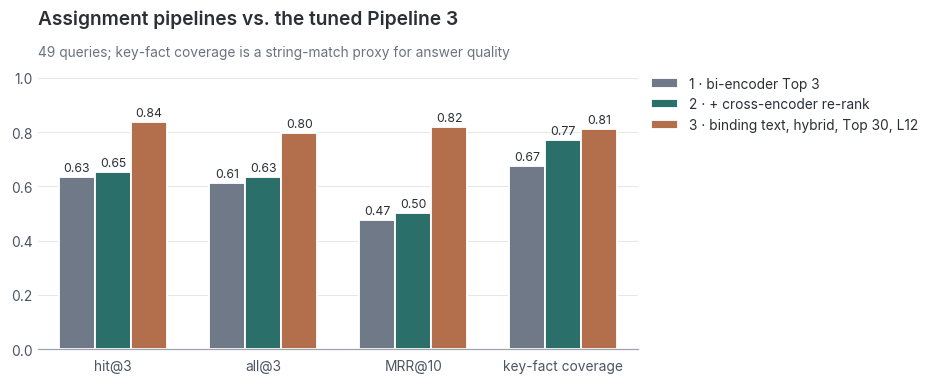

In [123]:
metrics = ["hit@3", "all@3", "MRR@10", "key-fact coverage"]
long = (pipeline_comparison[metrics].reset_index().melt(id_vars="pipeline", var_name="metric", value_name="value"))
P_COLORS = dict(zip(pipeline_comparison.index, [C_BASE, C_RERANK, "#C46A3A"]))

fig, ax = plt.subplots(figsize=(8.6, 3.6))
sns.barplot(data=long, x="metric", y="value", hue="pipeline", palette=P_COLORS, width=0.72,
            ax=ax, edgecolor="white", linewidth=1.2)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8, padding=2, color=C_INK)
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(axis="y")
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
sns.despine(left=True)
ax.tick_params(axis="y", length=0)
ax.set_title("Assignment pipelines vs. the tuned Pipeline 3")
subtitle(ax, f"{len(QUERIES)} queries; key-fact coverage is a string-match proxy for answer quality")
fig.tight_layout()
save_fig(fig, "pipelines.png")

In [124]:
# Answer 2 vs Answer 3 for the cases discussed in §11 and the corner case Q11
for qid in showcase_ids + ["Q11", "Q20", "Q46"]:
    r2, r3 = ANSWERS[("rerank", qid)], ANSWERS[("improved", qid)]
    c2 = key_fact_coverage(r2["answer"], QBY[qid]["key_facts"])[0]
    c3 = key_fact_coverage(r3["answer"], QBY[qid]["key_facts"])[0]
    print(f"{qid}: {QBY[qid]['query']}")
    print(f"  P2 context: {[header(c)[:60] for c in r2['context_ids']]}")
    print(f"  P3 context: {[header(c)[:60] for c in r3['context_ids']]}")
    print(f"  Answer 2 (coverage {c2:.2f}): {r2['answer'][:350]}")
    print(f"  Answer 3 (coverage {c3:.2f}): {r3['answer'][:350]}\n")

Q02: Is it legal to build a face recognition database by scraping photos from the internet?
  P2 context: ['[Recital 43]', '[Article 5 – Prohibited AI practices, para 1, part 4/6]', '[Recital 30]']
  P3 context: ['[Article 5 – Prohibited AI practices, para 1, part 4/6]', '[Article 50 – Transparency obligations for providers and dep', '[Article 5 – Prohibited AI practices, para 2, part 3/3]']
  Answer 2 (coverage 0.00): It is not legal to build a face recognition database by scraping photos from the internet without targeting specific individuals. This practice is explicitly prohibited as it adds to feelings of mass surveillance and can lead to gross violations of fundamental rights, including privacy. [Recital 43] Additionally, this prohibition applies to both th
  Answer 3 (coverage 0.00): It is not legal to build a face recognition database by scraping photos from the internet. This practice falls under the prohibited AI practices as stated in Article 5, para 1, part 4/6 of the EU Ar

## 18. Failure-mode analysis (assignment section 3)

The assignment asks for at least two questions where the baseline stumbles and re-ranking restores relevance, and for the document-specific failures that show up along the way: **keyword trap / distractor**, **exceptions and corner cases**, **negation and constraints**, and **a clause buried at rank 4 to 10 that is promoted into the top 3**. Role limits are a fifth type that this document adds. This section collects the evidence for each type in one place. It only reads the saved result files (`results/` and `data/chunks.jsonl`), so it can be run on its own.

**Concept: a failure mode** is a kind of question where one retriever goes wrong for a reason that can be named. A bi-encoder squeezes a whole chunk into one vector, so small words ("not", "except") and role words ("importer", "deployer") barely move it. A cross-encoder reads the question and the chunk together, so it can see them. Grouping the 49 questions by failure type shows where that difference helps, where it does not, and where the answer was never in the top 10 so that nothing could help.

In [1]:
import json, re
from pathlib import Path
import pandas as pd

fm_ranks   = pd.read_csv("results/rank_shifts.csv").set_index("id")        # best gold rank before / after re-ranking
fm_runs    = pd.read_csv("results/retrieval_runs.csv")                       # all 10 candidates per question
fm_answers = pd.read_csv("results/answers.csv").set_index("id")             # Answer 1 and Answer 2
fm_chunks  = {c["chunk_id"]: c for c in map(json.loads, open("data/chunks.jsonl", encoding="utf-8"))}
print(len(fm_ranks), "questions,", len(fm_chunks), "chunks loaded")

49 questions, 747 chunks loaded


### 18.1 Which questions test which failure type, and what happened

A question can belong to more than one type (for example Q27 is a negation question that also hinges on an exception). The table counts, for each type, how many questions had a right clause in the top 3 before and after re-ranking, how many were **fixed** (outside the top 3 before, inside after), how many were **broken** (the other way round), and how many had **no right clause in the top 10**, where re-ranking cannot help.

**`failure_types(category)`**

Map a question category to the failure types of the assignment (a category can belong to several).

In [2]:
def failure_types(category):
    """Map a question category to the failure types of the assignment (a category can belong to several)."""
    types = []
    if "keyword" in category:                       types.append("Keyword trap / distractor")
    if "exception" in category or "corner" in category: types.append("Exceptions and corner cases")
    if "negation" in category:                      types.append("Negation and constraints")
    if "role" in category:                          types.append("Role limits")
    return types

**`failure_type_table()`**

One row per failure type: questions, hit@3 before and after re-ranking, fixed, broken, not in the top 10.

In [3]:
def failure_type_table():
    """One row per failure type: questions, hit@3 before and after re-ranking, fixed, broken, not in the top 10."""
    rows = []
    groups = {}
    for qid, r in fm_ranks.iterrows():
        for t in failure_types(r["category"]):
            groups.setdefault(t, []).append(qid)
    groups["Buried at rank 4 to 10, promoted into the top 3"] = list(fm_ranks.index[fm_ranks["showcase"]])
    for t, ids in groups.items():
        d = fm_ranks.loc[ids]
        before, after = d["gold_rank_baseline"], d["gold_rank_reranked"]
        rows.append({"failure type": t, "questions": len(ids),
                     "hit@3 baseline": int((before <= 3).sum()), "hit@3 re-ranked": int((after <= 3).sum()),
                     "fixed": int(((before > 3) & (after <= 3)).sum()), "broken": int(((before <= 3) & ~(after <= 3)).sum()),
                     "not in top 10": int(before.isna().sum()), "ids": " ".join(ids)})
    return pd.DataFrame(rows).set_index("failure type")

In [4]:
pd.set_option("display.max_colwidth", 200)

display(failure_type_table())

,questions,hit@3 baseline,hit@3 re-ranked,fixed,broken,not in top 10,ids
failure type,,,,,,,
Negation and constraints,7,4,6,2,0,1,Q01 Q02 Q03 Q09 Q26 Q27 Q28
Keyword trap / distractor,4,1,2,1,0,2,Q02 Q18 Q19 Q49
Exceptions and corner cases,18,9,9,1,1,5,Q04 Q05 Q06 Q07 Q08 Q11 Q21 Q25 Q29 Q32 Q33 Q37 Q38 Q39 Q40 Q45 Q46 Q47
Role limits,9,8,8,1,1,0,Q13 Q14 Q15 Q16 Q17 Q31 Q34 Q41 Q44
"Buried at rank 4 to 10, promoted into the top 3",4,0,4,4,0,0,Q02 Q16 Q27 Q47


### 18.2 Keyword trap and distractor: does the wrong chunk look more like the question?

A keyword trap is a chunk that shares many words with the question but is not the answer, while the true answer uses different words. To measure it, `lexical_overlap` gives the share of the question's content words that also appear in a chunk. For each question below, the table compares the right clause with the **strongest distractor**, which is the wrong chunk in the baseline top 3 with the highest overlap.

In [5]:
STOPWORDS = set("a an the of to in on or and for is are be by with that this it as at from can do does what when which who how under any must may not no".split())

**`lexical_overlap(query, text)`**

Share of the question's content words (no stopwords) that also occur in `text`.

In [6]:
def lexical_overlap(query, text):
    """Share of the question's content words (no stopwords) that also occur in `text`."""
    words = lambda s: {w for w in re.findall(r"[a-z0-9]+", s.lower()) if w not in STOPWORDS and len(w) > 2}
    q = words(query)
    return len(q & words(text)) / max(1, len(q))

**`distractor_table(qids)`**

Right clause vs. strongest distractor in the baseline top 3: word overlap with the question and the ranks.

In [7]:
def distractor_table(qids):
    """Right clause vs. strongest distractor in the baseline top 3: word overlap with the question and the ranks."""
    rows = []
    for qid in qids:
        query = fm_answers.loc[qid, "query"]
        cand = fm_runs[fm_runs["query_id"] == qid].sort_values("bi_rank")
        gold = cand[cand["is_gold"]].iloc[0]
        wrong = cand[(~cand["is_gold"]) & (cand["bi_rank"] <= 3)].copy()
        wrong["overlap"] = wrong["chunk_id"].map(lambda c: lexical_overlap(query, fm_chunks[c]["text"]))
        top = wrong.sort_values("overlap", ascending=False).iloc[0]
        rows.append({"question": qid, "right clause": gold["header"][:44],
                     "overlap, right clause": round(lexical_overlap(query, fm_chunks[gold["chunk_id"]]["text"]), 2),
                     "strongest distractor": top["header"][:30], "overlap, distractor": round(top["overlap"], 2),
                     "right clause rank": f"{int(gold['bi_rank'])} -> {int(gold['ce_rank'])}"})
    return pd.DataFrame(rows).set_index("question")

In [8]:
display(distractor_table(["Q47", "Q02", "Q16", "Q27", "Q20", "Q46"]))

,right clause,"overlap, right clause",strongest distractor,"overlap, distractor",right clause rank
question,,,,,
Q47,[Annex III – High-risk AI systems referred t,0.88,"[Recital 58, part 2/3]",1.00,5 -> 2
Q02,"[Article 5 – Prohibited AI practices, para 1",0.38,[Recital 43],0.38,4 -> 2
Q16,"[Article 23 – Obligations of importers, para",0.75,[Article 23 – Obligations of i,0.62,4 -> 1
Q27,"[Article 5 – Prohibited AI practices, para 1",0.70,[Recital 30],0.50,5 -> 2
Q20,[Article 50 – Transparency obligations for p,0.17,"[Recital 132, part 1/2]",0.17,1 -> 5
Q46,"[Article 5 – Prohibited AI practices, para 1",0.57,[Article 26 – Obligations of d,0.57,2 -> 9


**Reading the table.** Q47 is the clearest distractor: Recital 58 shares every question word (overlap 1.00), the binding annex clause shares less (0.88), and the baseline ranked the recital first and the annex fifth. The cross-encoder moved the annex to rank 2. Q02 is **not** a keyword trap: its right clause shares as many words with the question as the distractor, so it is treated as a negation case below. Q20 is the opposite problem, a **different-wording trap**: "chatting with a bot" shares one word with the law's "interact directly with natural persons". The bi-encoder still found it at rank 1, but the cross-encoder pushed it to rank 5. The two date questions Q19 and Q49 were never retrieved by either model (see 18.4).

### 18.3 One worked example per failure type

For each type, one question with the rank of the right clause, what the baseline put first, and the start of Answer 1 (baseline) and Answer 2 (re-ranking). Cases where re-ranking made things worse or could not help are included on purpose.

**`worked_example(failure_type, qid, needed_phrase=None)`**

One row of evidence: rank of the right clause before and after re-ranking, top baseline chunk, and both answers.

In [9]:
def worked_example(failure_type, qid, needed_phrase=None):
    """One row of evidence: rank of the right clause before and after re-ranking, top baseline chunk, and both answers.

    If `needed_phrase` is given, the clause is tracked by its wording instead of by the gold label. This is for questions
    that need a second clause, such as the start-up cap in Q11 that the general fine does not contain.
    """
    cand = fm_runs[fm_runs["query_id"] == qid].sort_values("bi_rank")
    if needed_phrase:
        ids = [cid for cid, c in fm_chunks.items() if needed_phrase in c["text"]]
        gold = cand[cand["chunk_id"].isin(ids)]
    else:
        gold = cand[cand["is_gold"]]
    row = {"failure type": failure_type, "question": f"{qid}: {fm_answers.loc[qid, 'query']}"}
    row["right clause rank"] = "not in top 10" if gold.empty else f"{int(gold.iloc[0]['bi_rank'])} -> {int(gold.iloc[0]['ce_rank'])}"
    row["baseline put first"] = cand.iloc[0]["header"][:40]
    row["Answer 1 (baseline)"] = " ".join(str(fm_answers.loc[qid, "answer_1"]).split())[:150]
    row["Answer 2 (re-ranking)"] = " ".join(str(fm_answers.loc[qid, "answer_2"]).split())[:150]
    return row

In [10]:
examples = [("Keyword trap / distractor", "Q47"), ("Different wording (synonym)", "Q20"),
            ("Exception", "Q47"), ("Corner case (start-up cap, Art 99(6))", "Q11", "whichever thereof is lower"),
            ("Negation", "Q27"), ("Negation", "Q02"),
            ("Role limit", "Q16"), ("Buried at rank 4 to 10", "Q16")]
display(pd.DataFrame([worked_example(*e) for e in examples]).set_index("failure type"))

,question,right clause rank,baseline put first,Answer 1 (baseline),Answer 2 (re-ranking)
failure type,,,,,
Keyword trap / distractor,Q47: Are AI systems used for detecting financial fraud classified as high-risk?,5 -> 2,"[Recital 59, part 2/4]","AI systems used for detecting financial fraud are not considered high-risk under this Regulation, as they are specifically excluded from the high-risk",AI systems used for detecting financial fraud should not be considered high-risk under this Regulation. [Context 1]
Different wording (synonym),Q20: Do people have to be told that they are chatting with a bot?,1 -> 5,[Article 50 – Transparency obligations f,"Yes, people generally need to be informed that they are interacting with an AI system when using chatbots or similar systems. However, this requiremen","Yes, people should be notified that they are interacting with an AI system unless it is obvious from the context. This applies particularly when the A"
Exception,Q47: Are AI systems used for detecting financial fraud classified as high-risk?,5 -> 2,"[Recital 59, part 2/4]","AI systems used for detecting financial fraud are not considered high-risk under this Regulation, as they are specifically excluded from the high-risk",AI systems used for detecting financial fraud should not be considered high-risk under this Regulation. [Context 1]
"Corner case (start-up cap, Art 99(6))",Q11: What is the maximum fine for a start-up that puts a prohibited AI system on the market?,not in top 10,"[Article 99 – Penalties, para 3]",The provided context does not specify this.,"The maximum fine for a start-up that puts a prohibited AI system on the market is up to EUR 35,000,000 or 7% of its total worldwide annual turnover fo"
Negation,Q27: Can a company use biometric data to sort people by their race or sexual orientation?,5 -> 2,[Recital 30],"No, using biometric data to deduce or infer an individual's political opinions, trade union membership, religious or philosophical beliefs, race, sex","No, according to [Article 5 – Prohibited AI practices, para 1, part 5/6], using biometric categorisation systems that categorise individuals based on"
Negation,Q02: Is it legal to build a face recognition database by scraping photos from the internet?,4 -> 2,[Recital 43],It is not legal to build a face recognition database by scraping photos from the internet. This practice should be prohibited because it adds to the f,It is not legal to build a face recognition database by scraping photos from the internet without targeting specific individuals. This practice is exp
Role limit,Q16: What must an importer check before placing a high-risk AI system on the market?,4 -> 1,"[Article 23 – Obligations of importers,",An importer must ensure that a high-risk AI system is not in conformity with the Regulation or is falsified before placing it on the market. If there,"Before placing a high-risk AI system on the market, importers must ensure that the system is in conformity with this Regulation by verifying several a"
Buried at rank 4 to 10,Q16: What must an importer check before placing a high-risk AI system on the market?,4 -> 1,"[Article 23 – Obligations of importers,",An importer must ensure that a high-risk AI system is not in conformity with the Regulation or is falsified before placing it on the market. If there,"Before placing a high-risk AI system on the market, importers must ensure that the system is in conformity with this Regulation by verifying several a"


### 18.4 Not every failure is fixed

Re-ranking only reorders the 10 candidates. When the right clause is not among them, nothing can be promoted. In some questions it also moved a right clause down. Both lists are printed here so that they are reported, not hidden.

In [11]:
before, after = fm_ranks["gold_rank_baseline"], fm_ranks["gold_rank_reranked"]
never  = list(fm_ranks.index[before.isna()])
worse  = list(fm_ranks.index[fm_ranks["rank_shift"] < 0])
better = list(fm_ranks.index[fm_ranks["rank_shift"] > 0])
print(f"right clause not in the baseline top 10 ({len(never)}): {never}")
print(f"re-ranking moved the right clause down ({len(worse)}): " + ", ".join(f"{q} ({int(before[q])} -> {int(after[q])})" for q in worse))
print(f"re-ranking moved the right clause up ({len(better)}): {better}")

right clause not in the baseline top 10 (11): ['Q04', 'Q06', 'Q10', 'Q19', 'Q23', 'Q26', 'Q32', 'Q36', 'Q40', 'Q45', 'Q49']
re-ranking moved the right clause down (8): Q03 (1 -> 2), Q20 (1 -> 5), Q22 (1 -> 2), Q33 (1 -> 2), Q42 (1 -> 2), Q43 (1 -> 3), Q44 (2 -> 4), Q46 (2 -> 9)
re-ranking moved the right clause up (15): ['Q02', 'Q08', 'Q14', 'Q16', 'Q21', 'Q24', 'Q25', 'Q27', 'Q28', 'Q30', 'Q31', 'Q34', 'Q38', 'Q39', 'Q47']


## 19. Answer quality: a no-retrieval control and graded answers

So far answer quality was a rough string match on key facts. This section adds two things.

1. **A control without the document.** The LLM answers each question from its own knowledge, with no chunks. If it already knew the EU AI Act, retrieval would add little, and the comparison between the pipelines would say less.
2. **Graded answers.** Every answer (no retrieval, baseline, re-ranking, final pipeline) is graded **correct (1)**, **partial (0.5)** or **wrong (0)** against the text of the right clause. An answer that gives up counts as wrong. The judge also names the kind of mistake: it omits an essential clause, it misstates the rule, it is made up, or it gives up.

**Concept: LLM-as-judge.** A string match cannot tell a correct paraphrase from a wrong answer that happens to contain the same words. A strong model, given the question, the law's own text and a fixed rubric, can. To check the judge, a second and smaller model grades every answer blind, and the two are compared. The judges are OpenAI models, called with a key read from the local `.env` file, which is never printed or saved. The answers come from the local Qwen model as before.

In [45]:
import os, json, re, time, hashlib, urllib.request, urllib.error
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd

JUDGES = {"main": "gpt-4.1", "second": "gpt-4.1-mini"}     # the second judge is a different, smaller model
GRADE_VALUE = {"correct": 1.0, "partial": 0.5, "wrong": 0.0}
MODES = ["No retrieval", "Baseline", "Re-ranking", "Final pipeline"]
NORAG_PATH, GRADE_CACHE_PATH = RESULTS_DIR / "answers_norag.json", RESULTS_DIR / "grades_cache.json"

### 19.1 The no-retrieval control

The model gets only the question, with no chunks, in the same short style as the other answers. It may say that it does not know.

**`answer_without_document(question)`**

Answer from the LLM's own knowledge: no chunks in the prompt. Same model and decoding settings as the pipelines.

In [46]:
def answer_without_document(question):
    """Answer from the LLM's own knowledge: no chunks in the prompt. Same model and decoding settings as the pipelines."""
    import ollama
    system = ("You answer questions about the EU Artificial Intelligence Act (Regulation (EU) 2024/1689) from your own knowledge. "
              "Answer in 1 to 4 complete sentences. If you do not know the answer, say that you do not know.")
    resp = ollama.chat(model=OLLAMA_MODEL, messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
                       options={"temperature": 0, "seed": SEED, "num_ctx": 4096})
    return resp["message"]["content"].strip()

In [47]:
norag = json.loads(NORAG_PATH.read_text(encoding="utf-8")) if NORAG_PATH.exists() else {}
for q in QUERIES:
    if q["id"] not in norag:
        norag[q["id"]] = answer_without_document(q["query"])
NORAG_PATH.write_text(json.dumps(norag, ensure_ascii=False, indent=1), encoding="utf-8")
pd.DataFrame({"id": list(norag), "answer": list(norag.values())}).to_csv(RESULTS_DIR / "answers_norag.csv", index=False)
print(len(norag), "answers without the document saved")
for qid in ["Q16", "Q11", "Q18"]:
    print(f"\n{qid}: {QBY[qid]['query']}\n  -> {' '.join(norag[qid].split())[:260]}")

49 answers without the document saved

Q16: What must an importer check before placing a high-risk AI system on the market?
  -> Before placing a high-risk AI system on the market, an importer must ensure that the system has undergone conformity assessment by an accredited body and holds a valid EU Conformity Statement. Additionally, the importer must verify that the system is accompani

Q11: What is the maximum fine for a start-up that puts a prohibited AI system on the market?
  -> The EU Artificial Intelligence Act does not specify different fines based on the size of the company; instead, it sets out a maximum fine of up to €30 million or 6% of the annual global turnover of the preceding financial year, whichever is higher. Therefore, 

Q18: How much training compute makes a general-purpose AI model count as having systemic risk?
  -> The EU Artificial Intelligence Act does not specify a precise amount of training compute that would categorize a general-purpose AI model as posing s

### 19.2 Grading with a judge model

`read_env_key` reads the API key from `.env`. `reference_for` collects the text of the right clause(s) for a question. `grade_answer` sends the question, that text, the key facts and one answer to a judge model, and gets back a grade, a kind of mistake and a one-sentence reason. Every call is cached on disk, so re-running costs nothing.

**`read_env_key(name='OPENAI_KEY')`**

Read an API key from the local .env file. The key is returned for use in a request and is never printed or saved.

In [48]:
def read_env_key(name="OPENAI_KEY"):
    """Read an API key from the local .env file. The key is returned for use in a request and is never printed or saved."""
    for line in open(".env", encoding="utf-8"):
        if line.strip().startswith(name + "="):
            return line.split("=", 1)[1].strip().strip('"').strip("'")
    raise KeyError(f"{name} not found in .env")

**`reference_for(qid, max_chunks=4)`**

Text of the right clause(s) for a question: the law's own words, used as the reference for grading.

In [49]:
def reference_for(qid, max_chunks=4):
    """Text of the right clause(s) for a question: the law's own words, used as the reference for grading."""
    ids = gold_chunk_ids(QBY[qid])[:max_chunks]
    return "\n\n".join(CHUNKS[i]["text"] for i in ids)

In [50]:
RUBRIC = (
    "You grade answers to questions about the EU Artificial Intelligence Act. You are given the question, the text of the "
    "relevant clause(s) of the law, some key facts, and one answer. Grade the answer against the law text only.\n"
    "grade: 'correct' = the answer states the rule accurately and completely enough to answer the question, including any "
    "exception or condition that changes the answer. 'partial' = right in part but it leaves out an essential condition, "
    "exception or number. 'wrong' = it states a wrong rule, contradicts the law, or does not answer, which includes saying "
    "it cannot answer or does not know.\n"
    "error_type: 'none' if correct; 'omits an essential clause' = incomplete, leaves out an exception or condition; "
    "'misstates the rule' = states a wrong rule, wrong role or wrong number; 'made up' = adds claims that the law text does "
    "not support; 'gave up' = says the information is not available or that it does not know.\n"
    "Answer with JSON only: {\"grade\": ..., \"error_type\": ..., \"reason\": one short sentence}."
)

**`grade_answer(question, reference, key_facts, answer, model, cache)`**

Grade one answer with a judge model. Returns a dict with grade, error_type and reason. Cached by model and content.

In [51]:
def grade_answer(question, reference, key_facts, answer, model, cache):
    """Grade one answer with a judge model. Returns a dict with grade, error_type and reason. Cached by model and content."""
    user = (f"Question: {question}\n\nLaw text:\n{reference}\n\nKey facts a correct answer should contain: {', '.join(key_facts)}\n\n"
            f"Answer to grade:\n{answer}")
    key = hashlib.sha1(f"{model}|{RUBRIC}|{user}".encode()).hexdigest()
    if key in cache:
        return cache[key]
    body = json.dumps({"model": model, "temperature": 0, "response_format": {"type": "json_object"},
                       "messages": [{"role": "system", "content": RUBRIC}, {"role": "user", "content": user}]}).encode()
    for attempt in range(5):
        req = urllib.request.Request("https://api.openai.com/v1/chat/completions", data=body,
                                     headers={"Authorization": f"Bearer {read_env_key()}", "Content-Type": "application/json"})
        try:
            out = json.load(urllib.request.urlopen(req, timeout=90))
            verdict = json.loads(out["choices"][0]["message"]["content"])
            assert verdict["grade"] in GRADE_VALUE
            cache[key] = verdict
            return verdict
        except (urllib.error.HTTPError, urllib.error.URLError, AssertionError, KeyError, json.JSONDecodeError) as err:
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"grading failed for: {question[:60]}")

In [52]:
final = pd.read_csv(RESULTS_DIR / "answers_pipeline3.csv").set_index("id")["answer_3"]

base  = pd.read_csv(RESULTS_DIR / "answers.csv").set_index("id")

answers_long = pd.DataFrame([
    {"id": q["id"], "category": q["category"], "mode": mode, "answer": text}
    for q in QUERIES for mode, text in [("No retrieval", norag[q["id"]]), ("Baseline", base.loc[q["id"], "answer_1"]),
                                        ("Re-ranking", base.loc[q["id"], "answer_2"]), ("Final pipeline", final[q["id"]])]])

grade_cache = json.loads(GRADE_CACHE_PATH.read_text(encoding="utf-8")) if GRADE_CACHE_PATH.exists() else {}

refs = {q["id"]: reference_for(q["id"]) for q in QUERIES}

**`grade_row(args)`**

In [53]:
def grade_row(args):
    row, model = args
    q = QBY[row.id]
    return grade_answer(q["query"], refs[row.id], q["key_facts"], row.answer, model, grade_cache)

In [54]:
with ThreadPoolExecutor(max_workers=8) as pool:
    for slot, model in JUDGES.items():
        verdicts = list(pool.map(grade_row, [(r, model) for r in answers_long.itertuples()]))
        answers_long[f"grade_{slot}"] = [GRADE_VALUE[v["grade"]] for v in verdicts]
        answers_long[f"error_{slot}"] = [v["error_type"] for v in verdicts]
        answers_long[f"reason_{slot}"] = [v["reason"] for v in verdicts]

GRADE_CACHE_PATH.write_text(json.dumps(grade_cache, indent=1), encoding="utf-8")

answers_long.to_csv(RESULTS_DIR / "grades.csv", index=False)

print(len(answers_long), "answers graded by", list(JUDGES.values()))

196 answers graded by ['gpt-4.1', 'gpt-4.1-mini']


### 19.3 Can the judge be trusted?

The second judge never saw the first one's grades. `judge_agreement` counts how often the two give exactly the same grade, and how often they are within one step (correct and partial, or partial and wrong, count as one step apart). The same table is made without the grade the judge gave to answers that gave up, which are the easy cases.

**`judge_agreement(df)`**

Share of answers where the two judges give the same grade, and where they are at most one step (0.5) apart.

In [55]:
def judge_agreement(df):
    """Share of answers where the two judges give the same grade, and where they are at most one step (0.5) apart."""
    diff = (df["grade_main"] - df["grade_second"]).abs()
    return {"answers": len(df), "exact": round(float((diff == 0).mean()), 3), "within one step": round(float((diff <= 0.5).mean()), 3)}

In [56]:
print("all answers:        ", judge_agreement(answers_long))

print("answers that did not give up:", judge_agreement(answers_long[answers_long["error_main"] != "gave up"]))

print("\nwhere the judges disagree by a full grade (1 vs 0):")

display(answers_long[(answers_long["grade_main"] - answers_long["grade_second"]).abs() == 1][["id", "mode", "grade_main", "grade_second", "reason_main"]])

all answers:         {'answers': 196, 'exact': 0.842, 'within one step': 1.0}
answers that did not give up: {'answers': 188, 'exact': 0.835, 'within one step': 1.0}

where the judges disagree by a full grade (1 vs 0):


,id,mode,grade_main,grade_second,reason_main


### 19.4 Does retrieval matter, and does re-ranking help the answers?

Mean grade for each mode, overall and by kind of question. `question_group` puts each question category into one of six groups.

**`question_group(category)`**

Group a question category into one of six kinds of question.

In [57]:
def question_group(category):
    """Group a question category into one of six kinds of question."""
    if "keyword" in category: return "keyword trap"
    if "negation" in category: return "negation"
    if "exception" in category or "corner" in category: return "exception or corner case"
    if "role" in category: return "role limit"
    if "scope" in category: return "scope"
    return "plain question"

In [58]:
answers_long["group"] = answers_long["category"].map(question_group)

by_group = answers_long.pivot_table(index="group", columns="mode", values="grade_main", aggfunc="mean")[MODES]

by_group.loc["all questions"] = answers_long.groupby("mode")["grade_main"].mean()[MODES]

by_group.insert(0, "questions", answers_long[answers_long["mode"] == "Baseline"].groupby("group").size().reindex(by_group.index).fillna(len(QUERIES)).astype(int))

display(by_group.round(3))

second = answers_long.groupby("mode")["grade_second"].mean()[MODES].round(3)

print("mean grade by the second judge:", second.to_dict())

print("share of wrong answers that gave up (main judge):")

print(answers_long[answers_long["grade_main"] == 0].groupby("mode")["error_main"].apply(lambda s: round(float((s == "gave up").mean()), 2)).to_dict())

by_group.to_csv(RESULTS_DIR / "grades_by_group.csv")

mode,questions,No retrieval,Baseline,Re-ranking,Final pipeline
group,,,,,
exception or corner case,18,0.250,0.611,0.556,0.583
keyword trap,4,0.125,0.875,0.750,0.500
negation,6,0.250,0.833,0.917,0.667
plain question,10,0.250,0.900,0.950,0.800
role limit,9,0.333,0.778,0.778,0.944
scope,2,0.500,0.250,0.250,0.500
all questions,49,0.265,0.735,0.724,0.694


mean grade by the second judge: {'No retrieval': 0.337, 'Baseline': 0.684, 'Re-ranking': 0.694, 'Final pipeline': 0.735}
share of wrong answers that gave up (main judge):
{'Baseline': 0.43, 'Final pipeline': 0.33, 'No retrieval': 0.0, 'Re-ranking': 0.43}


**`plot_grades_by_mode(table, path)`**

Grouped bars: mean grade per kind of question, one bar for each mode.

In [59]:
def plot_grades_by_mode(table, path):
    """Grouped bars: mean grade per kind of question, one bar for each mode."""
    import matplotlib.pyplot as plt, seaborn as sns
    colors = dict(zip(MODES, ["#C4C8CF", "#6C788C", "#1F7A74", "#C46A3A"]))
    long = table.drop(columns="questions").reset_index().melt(id_vars="group", var_name="mode", value_name="mean grade")
    order = [g for g in table.index if g != "all questions"] + ["all questions"]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    sns.barplot(data=long, x="group", y="mean grade", hue="mode", order=order, hue_order=MODES, palette=colors, width=0.78, ax=ax, edgecolor="white")
    ax.set_xlabel(""); ax.set_ylabel("mean grade (0 to 1)"); ax.set_ylim(0, 1.05)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([f"{g}\n(n={int(table.loc[g, 'questions'])})" for g in order], fontsize=8.5)
    ax.legend(title=None, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False)
    sns.despine(left=True); ax.grid(axis="y", color="#E5E7EB"); ax.tick_params(axis="y", length=0)
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

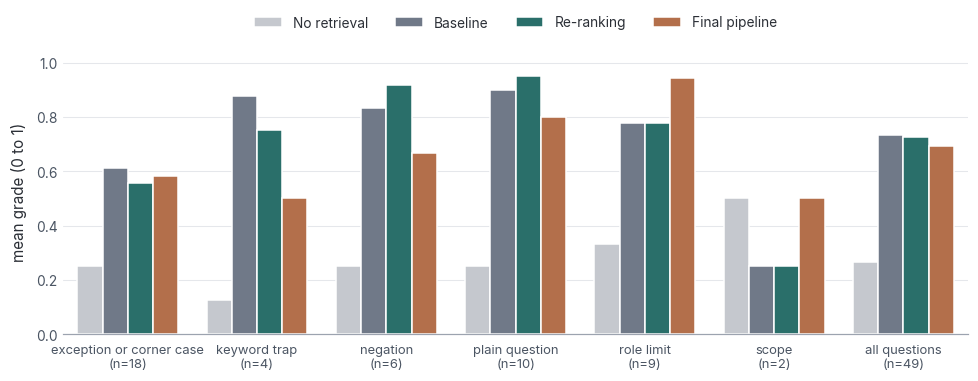

In [60]:
plot_grades_by_mode(by_group, FIG_DIR / "grades_by_mode.png")

### 19.5 Failures that re-ranking fixed or caused, with the kind of mistake

For the questions whose right clause crossed the line into or out of the top 3, the table gives the grade and the kind of mistake for the baseline answer and for the re-ranked answer. This is the comparison the assignment asks for: did the baseline omit an essential clause, misstate a rule, or make something up, because the critical chunk sat outside the top 3?

**`answer_comparison(qids)`**

Grade and kind of mistake of the baseline answer and the re-ranked answer for the given questions.

In [61]:
def answer_comparison(qids):
    """Grade and kind of mistake of the baseline answer and the re-ranked answer for the given questions."""
    rows = []
    for qid in qids:
        b = answers_long[(answers_long["id"] == qid) & (answers_long["mode"] == "Baseline")].iloc[0]
        r = answers_long[(answers_long["id"] == qid) & (answers_long["mode"] == "Re-ranking")].iloc[0]
        rows.append({"question": qid, "right clause rank": f"{rank_shifts.loc[qid, 'gold_rank_baseline']} -> {rank_shifts.loc[qid, 'gold_rank_reranked']}",
                     "baseline grade": b["grade_main"], "baseline mistake": b["error_main"],
                     "re-ranked grade": r["grade_main"], "re-ranked mistake": r["error_main"], "baseline reason": b["reason_main"]})
    return pd.DataFrame(rows).set_index("question")

In [62]:
rank_shifts = pd.read_csv(RESULTS_DIR / "rank_shifts.csv").set_index("id")

rank_shifts[["gold_rank_baseline", "gold_rank_reranked"]] = rank_shifts[["gold_rank_baseline", "gold_rank_reranked"]].astype("Int64").astype(str)

fixed_ids = ["Q16", "Q02", "Q27", "Q47"]

hurt_ids = ["Q20", "Q46", "Q44", "Q23", "Q11"]

print("rescued by re-ranking (right clause moved from rank 4 or 5 into the top 3):")

display(answer_comparison(fixed_ids))

print("made worse, or not helped:")

display(answer_comparison(hurt_ids))

rescued by re-ranking (right clause moved from rank 4 or 5 into the top 3):


,right clause rank,baseline grade,baseline mistake,re-ranked grade,re-ranked mistake,baseline reason
question,,,,,,
Q16,4 -> 1,0.0,misstates the rule,0.5,omits an essential clause,"The answer incorrectly states that the importer must ensure the system is not in conformity, whereas the law require..."
Q02,4 -> 2,0.5,omits an essential clause,1.0,none,The answer does not specify that the prohibition applies to 'untargeted scraping' as required by the law text.
Q27,5 -> 2,0.5,omits an essential clause,0.5,omits an essential clause,The answer correctly states the prohibition but omits the exception for labelling or filtering of lawfully acquired ...
Q47,5 -> 2,1.0,none,1.0,none,The answer correctly states that AI systems used for detecting financial fraud are specifically excluded from the hi...


made worse, or not helped:


,right clause rank,baseline grade,baseline mistake,re-ranked grade,re-ranked mistake,baseline reason
question,,,,,,
Q20,1 -> 5,1.0,none,1.0,none,The answer accurately states the rule and includes the exception for when it is obvious to a reasonably well-informe...
Q46,2 -> 9,1.0,none,0.5,omits an essential clause,The answer accurately states the exception allowing police to use real-time remote biometric identification for the ...
Q44,2 -> 4,1.0,none,0.5,omits an essential clause,The answer accurately states that AI systems used as polygraphs or similar tools by law enforcement are classified a...
Q23,<NA> -> <NA>,0.0,misstates the rule,1.0,none,The law requires providers to keep the technical documentation for 10 years after the AI system is placed on the mar...
Q11,1 -> 1,0.0,gave up,0.0,misstates the rule,The law text clearly specifies the maximum fine for start-ups and the answer incorrectly claims the information is n...


### 19.6 Does a better rank give a better answer? And what if the right chunk was already first?

Two checks. First, among the questions where re-ranking moved the right clause up, down, or not at all, how did the grade change? Second, the **reading failures**: questions where the right clause was in the top 3 that the LLM saw, and the answer was still not fully correct. Retrieval cannot fix those.

**`grade_change_by_rank_change()`**

For questions grouped by what re-ranking did to the right clause, count answers that improved, stayed, or got worse.

In [63]:
def grade_change_by_rank_change():
    """For questions grouped by what re-ranking did to the right clause, count answers that improved, stayed, or got worse."""
    rs = pd.read_csv(RESULTS_DIR / "rank_shifts.csv").set_index("id")
    g = answers_long.pivot_table(index="id", columns="mode", values="grade_main")
    change = (g["Re-ranking"] - g["Baseline"]).reindex(rs.index)
    rows = []
    for name, ids in [("right clause moved up", rs.index[rs["rank_shift"] > 0]), ("right clause unchanged", rs.index[rs["rank_shift"] == 0]),
                      ("right clause moved down", rs.index[rs["rank_shift"] < 0]), ("right clause not in top 10", rs.index[rs["gold_rank_baseline"].isna()])]:
        c = change[ids]
        rows.append({"what re-ranking did": name, "questions": len(ids), "answer better": int((c > 0).sum()), "same": int((c == 0).sum()), "worse": int((c < 0).sum())})
    return pd.DataFrame(rows).set_index("what re-ranking did")

In [64]:
display(grade_change_by_rank_change())

,questions,answer better,same,worse
what re-ranking did,,,,
right clause moved up,15,2,13,0
right clause unchanged,15,1,13,1
right clause moved down,8,0,4,4
right clause not in top 10,11,3,7,1


**`reading_failures(mode, rank_col)`**

Questions where the right clause was in the top 3 of this pipeline and the answer was still not fully correct.

In [65]:
def reading_failures(mode, rank_col):
    """Questions where the right clause was in the top 3 of this pipeline and the answer was still not fully correct."""
    rs = pd.read_csv(RESULTS_DIR / "rank_shifts.csv").set_index("id")
    sub = answers_long[answers_long["mode"] == mode].set_index("id")
    ids = [i for i in rs.index if rs.loc[i, rank_col] <= 3 and sub.loc[i, "grade_main"] < 1]
    return sub.loc[ids, ["grade_main", "error_main", "reason_main"]], int((rs[rank_col] <= 3).sum())

In [66]:
for mode, col in [("Baseline", "gold_rank_baseline"), ("Re-ranking", "gold_rank_reranked")]:
    table, n_top3 = reading_failures(mode, col)
    print(f"{mode}: right clause in the top 3 for {n_top3} questions; answer not fully correct for {len(table)} of them")
    display(table)

Baseline: right clause in the top 3 for 31 questions; answer not fully correct for 5 of them


,grade_main,error_main,reason_main
id,,,
Q08,0.5,omits an essential clause,"The answer correctly notes that the transparency obligation is limited for artistic or satirical works, but it incor..."
Q11,0.0,gave up,The law text clearly specifies the maximum fine for start-ups and the answer incorrectly claims the information is n...
Q14,0.5,omits an essential clause,"The answer omits key obligations such as monitoring the system, informing authorities of risks or incidents, keeping..."
Q17,0.5,omits an essential clause,The answer omits that deployers of high-risk AI systems referred to in points 5(b) and (c) of Annex III must also ca...
Q37,0.5,omits an essential clause,"The answer incorrectly states that all high-risk AI systems must comply by 2 August 2030, but the law only requires ..."


Re-ranking: right clause in the top 3 for 32 questions; answer not fully correct for 8 of them


,grade_main,error_main,reason_main
id,,,
Q08,0.5,omits an essential clause,"The answer omits that even for artistic or satirical works, there is still a requirement to disclose the existence o..."
Q11,0.0,misstates the rule,"The answer fails to apply Article 99(6), which states that for start-ups the maximum fine is the lower of EUR 35,000..."
Q14,0.5,omits an essential clause,The answer omits the obligation to keep logs for at least six months and to inform workers and their representatives...
Q16,0.5,omits an essential clause,"The answer incorrectly adds 'if applicable' to the requirement for an authorised representative, whereas the law req..."
Q17,0.5,omits an essential clause,"The answer omits that the requirement applies only to high-risk AI systems referred to in Article 6(2), with excepti..."
Q22,0.5,omits an essential clause,"The answer omits that the right only applies to high-risk AI systems listed in Annex III (excluding point 2), and on..."
Q27,0.5,omits an essential clause,The answer omits that the exception for labelling/filtering applies only to lawfully acquired datasets and does not ...
Q33,0.0,misstates the rule,The law states that disclosure is NOT required if there is human review/editorial control and editorial responsibili...


## 20. Extra measurements for the report

Three small additions that complete the comparison between a bi-encoder and a cross-encoder.

**The two scoring functions.** With a MiniLM transformer, written out:

$$\text{bi-encoder:}\quad s(q,d)=\cos\big(E(q),E(d)\big),\qquad E(x)=\text{mean-pool}\big(\text{MiniLM}(x)\big)$$

$$\text{cross-encoder:}\quad s(q,d)=\mathbf{w}^{\top}\,\mathbf{h}_{[\text{CLS}]}\big(\text{MiniLM}(\texttt{[CLS]}\ q\ \texttt{[SEP]}\ d\ \texttt{[SEP]})\big)$$

**A real example of the two scores.** `score_table` lists, for one question, the bi-encoder cosine and the cross-encoder logit of the candidates. The logit is not a probability, only an order. **Where the ranks move.** `plot_case_ranks` draws the rank of every top-10 chunk before and after re-ranking, one panel per question, with the right clause in colour. **Batching.** Scoring the pairs of many questions together makes better use of the GPU. `batched_rerank_ms` measures the cost per question when all questions are scored in one batch.

**`score_table(qid, n=6)`**

Cosine score and rank from the bi-encoder, and logit and rank from the cross-encoder, for the first candidates of a question.

In [67]:
def score_table(qid, n=6):
    """Cosine score and rank from the bi-encoder, and logit and rank from the cross-encoder, for the first candidates of a question."""
    runs = pd.read_csv(RESULTS_DIR / "retrieval_runs.csv")
    t = runs[runs["query_id"] == qid].sort_values("bi_rank")
    keep = pd.concat([t.head(n), t[t["is_gold"]]]).drop_duplicates("chunk_id").sort_values("bi_rank")
    return keep[["header", "bi_score", "bi_rank", "ce_score", "ce_rank", "is_gold"]].assign(header=lambda d: d["header"].str[:48]).set_index("header")

In [68]:
print(QBY["Q16"]["query"])

display(score_table("Q16"))

What must an importer check before placing a high-risk AI system on the market?


,bi_score,bi_rank,ce_score,ce_rank,is_gold
header,,,,,
"[Article 23 – Obligations of importers, para 2–4",0.7463,1,6.8402,2,False
[Recital 66],0.7053,2,1.3102,10,False
"[Article 23 – Obligations of importers, para 5–7",0.7011,3,6.2316,4,False
"[Article 23 – Obligations of importers, para 1]",0.6795,4,8.1678,1,True
[Article 25 – Responsibilities along the AI valu,0.6749,5,3.5531,8,False
[Article 25 – Responsibilities along the AI valu,0.6539,6,4.5700,7,False


**`plot_case_ranks(qids, path)`**

Small multiples: rank of each top-10 chunk before and after re-ranking. The right clause is in colour.

In [69]:
def plot_case_ranks(qids, path):
    """Small multiples: rank of each top-10 chunk before and after re-ranking. The right clause is in colour."""
    import matplotlib.pyplot as plt
    runs = pd.read_csv(RESULTS_DIR / "retrieval_runs.csv")
    fig, axes = plt.subplots(1, len(qids), figsize=(2.0 * len(qids), 3.6), sharey=True)
    for ax, qid in zip(axes, qids):
        t = runs[runs["query_id"] == qid]
        ax.axhspan(0.5, 3.5, color="#E6F1F0", zorder=0)
        for _, r in t[~t["is_gold"]].iterrows():
            ax.plot([0, 1], [r["bi_rank"], r["ce_rank"]], color="#C4C8CF", lw=1.2, marker="o", ms=3, zorder=1)
        for _, r in t[t["is_gold"]].iterrows():
            ax.plot([0, 1], [r["bi_rank"], r["ce_rank"]], color="#1F7A74" if r["ce_rank"] <= r["bi_rank"] else "#B5483A", lw=2.2, marker="o", ms=5, zorder=3)
        ax.set_title(qid, fontsize=10, loc="left"); ax.set_xticks([0, 1]); ax.set_xticklabels(["baseline", "re-ranked"], fontsize=8)
        ax.set_xlim(-0.25, 1.25); ax.set_ylim(10.6, 0.4)
        for s in ("top", "right"): ax.spines[s].set_visible(False)
    axes[0].set_yticks(range(1, 11)); axes[0].set_ylabel("rank (shaded: top 3, sent to the LLM)", fontsize=8.5)
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

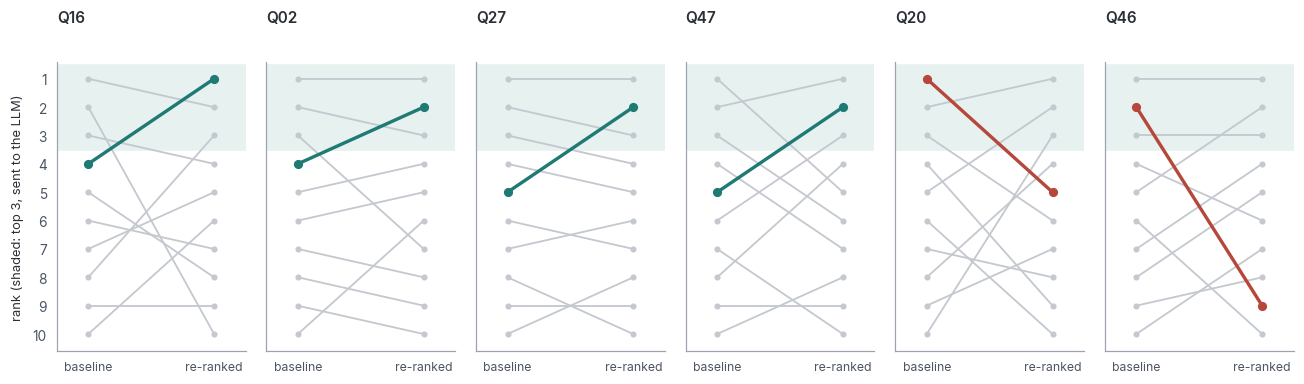

In [70]:
plot_case_ranks(["Q16", "Q02", "Q27", "Q47", "Q20", "Q46"], FIG_DIR / "case_ranks.png")

**`batched_rerank_ms(queries, batch_size=64, repeats=3)`**

Cost per question of bi-encoder search plus cross-encoder re-ranking, one question at a time and with all questions batched.

In [71]:
def batched_rerank_ms(queries, batch_size=64, repeats=3):
    """Cost per question of bi-encoder search plus cross-encoder re-ranking, one question at a time and with all questions batched."""
    import torch
    from sentence_transformers import SentenceTransformer, CrossEncoder
    bi, ce = SentenceTransformer(BI_ENCODER, device=DEVICE), CrossEncoder(CROSS_ENCODER, device=DEVICE, max_length=512)
    texts = [c["text"] for c in CHUNKS]
    emb = bi.encode(texts, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
    sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)

    def one_by_one():
        for q in queries:
            top = np.argsort(-(emb @ bi.encode([q], normalize_embeddings=True, show_progress_bar=False)[0]))[:10]
            ce.predict([(q, texts[i]) for i in top], batch_size=batch_size, show_progress_bar=False)

    def all_at_once():
        qv = bi.encode(queries, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
        tops = np.argsort(-(qv @ emb.T), axis=1)[:, :10]
        ce.predict([(q, texts[i]) for q, top in zip(queries, tops) for i in top], batch_size=batch_size, show_progress_bar=False)

    out = {}
    for name, fn in [("one question at a time", one_by_one), ("all questions batched", all_at_once)]:
        fn(); sync()                                      # warm-up
        times = []
        for _ in range(repeats):
            sync(); t0 = time.perf_counter(); fn(); sync(); times.append((time.perf_counter() - t0) * 1000 / len(queries))
        out[name] = round(float(np.median(times)), 2)
    return out

In [72]:
batched = batched_rerank_ms([q["query"] for q in QUERIES])

print("ms per question, bi-encoder search + cross-encoder re-ranking of 10 pairs:", batched)

pd.Series(batched, name="ms per question").to_csv(RESULTS_DIR / "batched_latency.csv")

ms per question, bi-encoder search + cross-encoder re-ranking of 10 pairs: {'one question at a time': 19.09, 'all questions batched': 11.2}
